# Exploratory Data Analysis & Data Cleaning Assignment

**Datasets:** (1) Loan Eligibility, (2) Adult Census Income, (3) Hotel Booking
**Libraries:** Pandas, NumPy, Matplotlib, Seaborn

Every dataset follows the same workflow:

1. **Load & overview**: shape, dtypes, summary statistics
2. **Data-quality audit**: missing values, duplicates, invalid / inconsistent values
3. **Data cleaning**: each fix is documented and logged
4. **Column-by-column EDA**: *every* column gets its own analysis, plots and cleaning note
5. **Multivariate analysis**: correlations and relationships between columns
6. **Key findings & export of the cleaned data**

> Put `loan-train.csv`, `adult.csv` and `hotel_booking.csv` in the same folder as this notebook (or change the paths in the next cell).

## 0. Setup & helper functions

In [1]:
import warnings
warnings.filterwarnings('ignore')
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10})
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

LOAN_PATH  = 'data/loan-train.csv'
ADULT_PATH = 'data/adult.csv'
HOTEL_PATH = 'data/hotel_booking.csv'
BLUE, ORANGE = '#4C72B0', '#DD8452'

In [2]:
# ---------- generic helper functions used for all three datasets ----------
def overview(df, name):
    print(f'{name}: {df.shape[0]:,} rows x {df.shape[1]} columns')
    print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB\n')
    display(df.head())
    print('\n--- df.info() ---')
    df.info()
    print('\n--- Numeric summary ---')
    display(df.describe().T)
    cat_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
    if cat_cols:
        print('\n--- Non-numeric summary ---')
        display(df[cat_cols].describe().T)

def missing_report(df, title='Missing values per column'):
    m = df.isna().sum()
    rep = pd.DataFrame({'missing': m, 'percent': m / len(df) * 100})
    rep = rep[rep['missing'] > 0].sort_values('missing', ascending=False)
    if rep.empty:
        print('No missing values.')
        return rep
    display(rep)
    fig, ax = plt.subplots(figsize=(8, max(2.5, 0.4 * len(rep))))
    sns.barplot(x=rep['percent'], y=rep.index, color=BLUE, orient='h', ax=ax)
    for i, v in enumerate(rep['percent']):
        ax.text(v + 0.3, i, f'{v:.1f}%', va='center')
    ax.set_xlabel('% missing'); ax.set_title(title)
    plt.tight_layout(); plt.show()
    return rep

def iqr_cap(df, col, new_col=None, floor=None):
    """Cap outliers using the 1.5*IQR rule; the original column is kept untouched."""
    s = df[col]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    if floor is not None: lo = max(lo, floor)
    new_col = new_col or col + '_capped'
    n = int(((s < lo) | (s > hi)).sum())
    df[new_col] = s.clip(lo, hi)
    return {'column': col, 'method': 'IQR 1.5x', 'lower': lo, 'upper': hi, 'values_capped': n, 'new_column': new_col}

def winsor(df, col, lower=.01, upper=.99, new_col=None):
    """Percentile capping (winsorizing); the original column is kept untouched."""
    s = df[col]
    lo, hi = s.quantile(lower), s.quantile(upper)
    new_col = new_col or col + '_capped'
    n = int(((s < lo) | (s > hi)).sum())
    df[new_col] = s.clip(lo, hi)
    return {'column': col, 'method': f'{int(lower*100)}-{int(upper*100)} percentile', 'lower': lo, 'upper': hi, 'values_capped': n, 'new_column': new_col}

def num_profile(df, col, target=None, raw=None, capped=None, show_log=None):
    """Numeric column: statistics table, histogram, boxplot, optional log / capped / target panels + auto insights."""
    s = df[col].dropna()
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((s < lo) | (s > hi)).sum())
    zero_pct = (s == 0).mean() * 100
    summary = pd.DataFrame({'count': [s.count()], 'missing': [df[col].isna().sum()], 'unique': [s.nunique()],
                            'mean': [s.mean()], 'median': [s.median()], 'std': [s.std()], 'min': [s.min()],
                            'max': [s.max()], 'skew': [s.skew()], 'kurtosis': [s.kurt()]}, index=[col])
    display(summary)
    if s.nunique() <= 25:
        print('Value counts:'); display(s.value_counts().sort_index().head(12).to_frame('count').T)
    do_log = ((s.min() >= 0) and (abs(s.skew()) > 1)) if show_log is None else show_log
    panels = ['hist', 'box'] + (['log'] if do_log else []) + (['capped'] if capped else []) + (['target'] if target else [])
    ncols = min(3, len(panels)); nrows = int(np.ceil(len(panels) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.3 * ncols, 3.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, p in zip(axes, panels):
        if p == 'hist':
            if s.nunique() <= 30: sns.histplot(s, discrete=True, color=BLUE, ax=ax)
            else: sns.histplot(s, bins=40, kde=True, color=BLUE, ax=ax)
            ax.axvline(s.mean(), color='red', ls='--', lw=1.2, label=f'mean {s.mean():,.1f}')
            ax.axvline(s.median(), color='green', ls='-.', lw=1.2, label=f'median {s.median():,.1f}')
            ax.legend(fontsize=8); ax.set_title(f'Distribution of {col}')
        elif p == 'box':
            sns.boxplot(x=s, color=BLUE, ax=ax); ax.set_title(f'Boxplot of {col}')
        elif p == 'log':
            sns.histplot(np.log1p(s), bins=40, kde=True, color=ORANGE, ax=ax); ax.set_title(f'log(1 + {col})')
        elif p == 'capped':
            sns.boxplot(x=df[capped], color='#55A868', ax=ax); ax.set_title(f'After outlier capping ({capped})')
        elif p == 'target':
            sns.boxplot(data=df, x=target, y=col, palette=[BLUE, ORANGE][:df[target].nunique()], ax=ax)
            ax.set_title(f'{col} by {target}')
    for ax, p_ in zip(axes, panels):
        if p_ in ('hist', 'box', 'log', 'capped'): ax.tick_params(axis='x', labelrotation=30)
    for ax in axes[len(panels):]: ax.axis('off')
    plt.tight_layout(); plt.show()
    sk = s.skew()
    if abs(sk) < .5: sk_txt = 'approximately symmetric'
    else: sk_txt = ('moderately ' if abs(sk) < 1 else 'highly ') + 'skewed to the ' + ('right' if sk > 0 else 'left')
    print('INSIGHTS')
    print(f'  - Distribution is {sk_txt} (skew = {sk:.2f}); mean = {s.mean():,.2f}, median = {s.median():,.2f}.')
    print(f'  - {n_out:,} IQR outliers ({100 * n_out / len(s):.2f}%) outside [{lo:,.2f}, {hi:,.2f}].')
    if zero_pct > 5: print(f'  - {zero_pct:.1f}% of the values are exactly 0.')
    if target is not None:
        med = df.groupby(target)[col].median()
        print(f'  - Median of {col} by {target}: ' + ', '.join(f'{k} = {v:,.2f}' for k, v in med.items()) + '.')
    if raw is not None and col in raw.columns:
        print(f'  - Missing values: raw = {int(raw[col].isna().sum()):,} -> cleaned = {int(df[col].isna().sum()):,}.')

def cat_profile(df, col, target=None, positive=None, top=12, order=None, raw=None, min_count=30):
    """Categorical column: frequency table, count bar, donut (<=6 categories), target-rate bar + auto insights."""
    vc = df[col].value_counts(dropna=False)
    tbl = pd.DataFrame({'count': vc, 'percent': vc / len(df) * 100})
    display(tbl.head(top))
    if len(vc) > top: print(f'... {len(vc) - top} more categories not shown (total unique = {len(vc)}).')
    s = df[col].dropna()
    cats = list(order) if order is not None else list(s.value_counts().index[:top])
    sub = df[df[col].isin(cats)]
    horizontal = len(cats) > 6 or max(len(str(c)) for c in cats) > 11
    panels = ['count'] + (['pie'] if s.nunique() <= 6 else []) + (['rate'] if target is not None else [])
    fig, axes = plt.subplots(1, len(panels), figsize=(5.6 * len(panels), max(3.8, 0.34 * len(cats) + 1.5) if horizontal else 3.9))
    axes = np.atleast_1d(axes)
    for ax, p in zip(axes, panels):
        if p == 'count':
            if horizontal: sns.countplot(data=sub, y=col, order=cats, color=BLUE, ax=ax)
            else: sns.countplot(data=sub, x=col, order=cats, color=BLUE, ax=ax)
            try: ax.bar_label(ax.containers[0], fontsize=8)
            except Exception: pass
            ax.set_title(f'Count of {col}')
        elif p == 'pie':
            v = s.value_counts()
            ax.pie(v.values, labels=[str(i) for i in v.index], autopct='%1.1f%%', startangle=90, wedgeprops=dict(width=.5))
            ax.set_title(f'Share of {col}')
        elif p == 'rate':
            g = sub.groupby(col)[target].agg(rate=lambda x: (x == positive).mean() * 100, n='size').reindex(cats).dropna()
            g = g[g['n'] >= min_count]
            overall = (df[target] == positive).mean() * 100
            if horizontal:
                sns.barplot(x=g['rate'], y=[str(i) for i in g.index], color=ORANGE, orient='h', ax=ax)
                ax.axvline(overall, color='black', ls='--', lw=1, label=f'overall {overall:.1f}%'); ax.set_xlabel(f'% {target} = {positive}')
            else:
                sns.barplot(x=[str(i) for i in g.index], y=g['rate'], color=ORANGE, ax=ax)
                ax.axhline(overall, color='black', ls='--', lw=1, label=f'overall {overall:.1f}%'); ax.set_ylabel(f'% {target} = {positive}')
            ax.legend(fontsize=8); ax.set_title(f'{target} = {positive} rate by {col}')
    plt.tight_layout(); plt.show()
    print('INSIGHTS')
    shares = s.value_counts(normalize=True) * 100
    print(f'  - {s.nunique()} unique categories; most frequent is "{shares.index[0]}" ({shares.iloc[0]:.1f}%).')
    rare = int((shares < 1).sum())
    if rare: print(f'  - {rare} categories each hold less than 1% of the rows (rare categories).')
    if target is not None:
        g = sub.groupby(col)[target].agg(rate=lambda x: (x == positive).mean() * 100, n='size')
        g = g[g['n'] >= min_count]
        if len(g) > 1:
            print(f'  - Highest {target}={positive} rate: "{g["rate"].idxmax()}" ({g["rate"].max():.1f}%); lowest: "{g["rate"].idxmin()}" ({g["rate"].min():.1f}%).')
    if raw is not None and col in raw.columns:
        print(f'  - Missing values: raw = {int(raw[col].isna().sum()):,} -> cleaned = {int(df[col].isna().sum()):,}.')

def rate_heatmap(df, a, b, target, positive, title=None, min_count=10):
    cnt = pd.crosstab(df[a], df[b])
    rate = df.assign(_t=(df[target] == positive).astype(int)).pivot_table(index=a, columns=b, values='_t', aggfunc='mean') * 100
    rate = rate.where(cnt >= min_count)
    plt.figure(figsize=(1.3 * len(rate.columns) + 3, 0.55 * len(rate) + 2))
    sns.heatmap(rate, annot=True, fmt='.1f', cmap='YlGnBu', cbar_kws={'label': f'% {target} = {positive}'})
    plt.title(title or f'{target} = {positive} rate (%) by {a} and {b}'); plt.tight_layout(); plt.show()

def corr_heatmap(df, cols, title='Correlation matrix'):
    c = df[cols].corr()
    plt.figure(figsize=(0.9 * len(cols) + 3, 0.8 * len(cols) + 2))
    sns.heatmap(c, annot=True, fmt='.2f', cmap='coolwarm', center=0, mask=np.triu(np.ones_like(c, dtype=bool), 1), linewidths=.5)
    plt.title(title); plt.tight_layout(); plt.show()
    return c

---
# PART 1: Loan Eligibility Dataset
**Goal:** understand which applicant characteristics relate to loan approval (`Loan_Status`) and prepare a clean dataset.

## 1.1 Load the data & first look

In [3]:
loan_raw = pd.read_csv(LOAN_PATH)
overview(loan_raw, 'Loan dataset (raw)')

Loan dataset (raw): 1,614 rows x 13 columns
Memory usage: 0.22 MB



,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.000,NaN,360.000,1.000,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,"1,508.000",128.000,360.000,1.000,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.000,66.000,360.000,1.000,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,"2,358.000",120.000,360.000,1.000,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.000,141.000,360.000,1.000,Urban,Y



--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 1614 entries, 0 to 1613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            1614 non-null   str    
 1   Gender             1601 non-null   str    
 2   Married            1611 non-null   str    
 3   Dependents         1599 non-null   str    
 4   Education          1614 non-null   str    
 5   Self_Employed      1582 non-null   str    
 6   ApplicantIncome    1614 non-null   int64  
 7   CoapplicantIncome  1614 non-null   float64
 8   LoanAmount         1592 non-null   float64
 9   Loan_Amount_Term   1600 non-null   float64
 10  Credit_History     1564 non-null   float64
 11  Property_Area      1614 non-null   str    
 12  Loan_Status        1614 non-null   str    
dtypes: float64(4), int64(1), str(8)
memory usage: 221.3 KB

--- Numeric summary ---


,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,"1,614.000","8,746.305","6,249.885",150.000,"3,675.250","7,045.000","13,251.000","81,000.000"
CoapplicantIncome,"1,614.000","3,658.723","3,291.746",0.000,986.250,"2,941.500","5,893.000","41,667.000"
LoanAmount,"1,592.000",218.847,133.623,9.000,112.000,180.000,324.000,700.000
Loan_Amount_Term,"1,600.000",290.475,81.900,12.000,240.000,360.000,360.000,480.000
Credit_History,"1,564.000",0.636,0.481,0.000,0.000,1.000,1.000,1.000



--- Non-numeric summary ---


,count,unique,top,freq
Loan_ID,1614,1538,LP006706,3
Gender,1601,2,Male,980
Married,1611,2,Yes,925
Dependents,1599,4,0,619
Education,1614,2,Graduate,952
Self_Employed,1582,2,No,999
Property_Area,1614,3,Urban,549
Loan_Status,1614,2,Y,915


### Column dictionary
| Column | Meaning |
|---|---|
| Loan_ID | Unique loan application ID |
| Gender | Male / Female |
| Married | Applicant married (Y/N) |
| Dependents | Number of dependents (`3+` = three or more) |
| Education | Graduate / Not Graduate |
| Self_Employed | Self-employed (Y/N) |
| ApplicantIncome | Applicant income |
| CoapplicantIncome | Co-applicant income (0 = no co-applicant income) |
| LoanAmount | Loan amount in thousands |
| Loan_Amount_Term | Loan term in months |
| Credit_History | 1 = credit history meets guidelines, 0 = does not |
| Property_Area | Urban / Semiurban / Rural |
| **Loan_Status** | **Target**: loan approved (Y) or not (N) |

## 1.2 Data-quality audit (before cleaning)

Duplicate rows (all columns identical): 0
Rows whose Loan_ID appears more than once: 151 (1538 unique IDs for 1614 rows)

Column data types:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
dtype,str,str,str,str,str,str,int64,float64,float64,float64,float64,str,str


,missing,percent
Credit_History,50,3.098
Self_Employed,32,1.983
LoanAmount,22,1.363
Dependents,15,0.929
Loan_Amount_Term,14,0.867
Gender,13,0.805
Married,3,0.186


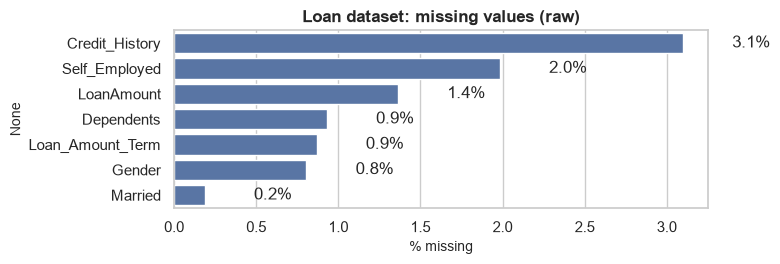

In [4]:
print('Duplicate rows (all columns identical):', loan_raw.duplicated().sum())
print('Rows whose Loan_ID appears more than once:', loan_raw.duplicated('Loan_ID', keep=False).sum(),
      f"({loan_raw['Loan_ID'].nunique()} unique IDs for {len(loan_raw)} rows)")
print('\nColumn data types:'); display(loan_raw.dtypes.to_frame('dtype').T)
rep = missing_report(loan_raw, 'Loan dataset: missing values (raw)')

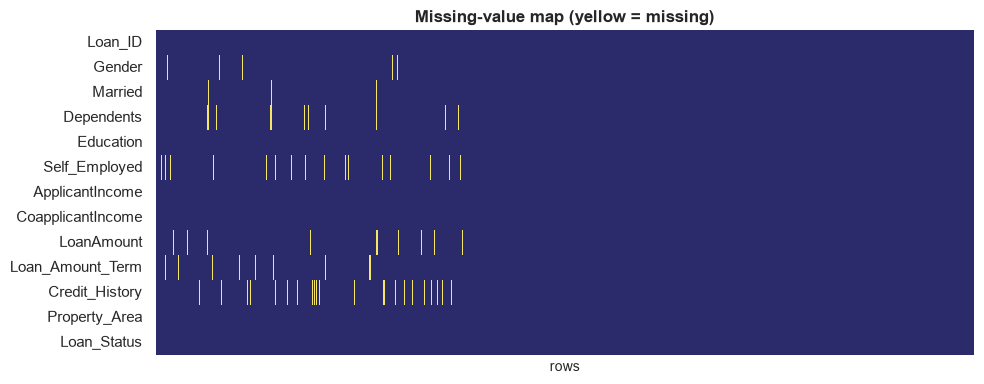

In [5]:
# Missing-value pattern map (yellow = missing)
plt.figure(figsize=(10, 4))
sns.heatmap(loan_raw.isna().T, cbar=False, cmap=['#2b2b6b', '#f5e663'], yticklabels=True, xticklabels=False)
plt.title('Missing-value map (yellow = missing)'); plt.xlabel('rows'); plt.tight_layout(); plt.show()

In [6]:
# Logical / format checks
print('Loan_ID not matching pattern LP + 6 digits:', (~loan_raw['Loan_ID'].astype(str).str.match(r'^LP\d{6}$')).sum())
print('ApplicantIncome <= 0 :', (loan_raw['ApplicantIncome'] <= 0).sum())
print('CoapplicantIncome < 0:', (loan_raw['CoapplicantIncome'] < 0).sum(), '| exactly 0:', (loan_raw['CoapplicantIncome'] == 0).sum())
print('LoanAmount <= 0      :', (loan_raw['LoanAmount'] <= 0).sum())
print('Loan_Amount_Term values:', sorted(loan_raw['Loan_Amount_Term'].dropna().unique()))
for c in ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area', 'Loan_Status', 'Credit_History']:
    print(f'{c:15s}', list(loan_raw[c].unique()))
text_cols = [c for c in loan_raw.columns if not pd.api.types.is_numeric_dtype(loan_raw[c])]
ws = {c: int((loan_raw[c].dropna() != loan_raw[c].dropna().str.strip()).sum()) for c in text_cols}
print('\nValues with leading/trailing whitespace:', ws)

Loan_ID not matching pattern LP + 6 digits: 0
ApplicantIncome <= 0 : 0
CoapplicantIncome < 0: 0 | exactly 0: 273
LoanAmount <= 0      : 0
Loan_Amount_Term values: [np.float64(12.0), np.float64(36.0), np.float64(60.0), np.float64(84.0), np.float64(120.0), np.float64(180.0), np.float64(240.0), np.float64(300.0), np.float64(360.0), np.float64(480.0)]
Gender          ['Male', 'Female', nan]
Married         ['No', 'Yes', nan]
Dependents      ['0', '1', '2', '3+', nan]
Education       ['Graduate', 'Not Graduate']
Self_Employed   ['No', 'Yes', nan]
Property_Area   ['Urban', 'Rural', 'Semiurban']
Loan_Status     ['Y', 'N']
Credit_History  [np.float64(1.0), np.float64(0.0), np.float64(nan)]

Values with leading/trailing whitespace: {'Loan_ID': 0, 'Gender': 0, 'Married': 0, 'Dependents': 0, 'Education': 0, 'Self_Employed': 0, 'Property_Area': 0, 'Loan_Status': 0}


## 1.3 Data cleaning

**Cleaning plan (and why)**

| Issue | Treatment | Reason |
|---|---|---|
| Whitespace in text | `str.strip()` | avoid fake categories |
| Missing `Gender, Married, Dependents, Self_Employed` | mode | small % of missing, categorical |
| Missing `Credit_History` | mode **+ flag column** | binary column; flag keeps the information that it was missing |
| Missing `LoanAmount` | median **+ flag column** | right-skewed, so median is robust |
| Missing `Loan_Amount_Term` | mode (360 months) | dominant value |
| `Dependents` = `3+` | numeric helper `Dependents_num` (3) | enables numeric analysis |
| Repeated `Loan_ID` | flag `Dup_Loan_ID` (rows kept) | repeated IDs have *different* applicant data, so they are not true duplicates |
| Outliers in income / loan amount | IQR capping into `*_capped` columns | originals preserved |
| Target `Y/N` | `Loan_Status_bin` (1/0) | needed for correlations |

In [7]:
loan = loan_raw.copy()
loan_log = []
def log_step(step, detail): loan_log.append({'step': step, 'detail': detail})

# 1) whitespace
for c in [c for c in loan.columns if not pd.api.types.is_numeric_dtype(loan[c])]:
    loan[c] = loan[c].str.strip()
log_step('Strip whitespace', 'text columns')

# 2) flag repeated Loan_IDs (rows kept - applicant details differ)
loan['Dup_Loan_ID'] = loan.duplicated('Loan_ID', keep=False).astype(int)
log_step('Flag repeated Loan_ID', f"{loan['Dup_Loan_ID'].sum()} rows flagged")

# 3) missing indicators first, then imputation
loan['Credit_History_Missing'] = loan['Credit_History'].isna().astype(int)
loan['LoanAmount_Missing'] = loan['LoanAmount'].isna().astype(int)
for c in ['Gender', 'Married', 'Dependents', 'Self_Employed']:
    n = loan[c].isna().sum(); m = loan[c].mode()[0]
    loan[c] = loan[c].fillna(m); log_step(f'Impute {c}', f'{n} missing -> mode = {m}')
n = loan['Credit_History'].isna().sum(); m = loan['Credit_History'].mode()[0]
loan['Credit_History'] = loan['Credit_History'].fillna(m).astype(int); log_step('Impute Credit_History', f'{n} missing -> mode = {m}')
n = loan['LoanAmount'].isna().sum(); m = loan['LoanAmount'].median()
loan['LoanAmount'] = loan['LoanAmount'].fillna(m); log_step('Impute LoanAmount', f'{n} missing -> median = {m}')
n = loan['Loan_Amount_Term'].isna().sum(); m = loan['Loan_Amount_Term'].mode()[0]
loan['Loan_Amount_Term'] = loan['Loan_Amount_Term'].fillna(m).astype(int); log_step('Impute Loan_Amount_Term', f'{n} missing -> mode = {m}')

# 4) type conversions / encodings
loan['Dependents_num'] = loan['Dependents'].replace('3+', '3').astype(int)
loan['Loan_Status_bin'] = loan['Loan_Status'].map({'Y': 1, 'N': 0})
log_step('Encode', 'Dependents_num (3+ -> 3), Loan_Status_bin (Y=1, N=0)')

# 5) outlier capping (IQR rule) - originals kept
cap_log = [iqr_cap(loan, 'ApplicantIncome', floor=0), iqr_cap(loan, 'CoapplicantIncome', floor=0), iqr_cap(loan, 'LoanAmount', floor=0)]
log_step('Cap outliers (IQR)', ', '.join(d['new_column'] for d in cap_log))
display(pd.DataFrame(cap_log))

# 6) feature engineering
loan['Has_Coapplicant'] = (loan['CoapplicantIncome'] > 0).astype(int)
loan['Total_Income'] = loan['ApplicantIncome'] + loan['CoapplicantIncome']
loan['Total_Income_log'] = np.log1p(loan['Total_Income'])
loan['LoanAmount_log'] = np.log1p(loan['LoanAmount'])
loan['EMI'] = loan['LoanAmount'] * 1000 / loan['Loan_Amount_Term']        # LoanAmount is in thousands
loan['Balance_Income'] = loan['Total_Income'] - loan['EMI']
log_step('Feature engineering', 'Has_Coapplicant, Total_Income, Total_Income_log, LoanAmount_log, EMI, Balance_Income')

print('Missing values after cleaning:', int(loan.drop(columns=[]).isna().sum().sum()))
display(pd.DataFrame(loan_log))

,column,method,lower,upper,values_capped,new_column
0,ApplicantIncome,IQR 1.5x,0,"27,614.625",7,ApplicantIncome_capped
1,CoapplicantIncome,IQR 1.5x,0,"13,253.125",4,CoapplicantIncome_capped
2,LoanAmount,IQR 1.5x,0,637.000,2,LoanAmount_capped


Missing values after cleaning: 0


,step,detail
0,Strip whitespace,text columns
1,Flag repeated Loan_ID,151 rows flagged
2,Impute Gender,13 missing -> mode = Male
3,Impute Married,3 missing -> mode = Yes
4,Impute Dependents,15 missing -> mode = 0
5,Impute Self_Employed,32 missing -> mode = No
6,Impute Credit_History,50 missing -> mode = 1.0
7,Impute LoanAmount,22 missing -> median = 180.0
8,Impute Loan_Amount_Term,14 missing -> mode = 360.0
9,Encode,"Dependents_num (3+ -> 3), Loan_Status_bin (Y=1..."


In [8]:
print('Shape before:', loan_raw.shape, '-> after:', loan.shape)
display(loan.head())

Shape before: (1614, 13) -> after: (1614, 27)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Dup_Loan_ID,Credit_History_Missing,LoanAmount_Missing,Dependents_num,Loan_Status_bin,ApplicantIncome_capped,CoapplicantIncome_capped,LoanAmount_capped,Has_Coapplicant,Total_Income,Total_Income_log,LoanAmount_log,EMI,Balance_Income
0,LP001002,Male,No,0,Graduate,No,5849,0.000,180.000,360,1,Urban,Y,0,0,1,0,1,"5,849.000",0.000,180.000,0,"5,849.000",8.674,5.198,500.000,"5,349.000"
1,LP001003,Male,Yes,1,Graduate,No,4583,"1,508.000",128.000,360,1,Rural,N,0,0,0,1,0,"4,583.000","1,508.000",128.000,1,"6,091.000",8.715,4.860,355.556,"5,735.444"
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.000,66.000,360,1,Urban,Y,0,0,0,0,1,"3,000.000",0.000,66.000,0,"3,000.000",8.007,4.205,183.333,"2,816.667"
3,LP001006,Male,Yes,0,Not Graduate,No,2583,"2,358.000",120.000,360,1,Urban,Y,0,0,0,0,1,"2,583.000","2,358.000",120.000,1,"4,941.000",8.506,4.796,333.333,"4,607.667"
4,LP001008,Male,No,0,Graduate,No,6000,0.000,141.000,360,1,Urban,Y,0,0,0,0,1,"6,000.000",0.000,141.000,0,"6,000.000",8.700,4.956,391.667,"5,608.333"


## 1.4 Column-by-column analysis

### 1.4.1 `Loan_ID`
**Description:** Unique application ID (`LP` + 6 digits). Identifier only: no predictive value.

**Cleaning:** Whitespace stripped; repeated IDs flagged in `Dup_Loan_ID`; excluded from modelling.

Unique IDs: 1538 of 1614 | ID prefixes: <ArrowStringArray>
['LP']
Length: 1, dtype: str | ID number range: 1002 - 9996
IDs repeated: 75 | rows involved: 151
Repeated IDs with identical applicant data: 0


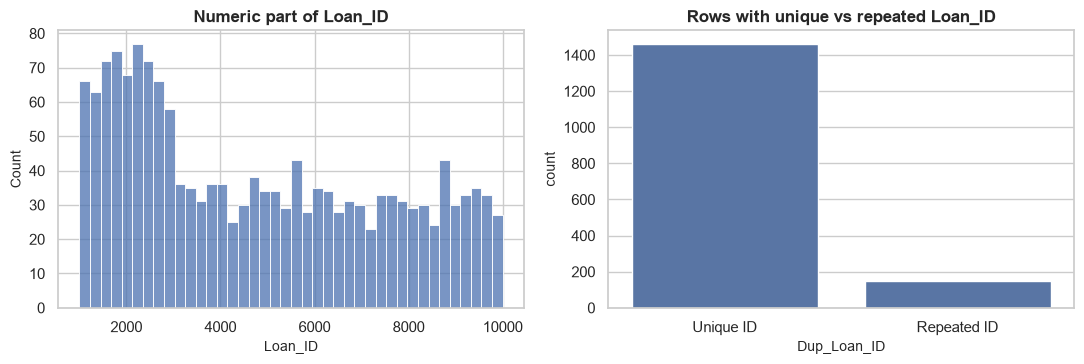

INSIGHTS
  - Loan_ID is just an identifier; some IDs are reused by different applicants (data-entry issue), so it is dropped for modelling.


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Dup_Loan_ID,Credit_History_Missing,LoanAmount_Missing,Dependents_num,Loan_Status_bin,ApplicantIncome_capped,CoapplicantIncome_capped,LoanAmount_capped,Has_Coapplicant,Total_Income,Total_Income_log,LoanAmount_log,EMI,Balance_Income
614,LP003002,Male,Yes,0,Not Graduate,Yes,8295,"6,148.000",330.000,360,0,Urban,Y,1,0,0,0,1,"8,295.000","6,148.000",330.000,1,"14,443.000",9.578,5.802,916.667,"13,526.333"
615,LP003002,Female,Yes,2,Graduate,No,13525,"6,635.000",217.000,180,0,Urban,Y,1,0,0,2,1,"13,525.000","6,635.000",217.000,1,"20,160.000",9.912,5.384,"1,205.556","18,954.444"
618,LP003029,Female,Yes,0,Graduate,Yes,17556,"9,346.000",298.000,180,0,Semiurban,Y,1,0,0,0,1,"17,556.000","9,346.000",298.000,1,"26,902.000",10.200,5.700,"1,655.556","25,246.444"
619,LP003029,Male,Yes,0,Graduate,Yes,6451,"3,274.000",353.000,240,1,Semiurban,N,1,0,0,0,0,"6,451.000","3,274.000",353.000,1,"9,725.000",9.183,5.869,"1,470.833","8,254.167"
631,LP003103,Male,No,2,Not Graduate,No,9952,"8,631.000",458.000,360,1,Urban,Y,1,0,0,2,1,"9,952.000","8,631.000",458.000,1,"18,583.000",9.830,6.129,"1,272.222","17,310.778"
632,LP003103,Female,No,2,Not Graduate,Yes,15868,"5,843.000",245.000,180,0,Urban,Y,1,0,0,2,1,"15,868.000","5,843.000",245.000,1,"21,711.000",9.986,5.505,"1,361.111","20,349.889"


In [9]:
ids = loan['Loan_ID']
num_part = ids.str[2:].astype(int)
print('Unique IDs:', ids.nunique(), 'of', len(ids), '| ID prefixes:', ids.str[:2].unique(), '| ID number range:', num_part.min(), '-', num_part.max())
rep_ids = ids.value_counts(); rep_ids = rep_ids[rep_ids > 1]
print('IDs repeated:', len(rep_ids), '| rows involved:', int(rep_ids.sum()))
print('Repeated IDs with identical applicant data:', int(loan.drop(columns=['Dup_Loan_ID']).duplicated(keep=False).sum()))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(num_part, bins=40, color=BLUE, ax=ax[0]); ax[0].set_title('Numeric part of Loan_ID')
sns.countplot(x=loan['Dup_Loan_ID'].map({0: 'Unique ID', 1: 'Repeated ID'}), color=BLUE, ax=ax[1]); ax[1].set_title('Rows with unique vs repeated Loan_ID')
plt.tight_layout(); plt.show()
print('INSIGHTS\n  - Loan_ID is just an identifier; some IDs are reused by different applicants (data-entry issue), so it is dropped for modelling.')
display(loan[loan['Dup_Loan_ID'] == 1].sort_values('Loan_ID').head(6))

### 1.4.2 `Gender`
**Description:** Applicant gender.

**Cleaning:** Missing values imputed with the mode.

,count,percent
Gender,,
Male,993,61.524
Female,621,38.476


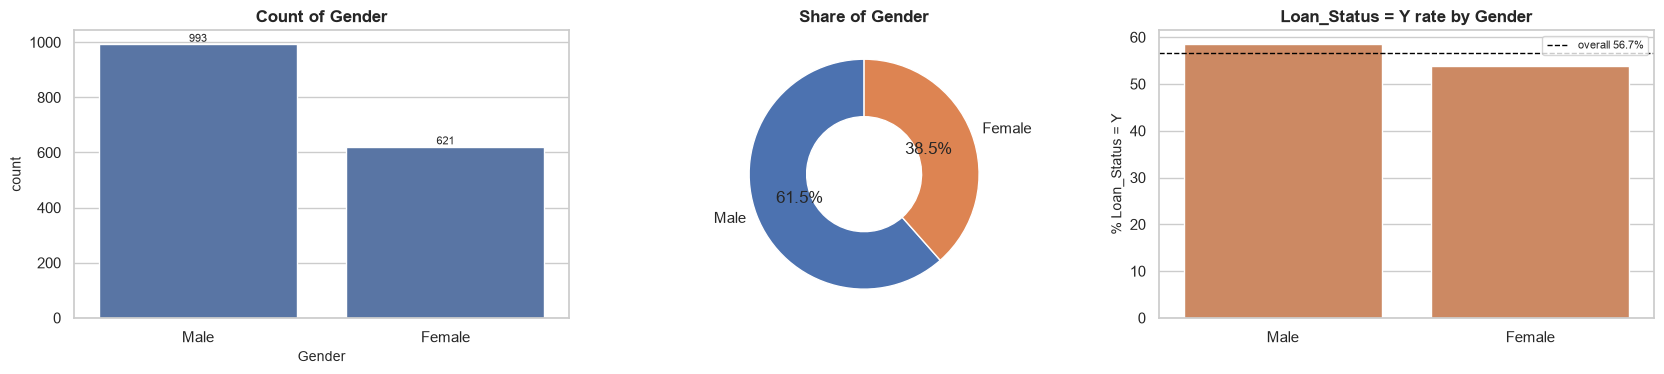

INSIGHTS
  - 2 unique categories; most frequent is "Male" (61.5%).
  - Highest Loan_Status=Y rate: "Male" (58.5%); lowest: "Female" (53.8%).
  - Missing values: raw = 13 -> cleaned = 0.


In [10]:
cat_profile(loan, 'Gender', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.3 `Married`
**Description:** Whether the applicant is married.

**Cleaning:** Missing values imputed with the mode.

,count,percent
Married,,
Yes,928,57.497
No,686,42.503


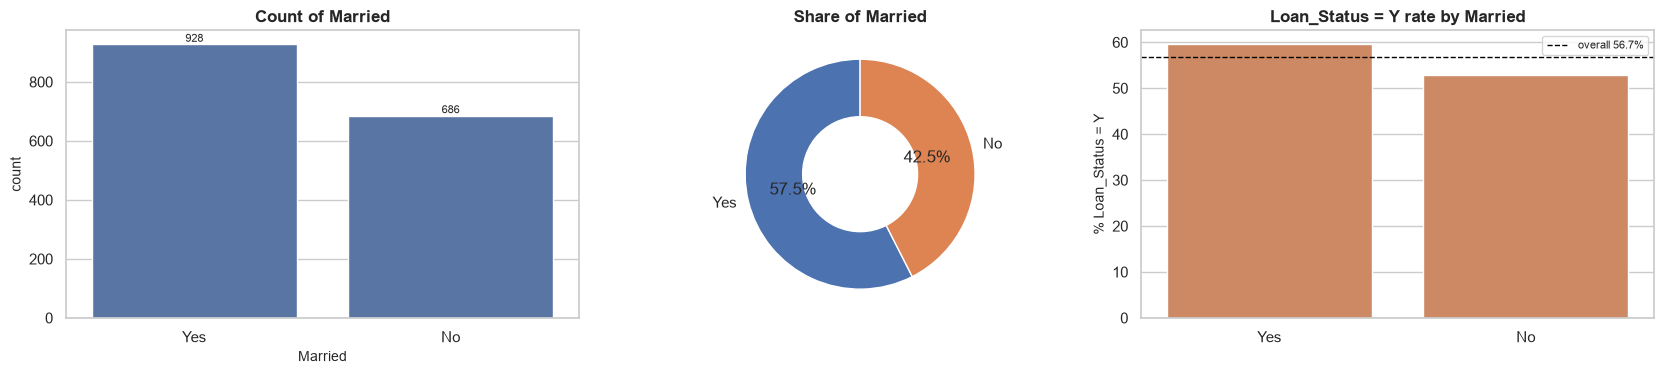

INSIGHTS
  - 2 unique categories; most frequent is "Yes" (57.5%).
  - Highest Loan_Status=Y rate: "Yes" (59.6%); lowest: "No" (52.8%).
  - Missing values: raw = 3 -> cleaned = 0.


In [11]:
cat_profile(loan, 'Married', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.4 `Dependents`
**Description:** Number of people depending on the applicant (`3+` = three or more).

**Cleaning:** Missing imputed with the mode; numeric copy `Dependents_num` created (3+ -> 3).

,count,percent
Dependents,,
0,634,39.281
1,341,21.128
2,336,20.818
3+,303,18.773


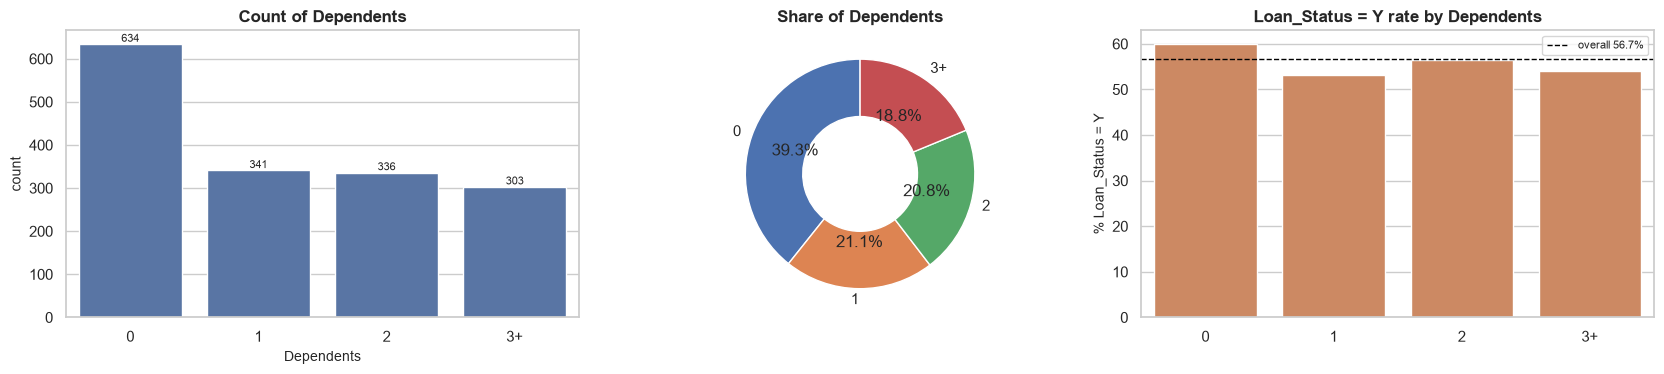

INSIGHTS
  - 4 unique categories; most frequent is "0" (39.3%).
  - Highest Loan_Status=Y rate: "0" (59.9%); lowest: "1" (53.1%).
  - Missing values: raw = 15 -> cleaned = 0.


In [12]:
cat_profile(loan, 'Dependents', target='Loan_Status', positive='Y', raw=loan_raw, order=["0","1","2","3+"])

### 1.4.5 `Education`
**Description:** Applicant education level.

**Cleaning:** No missing values.

,count,percent
Education,,
Graduate,952,58.984
Not Graduate,662,41.016


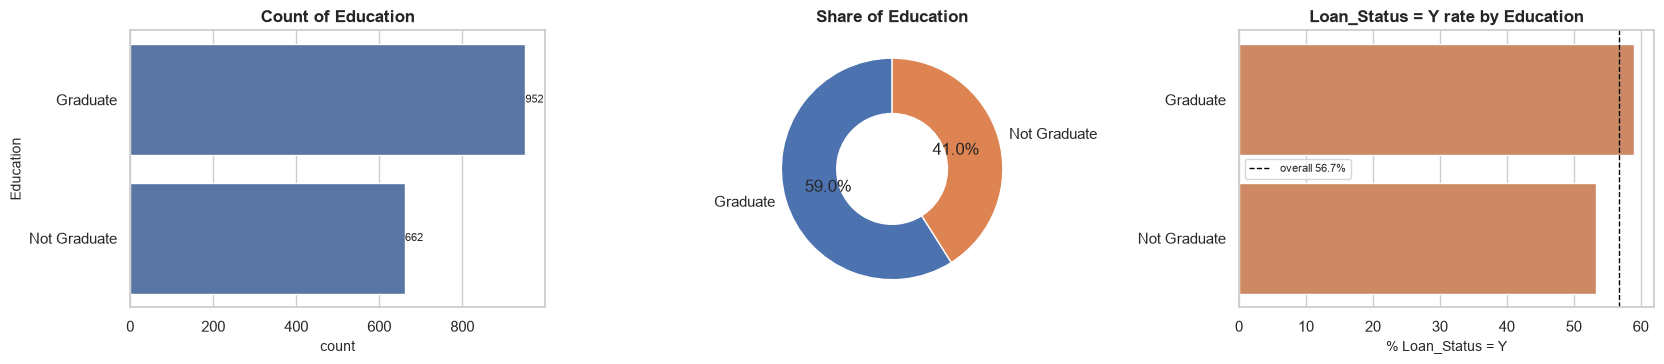

INSIGHTS
  - 2 unique categories; most frequent is "Graduate" (59.0%).
  - Highest Loan_Status=Y rate: "Graduate" (59.0%); lowest: "Not Graduate" (53.3%).
  - Missing values: raw = 0 -> cleaned = 0.


In [13]:
cat_profile(loan, 'Education', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.6 `Self_Employed`
**Description:** Whether the applicant is self-employed.

**Cleaning:** Missing values imputed with the mode.

,count,percent
Self_Employed,,
No,1031,63.879
Yes,583,36.121


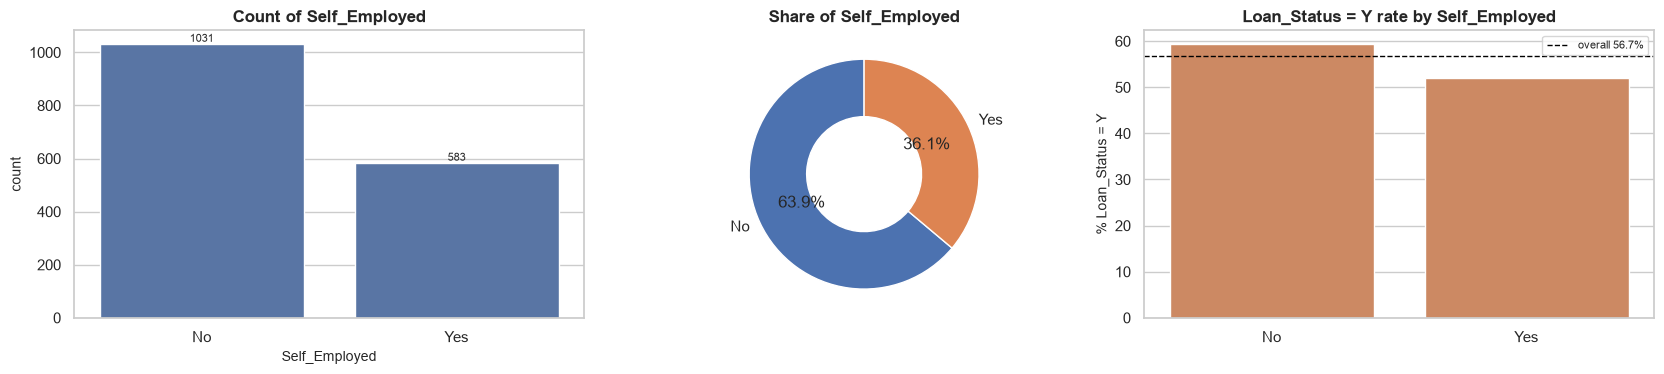

INSIGHTS
  - 2 unique categories; most frequent is "No" (63.9%).
  - Highest Loan_Status=Y rate: "No" (59.4%); lowest: "Yes" (52.0%).
  - Missing values: raw = 32 -> cleaned = 0.


In [14]:
cat_profile(loan, 'Self_Employed', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.7 `ApplicantIncome`
**Description:** Income of the main applicant.

**Cleaning:** No missing values; outliers capped (1.5xIQR) in `ApplicantIncome_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
ApplicantIncome,1614,0,1455,"8,746.305","7,045.000","6,249.885",150,81000,2.164,15.531


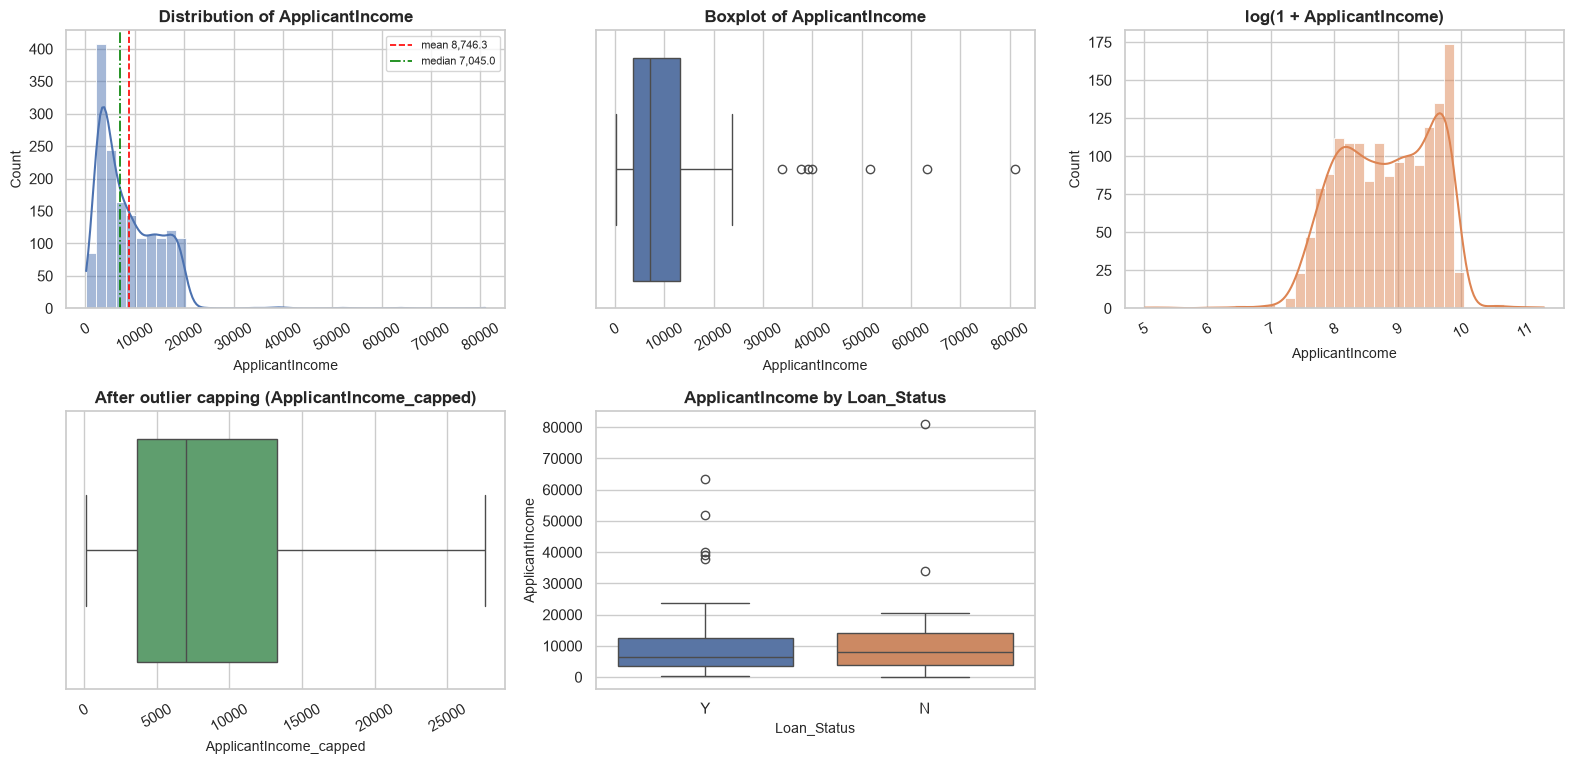

INSIGHTS
  - Distribution is highly skewed to the right (skew = 2.16); mean = 8,746.30, median = 7,045.00.
  - 7 IQR outliers (0.43%) outside [-10,688.38, 27,614.62].
  - Median of ApplicantIncome by Loan_Status: N = 7,900.00, Y = 6,333.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [15]:
num_profile(loan, 'ApplicantIncome', target='Loan_Status', raw=loan_raw, capped="ApplicantIncome_capped")

### 1.4.8 `CoapplicantIncome`
**Description:** Income of the co-applicant (0 = no co-applicant income).

**Cleaning:** No missing values; outliers capped in `CoapplicantIncome_capped`; `Has_Coapplicant` flag created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
CoapplicantIncome,1614,0,1206,"3,658.723","2,941.500","3,291.746",0.000,"41,667.000",1.913,14.607


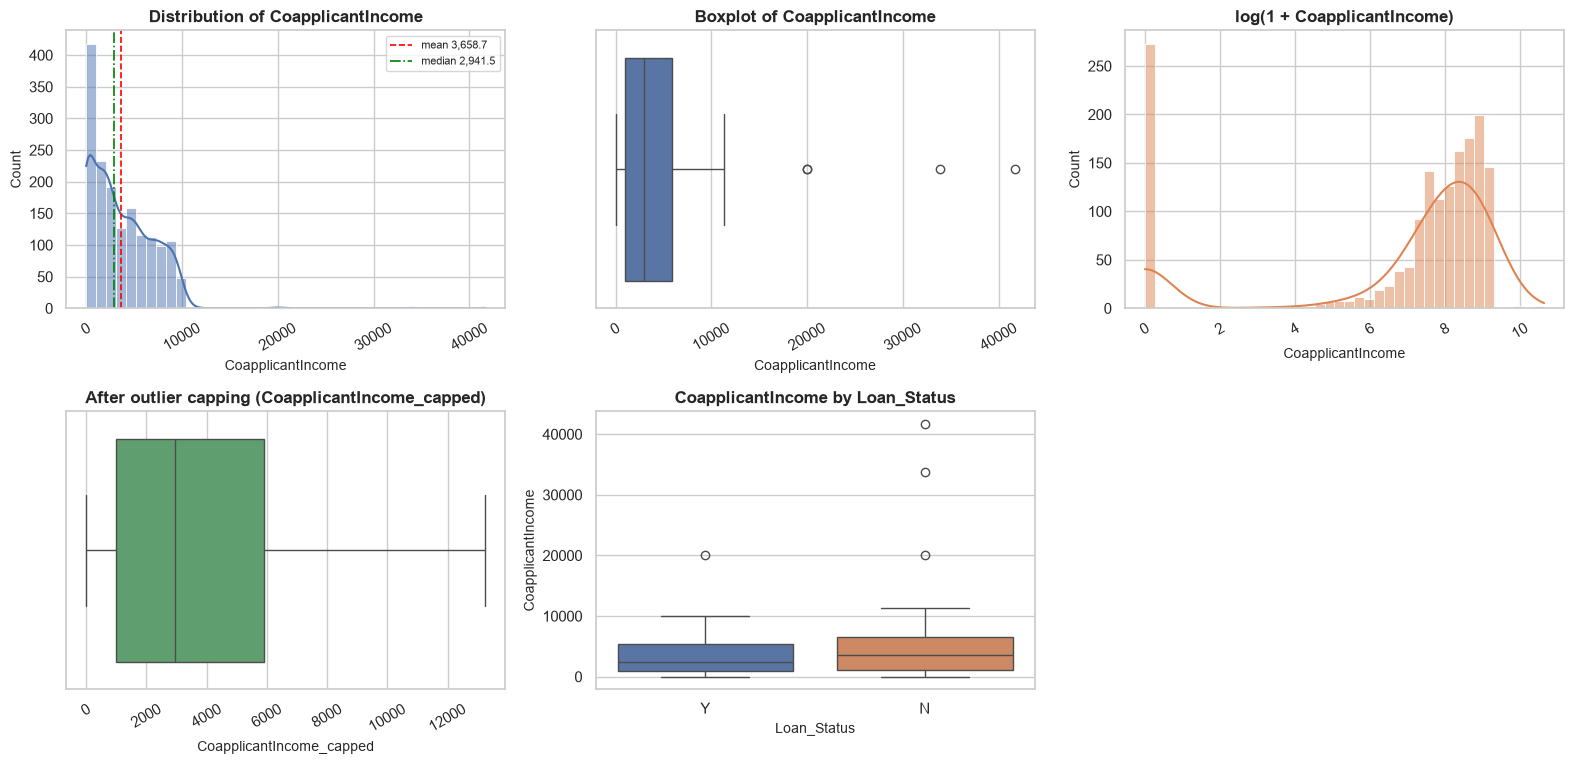

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.91); mean = 3,658.72, median = 2,941.50.
  - 4 IQR outliers (0.25%) outside [-6,373.88, 13,253.12].
  - 16.9% of the values are exactly 0.
  - Median of CoapplicantIncome by Loan_Status: N = 3,548.00, Y = 2,500.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [16]:
num_profile(loan, 'CoapplicantIncome', target='Loan_Status', raw=loan_raw, capped="CoapplicantIncome_capped")

### 1.4.9 `LoanAmount`
**Description:** Requested loan amount (in thousands).

**Cleaning:** Missing values imputed with the median (+ `LoanAmount_Missing` flag); outliers capped in `LoanAmount_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
LoanAmount,1614,0,461,218.317,180.000,132.785,9.000,700.000,0.620,-0.705


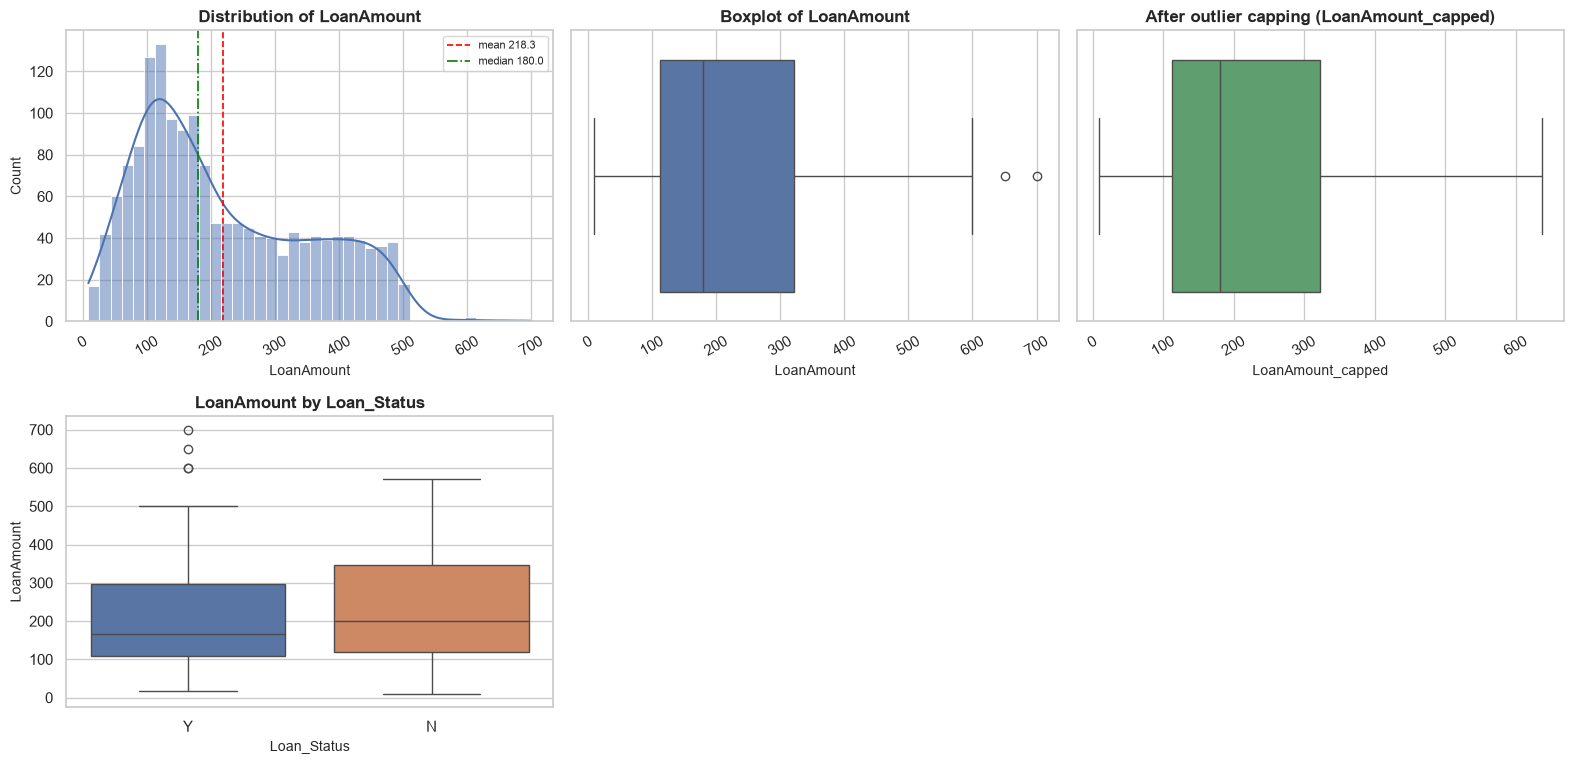

INSIGHTS
  - Distribution is moderately skewed to the right (skew = 0.62); mean = 218.32, median = 180.00.
  - 2 IQR outliers (0.12%) outside [-203.00, 637.00].
  - Median of LoanAmount by Loan_Status: N = 201.00, Y = 165.00.
  - Missing values: raw = 22 -> cleaned = 0.


In [17]:
num_profile(loan, 'LoanAmount', target='Loan_Status', raw=loan_raw, capped="LoanAmount_capped")

### 1.4.10 `Loan_Amount_Term`
**Description:** Loan repayment term in months.

**Cleaning:** Missing values imputed with the mode (360); cast to integer.

,count,percent
Loan_Amount_Term,,
360,859,53.222
180,384,23.792
240,331,20.508
480,15,0.929
300,13,0.805
84,4,0.248
120,3,0.186
60,2,0.124
36,2,0.124


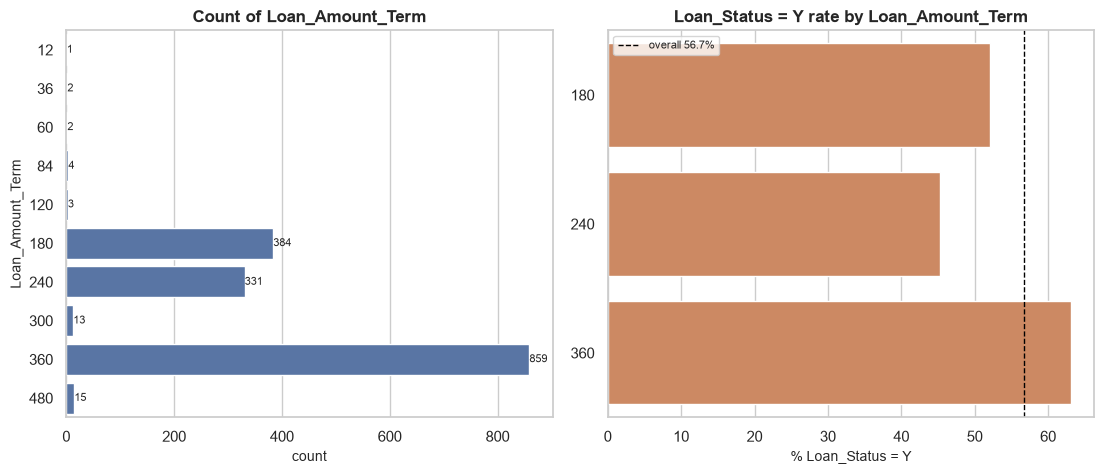

INSIGHTS
  - 10 unique categories; most frequent is "360" (53.2%).
  - 7 categories each hold less than 1% of the rows (rare categories).
  - Highest Loan_Status=Y rate: "360" (63.1%); lowest: "240" (45.3%).
  - Missing values: raw = 14 -> cleaned = 0.


In [18]:
cat_profile(loan, 'Loan_Amount_Term', target='Loan_Status', positive='Y', raw=loan_raw, order=sorted(loan["Loan_Amount_Term"].unique()))

### 1.4.11 `Credit_History`
**Description:** 1 = credit history meets guidelines, 0 = it does not.

**Cleaning:** Missing imputed with the mode (+ `Credit_History_Missing` flag); cast to integer.

,count,percent
Credit_History,,
1,1044,64.684
0,570,35.316


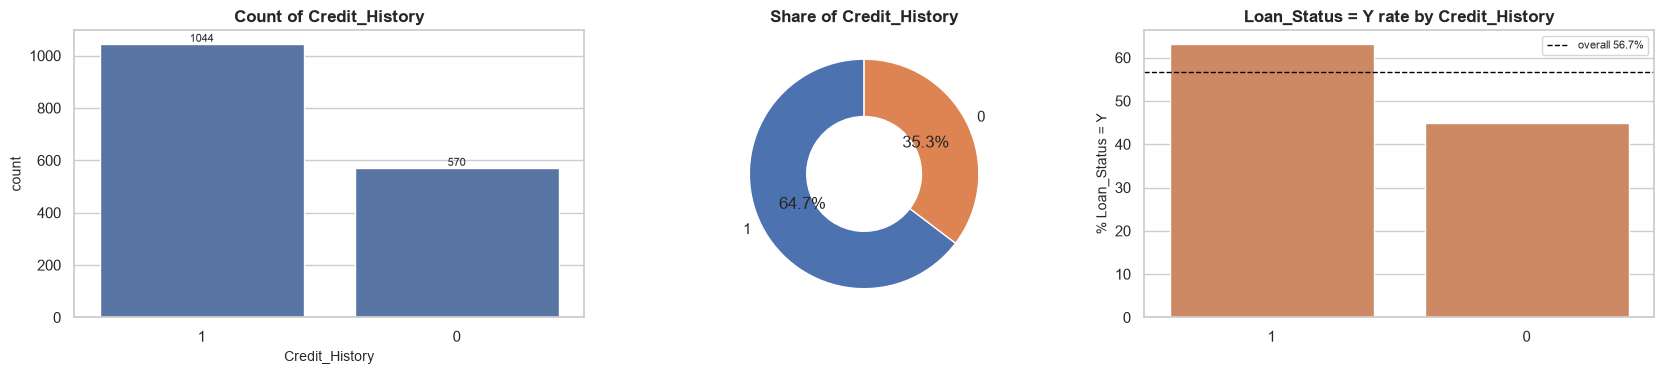

INSIGHTS
  - 2 unique categories; most frequent is "1" (64.7%).
  - Highest Loan_Status=Y rate: "1" (63.1%); lowest: "0" (44.9%).
  - Missing values: raw = 50 -> cleaned = 0.


In [19]:
cat_profile(loan, 'Credit_History', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.12 `Property_Area`
**Description:** Type of area where the property is located.

**Cleaning:** No missing values.

,count,percent
Property_Area,,
Urban,549,34.015
Semiurban,545,33.767
Rural,520,32.218


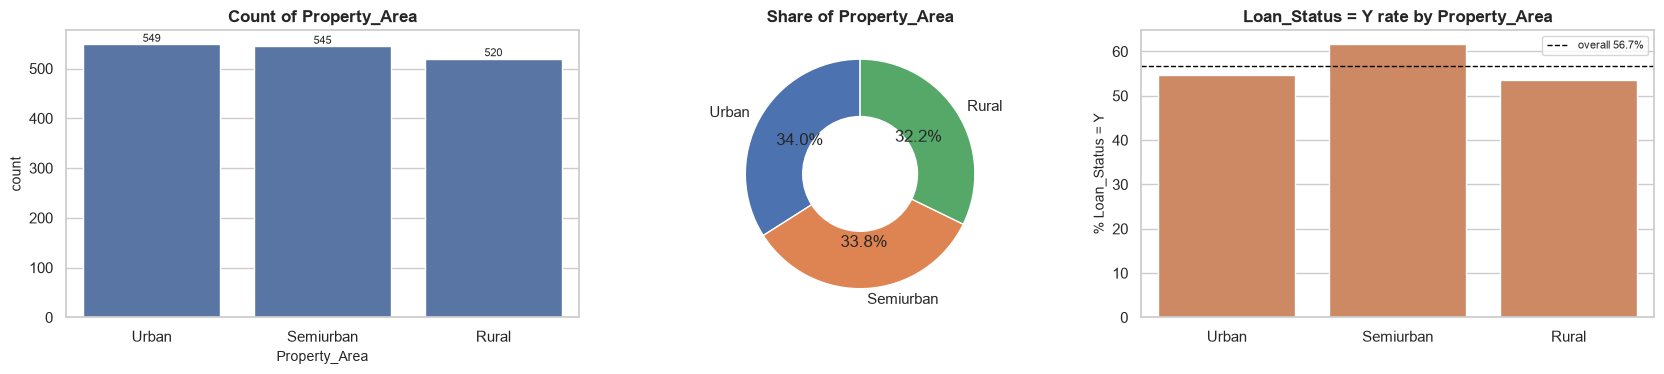

INSIGHTS
  - 3 unique categories; most frequent is "Urban" (34.0%).
  - Highest Loan_Status=Y rate: "Semiurban" (61.7%); lowest: "Rural" (53.7%).
  - Missing values: raw = 0 -> cleaned = 0.


In [20]:
cat_profile(loan, 'Property_Area', target='Loan_Status', positive='Y', raw=loan_raw)

### 1.4.13 `Loan_Status`
**Description:** **Target variable**: loan approved (Y) or rejected (N).

**Cleaning:** No missing values; binary copy `Loan_Status_bin` created.

,count,percent
Loan_Status,,
Y,915,56.691
N,699,43.309


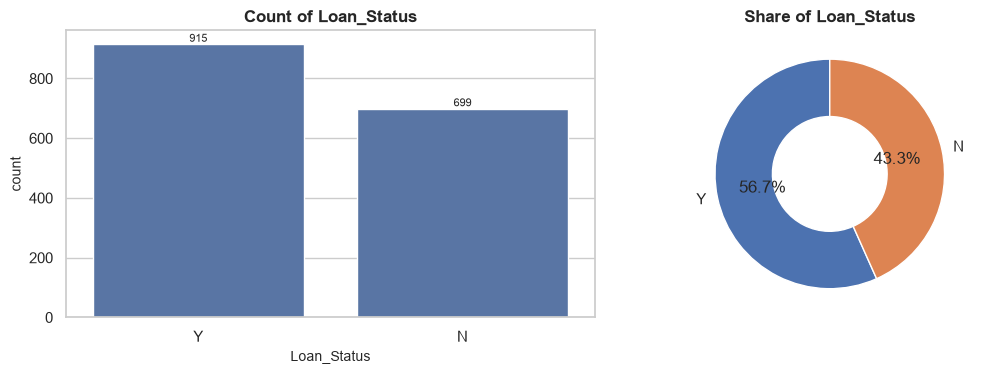

INSIGHTS
  - 2 unique categories; most frequent is "Y" (56.7%).
  - Missing values: raw = 0 -> cleaned = 0.
  - Class balance: approved (Y) = 56.7%, rejected (N) = 43.3%.


In [21]:
cat_profile(loan, 'Loan_Status', raw=loan_raw)
print(f"  - Class balance: approved (Y) = {(loan['Loan_Status']=='Y').mean()*100:.1f}%, rejected (N) = {(loan['Loan_Status']=='N').mean()*100:.1f}%.")

### 1.4.14 Engineered features

`Total_Income`, `EMI` and `Balance_Income` combine the raw columns into more meaningful quantities.

============================== Total_Income


,count,missing,unique,mean,median,std,min,max,skew,kurtosis
Total_Income,1614,0,1514,"12,405.028","11,169.500","7,534.536","1,442.000","81,000.000",1.234,5.206


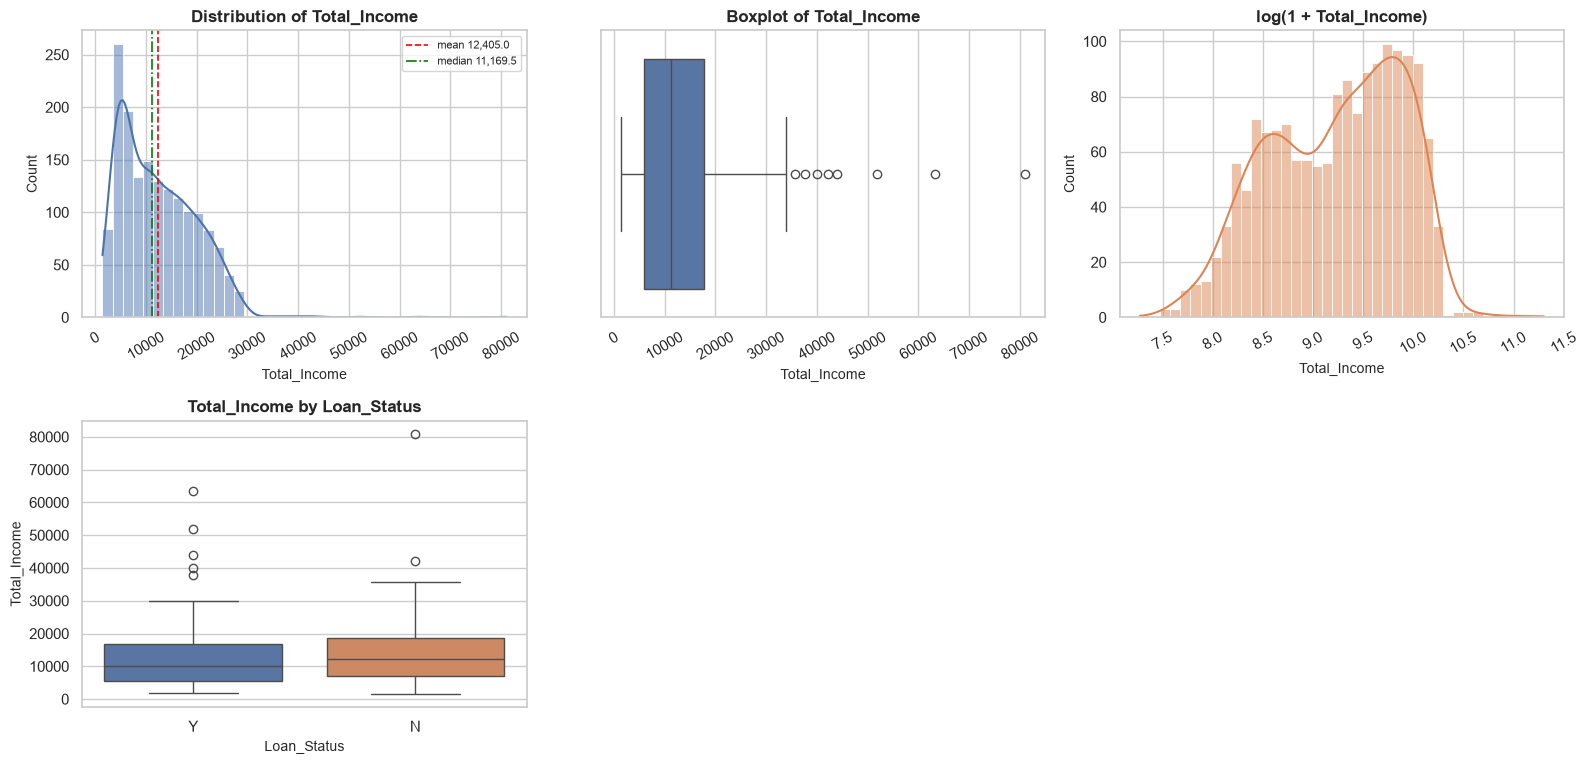

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.23); mean = 12,405.03, median = 11,169.50.
  - 8 IQR outliers (0.50%) outside [-11,780.50, 35,367.50].
  - Median of Total_Income by Loan_Status: N = 12,291.00, Y = 10,082.00.
============================== EMI


,count,missing,unique,mean,median,std,min,max,skew,kurtosis
EMI,1614,0,683,862.568,633.333,684.479,25.000,"9,250.000",2.045,13.870


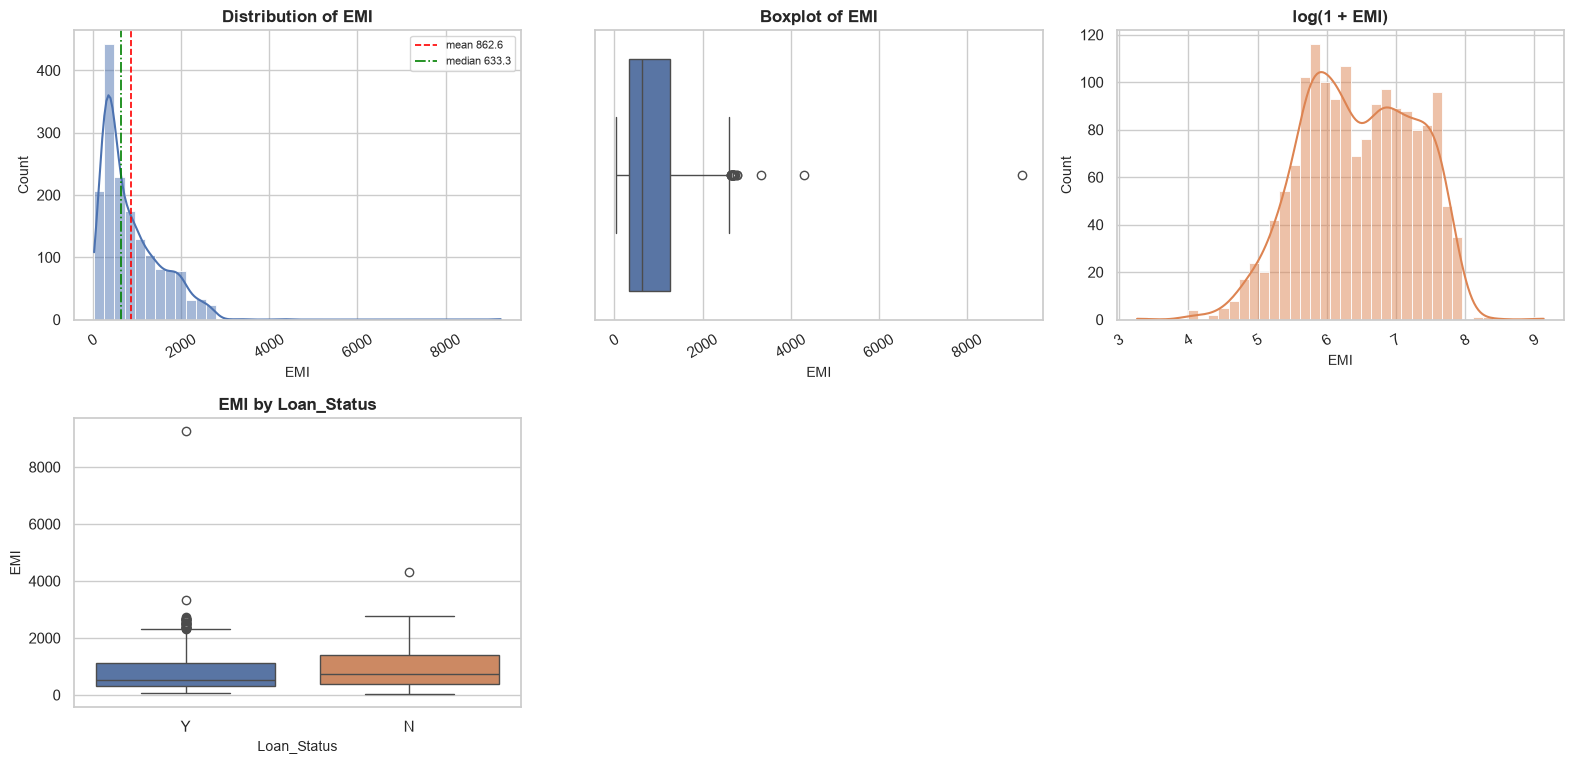

INSIGHTS
  - Distribution is highly skewed to the right (skew = 2.04); mean = 862.57, median = 633.33.
  - 20 IQR outliers (1.24%) outside [-1,039.24, 2,635.76].
  - Median of EMI by Loan_Status: N = 745.83, Y = 522.22.
============================== Balance_Income


,count,missing,unique,mean,median,std,min,max,skew,kurtosis
Balance_Income,1614,0,1605,"11,542.460","10,080.722","7,344.297","-1,768.000","80,000.000",1.308,5.624


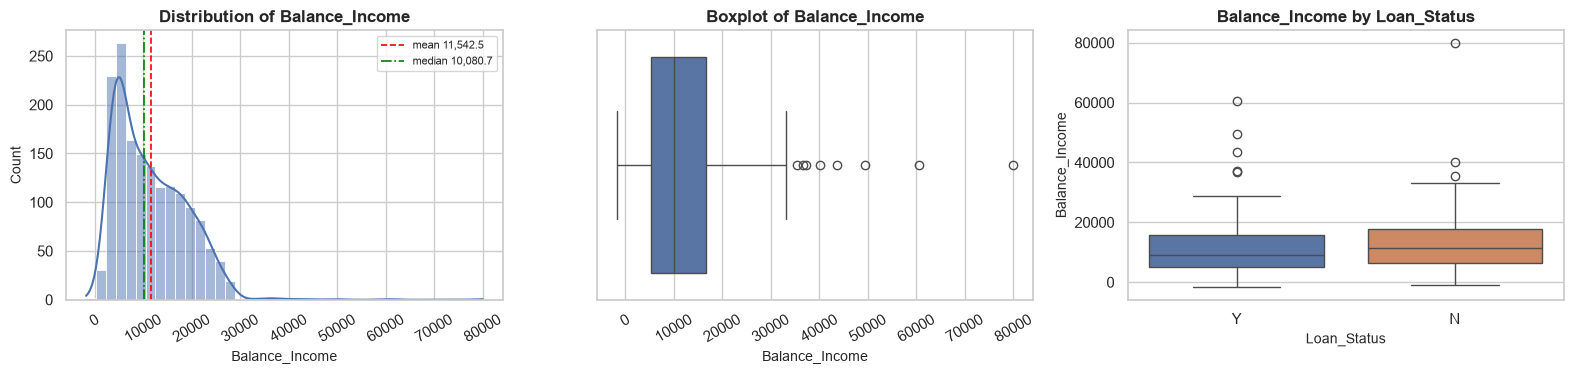

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.31); mean = 11,542.46, median = 10,080.72.
  - 8 IQR outliers (0.50%) outside [-11,651.67, 33,715.00].
  - Median of Balance_Income by Loan_Status: N = 11,292.56, Y = 9,234.00.


,count,percent
Has_Coapplicant,,
1,1341,83.086
0,273,16.914


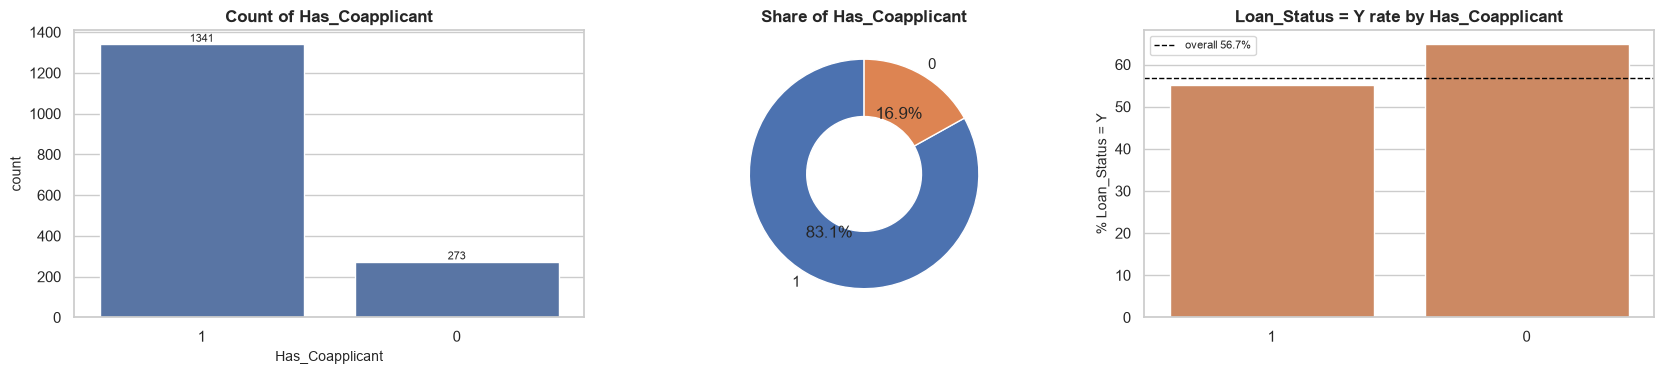

INSIGHTS
  - 2 unique categories; most frequent is "1" (83.1%).
  - Highest Loan_Status=Y rate: "0" (64.8%); lowest: "1" (55.0%).


,count,percent
Dependents_num,,
0,634,39.281
1,341,21.128
2,336,20.818
3,303,18.773


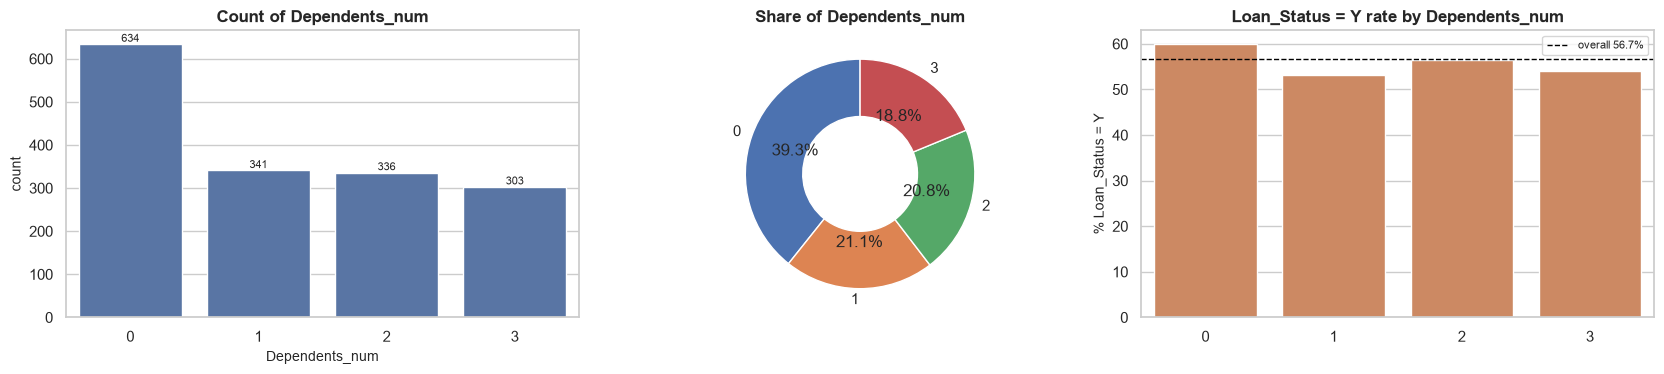

INSIGHTS
  - 4 unique categories; most frequent is "0" (39.3%).
  - Highest Loan_Status=Y rate: "0" (59.9%); lowest: "1" (53.1%).


In [22]:
for c in ['Total_Income', 'EMI', 'Balance_Income']:
    print('=' * 30, c)
    num_profile(loan, c, target='Loan_Status')
cat_profile(loan, 'Has_Coapplicant', target='Loan_Status', positive='Y')
cat_profile(loan, 'Dependents_num', target='Loan_Status', positive='Y', order=[0, 1, 2, 3])

## 1.5 Multivariate analysis

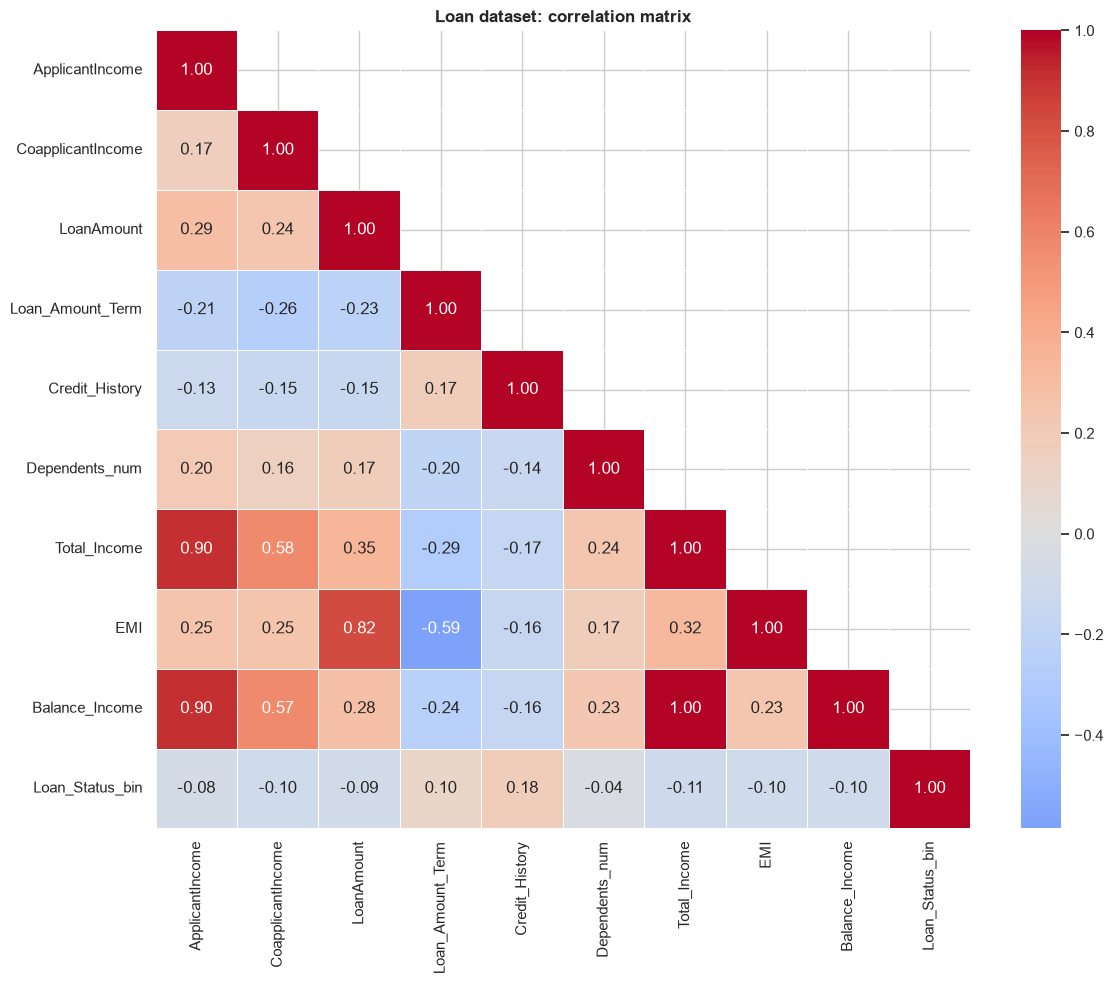

Correlation with Loan_Status_bin:


,corr
Credit_History,0.176
Loan_Amount_Term,0.104
Dependents_num,-0.040
ApplicantIncome,-0.077
LoanAmount,-0.089
EMI,-0.098
CoapplicantIncome,-0.098
Balance_Income,-0.101
Total_Income,-0.107


In [23]:
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Dependents_num',
            'Total_Income', 'EMI', 'Balance_Income', 'Loan_Status_bin']
corr_loan = corr_heatmap(loan, num_cols, 'Loan dataset: correlation matrix')
print('Correlation with Loan_Status_bin:'); display(corr_loan['Loan_Status_bin'].drop('Loan_Status_bin').sort_values(ascending=False).to_frame('corr'))

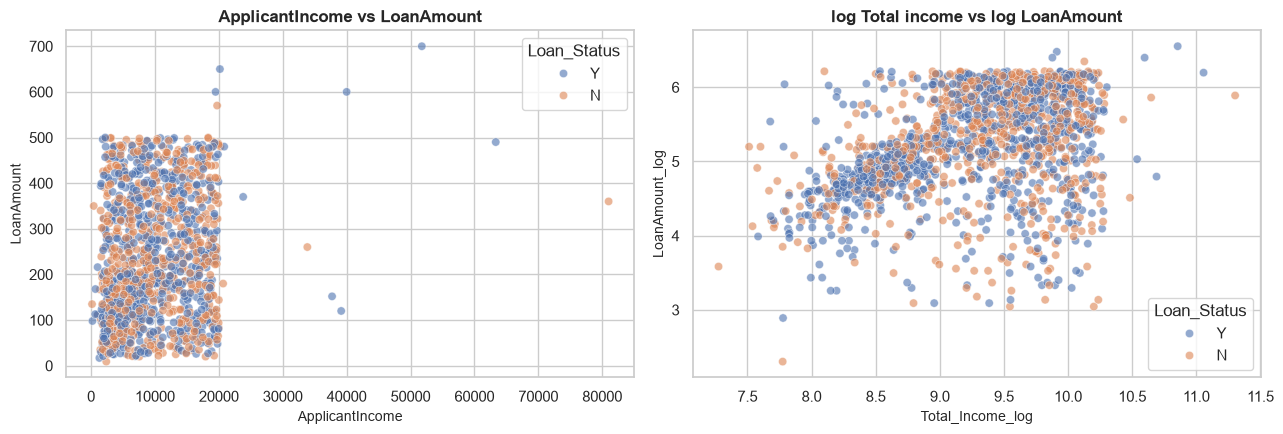

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.scatterplot(data=loan, x='ApplicantIncome', y='LoanAmount', hue='Loan_Status', alpha=.6, ax=ax[0]); ax[0].set_title('ApplicantIncome vs LoanAmount')
sns.scatterplot(data=loan, x='Total_Income_log', y='LoanAmount_log', hue='Loan_Status', alpha=.6, ax=ax[1]); ax[1].set_title('log Total income vs log LoanAmount')
plt.tight_layout(); plt.show()

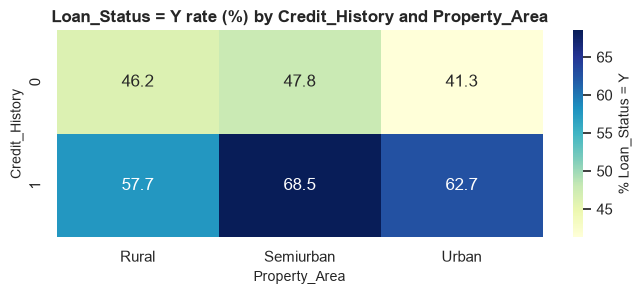

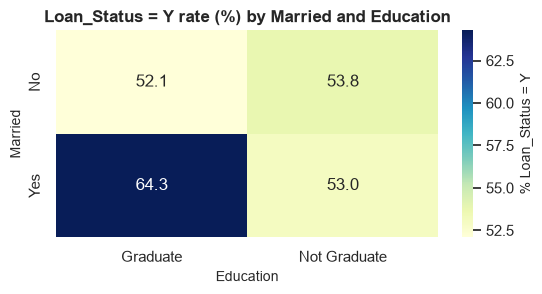

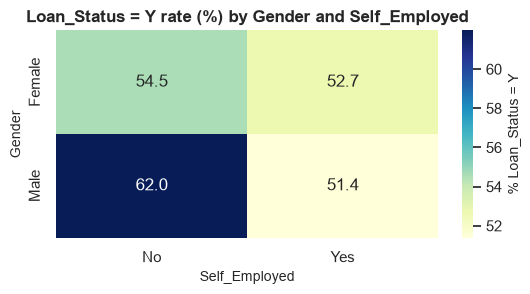

In [25]:
rate_heatmap(loan, 'Credit_History', 'Property_Area', 'Loan_Status', 'Y')
rate_heatmap(loan, 'Married', 'Education', 'Loan_Status', 'Y')
rate_heatmap(loan, 'Gender', 'Self_Employed', 'Loan_Status', 'Y')

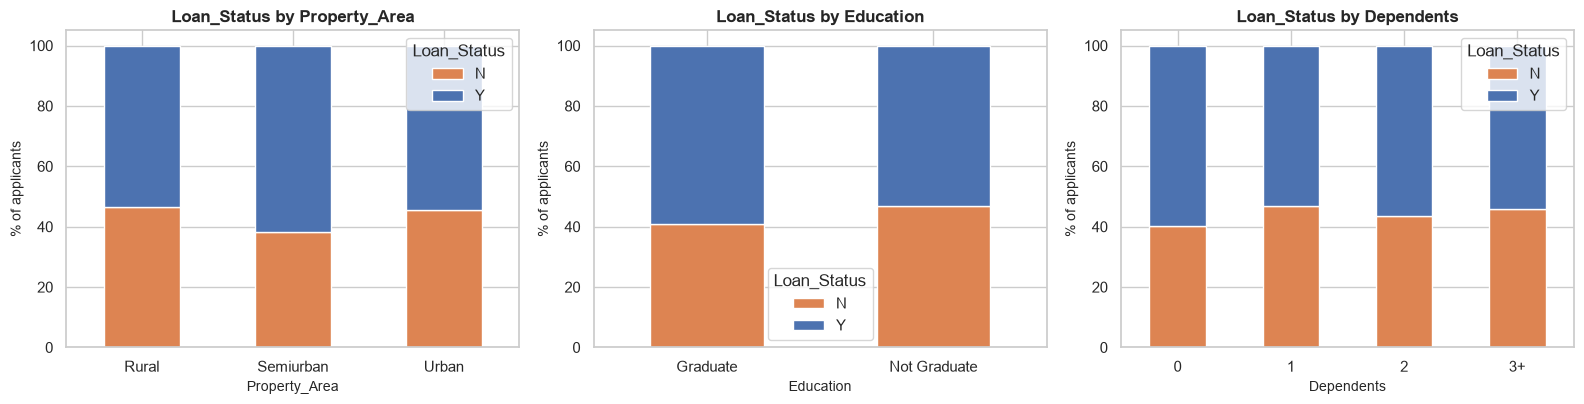

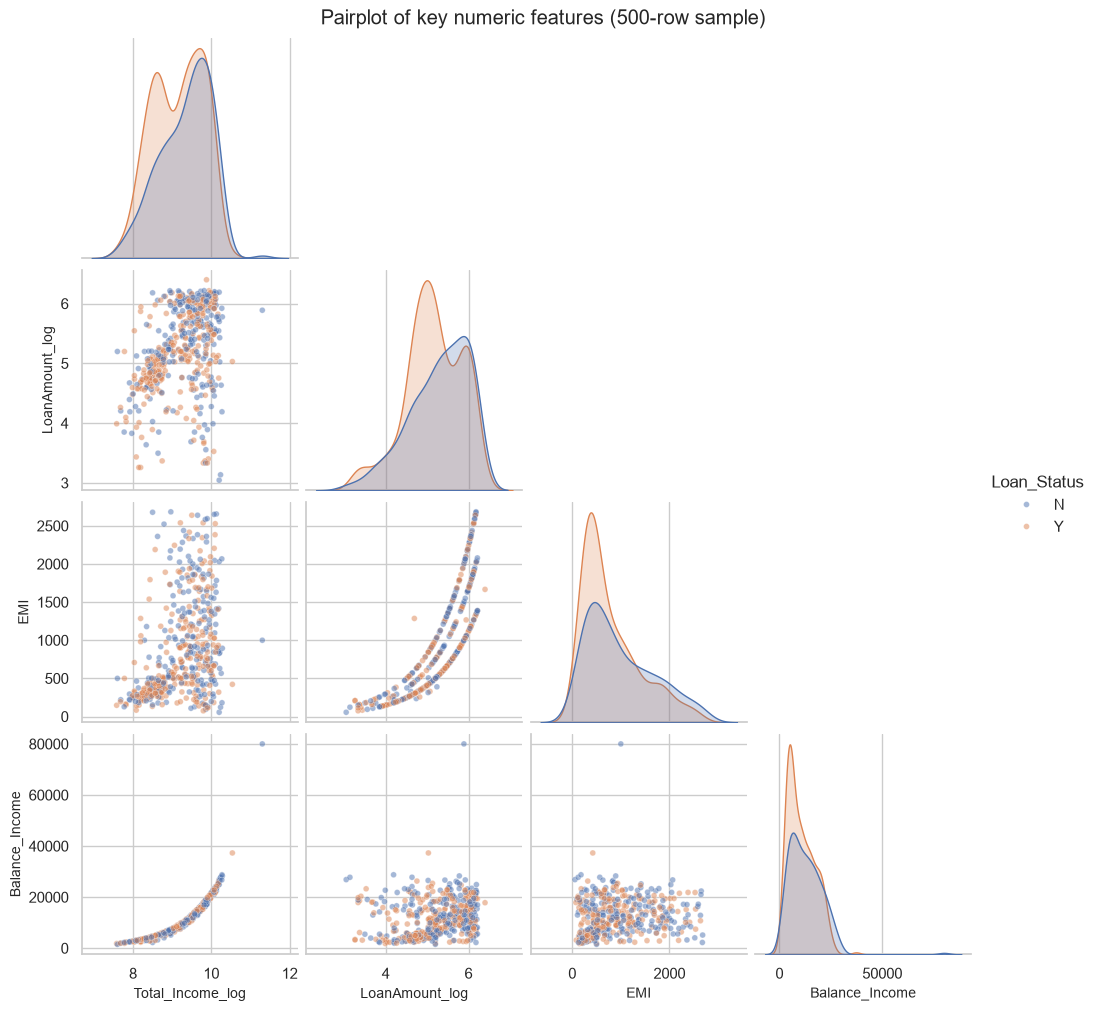

Loan_Status,N,Y
ApplicantIncome,"7,900.000","6,333.000"
CoapplicantIncome,"3,548.000","2,500.000"
LoanAmount,201.000,165.000
Total_Income,"12,291.000","10,082.000"
EMI,745.833,522.222


In [26]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for a, c in zip(ax, ['Property_Area', 'Education', 'Dependents']):
    pd.crosstab(loan[c], loan['Loan_Status'], normalize='index').mul(100).plot(kind='bar', stacked=True, color=[ORANGE, BLUE], ax=a)
    a.set_ylabel('% of applicants'); a.set_title(f'Loan_Status by {c}'); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()
sns.pairplot(loan.sample(500, random_state=1), vars=['Total_Income_log', 'LoanAmount_log', 'EMI', 'Balance_Income'], hue='Loan_Status', corner=True, plot_kws={'alpha': .5, 's': 18})
plt.suptitle('Pairplot of key numeric features (500-row sample)', y=1.01); plt.show()
display(loan.groupby('Loan_Status')[['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Total_Income', 'EMI']].median().T)

## 1.6 Key findings: Loan dataset

In [27]:
ap = (loan['Loan_Status'] == 'Y').mean() * 100
ch = loan.groupby('Credit_History')['Loan_Status'].apply(lambda s: (s == 'Y').mean() * 100)
pa = loan.groupby('Property_Area')['Loan_Status'].apply(lambda s: (s == 'Y').mean() * 100)
print(f'1. Overall approval rate: {ap:.1f}% (class balance: Y = {int((loan.Loan_Status=="Y").sum())}, N = {int((loan.Loan_Status=="N").sum())}).')
print(f'2. Approval rate with Credit_History = 1: {ch[1]:.1f}%  vs  Credit_History = 0: {ch[0]:.1f}%.')
print('3. Approval rate by Property_Area: ' + ', '.join(f'{k} {v:.1f}%' for k, v in pa.items()) + '.')
print(f'4. ApplicantIncome / CoapplicantIncome / LoanAmount are right-skewed with outliers; {int(loan.Has_Coapplicant.eq(0).sum())} applicants have no co-applicant income.')
print(f'5. Missing values handled: {int(loan_raw.isna().sum().sum())} cells imputed; {int(loan.Dup_Loan_ID.sum())} rows share a Loan_ID with another row (flagged).')
cs = corr_loan['Loan_Status_bin'].drop('Loan_Status_bin')
print(f'6. Strongest numeric correlation with approval: {cs.abs().idxmax()} (r = {cs[cs.abs().idxmax()]:.2f}).')
loan.to_csv('data/loan_cleaned.csv', index=False)
print('\nCleaned data saved to data/loan_cleaned.csv  ->', loan.shape)

1. Overall approval rate: 56.7% (class balance: Y = 915, N = 699).
2. Approval rate with Credit_History = 1: 63.1%  vs  Credit_History = 0: 44.9%.
3. Approval rate by Property_Area: Rural 53.7%, Semiurban 61.7%, Urban 54.6%.
4. ApplicantIncome / CoapplicantIncome / LoanAmount are right-skewed with outliers; 273 applicants have no co-applicant income.
5. Missing values handled: 149 cells imputed; 151 rows share a Loan_ID with another row (flagged).
6. Strongest numeric correlation with approval: Credit_History (r = 0.18).

Cleaned data saved to data/loan_cleaned.csv  -> (1614, 27)


**Conclusion (Loan):** after cleaning, all 13 original columns have no missing values and consistent types. In this data, 56.7% of applications are approved; approval is higher when `Credit_History` = 1 (63.1% vs 44.9%) and highest in Semiurban areas (61.7%). The income and loan-amount columns are right-skewed with outliers, so capped and log versions were added. Credit history shows the strongest correlation with approval, but it is still weak (r = 0.18), so no single numeric column explains the decision.

---
# PART 2: Adult Census Income Dataset
**Goal:** understand which demographic and work characteristics are associated with earning more than 50K per year (`income`).

## 2.1 Load the data & first look

In [28]:
adult_raw = pd.read_csv(ADULT_PATH)
overview(adult_raw, 'Adult dataset (raw)')

Adult dataset (raw): 48,842 rows x 15 columns
Memory usage: 9.28 MB



,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K



--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              48842 non-null  int64
 1   workclass        48842 non-null  str  
 2   fnlwgt           48842 non-null  int64
 3   education        48842 non-null  str  
 4   educational-num  48842 non-null  int64
 5   marital-status   48842 non-null  str  
 6   occupation       48842 non-null  str  
 7   relationship     48842 non-null  str  
 8   race             48842 non-null  str  
 9   gender           48842 non-null  str  
 10  capital-gain     48842 non-null  int64
 11  capital-loss     48842 non-null  int64
 12  hours-per-week   48842 non-null  int64
 13  native-country   48842 non-null  str  
 14  income           48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 9.3 MB

--- Numeric summary ---


,count,mean,std,min,25%,50%,75%,max
age,"48,842.000",38.644,13.711,17.000,28.000,37.000,48.000,90.000
fnlwgt,"48,842.000","189,664.135","105,604.025","12,285.000","117,550.500","178,144.500","237,642.000","1,490,400.000"
educational-num,"48,842.000",10.078,2.571,1.000,9.000,10.000,12.000,16.000
capital-gain,"48,842.000","1,079.068","7,452.019",0.000,0.000,0.000,0.000,"99,999.000"
capital-loss,"48,842.000",87.502,403.005,0.000,0.000,0.000,0.000,"4,356.000"
hours-per-week,"48,842.000",40.422,12.391,1.000,40.000,40.000,45.000,99.000



--- Non-numeric summary ---


,count,unique,top,freq
workclass,48842,9,Private,33906
education,48842,16,HS-grad,15784
marital-status,48842,7,Married-civ-spouse,22379
occupation,48842,15,Prof-specialty,6172
relationship,48842,6,Husband,19716
race,48842,5,White,41762
gender,48842,2,Male,32650
native-country,48842,42,United-States,43832
income,48842,2,<=50K,37155


### Column dictionary
| Column | Meaning |
|---|---|
| age | Age in years |
| workclass | Employment type (private, government, self-employed, ...) |
| fnlwgt | Census sampling weight (how many people the record represents) |
| education | Highest education level reached |
| educational-num | Numeric encoding of `education` |
| marital-status | Marital status |
| occupation | Occupation |
| relationship | Role in the household |
| race | Race |
| gender | Male / Female |
| capital-gain / capital-loss | Capital gains / losses for the year |
| hours-per-week | Working hours per week |
| native-country | Country of origin |
| **income** | **Target**: `<=50K` or `>50K` |

## 2.2 Data-quality audit (before cleaning)

Duplicate rows: 52

Placeholder "?" values (hidden missing data):


,count,percent
workclass,2799,5.731
occupation,2809,5.751
native-country,857,1.755


Real NaN values: 0


,missing,percent
occupation,2809,5.751
workclass,2799,5.731
native-country,857,1.755


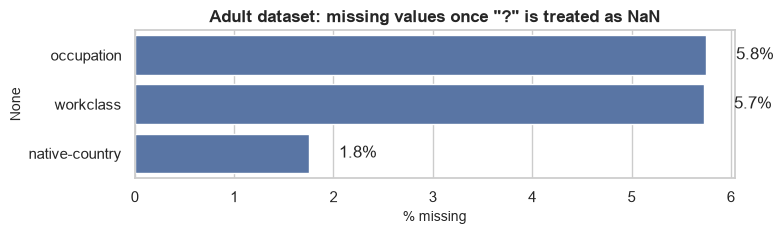

In [29]:
print('Duplicate rows:', adult_raw.duplicated().sum())
q_count = (adult_raw == '?').sum()
print('\nPlaceholder "?" values (hidden missing data):'); display(q_count[q_count > 0].to_frame('count').assign(percent=lambda d: d['count'] / len(adult_raw) * 100))
print('Real NaN values:', int(adult_raw.isna().sum().sum()))
adult_q = adult_raw.replace('?', np.nan)      # "?" turned into NaN, used for the raw-vs-clean comparisons
_ = missing_report(adult_q, 'Adult dataset: missing values once "?" is treated as NaN')

In [30]:
both = (adult_q['workclass'].isna() & adult_q['occupation'].isna()).sum()
print(f"workclass and occupation both missing in {both:,} rows; only workclass missing: {(adult_q['workclass'].isna() & adult_q['occupation'].notna()).sum()}, only occupation missing: {(adult_q['occupation'].isna() & adult_q['workclass'].notna()).sum()}")
print('\nWorkclass of rows with missing occupation:'); display(adult_q.loc[adult_q['occupation'].isna(), 'workclass'].value_counts(dropna=False).to_frame('count').T)

# education vs educational-num: is one redundant?
chk = adult_raw.groupby('education')['educational-num'].nunique()
print('Each education level maps to exactly one educational-num value:', bool((chk == 1).all()), '-> the two columns carry the same information.')

print('\nRange checks:')
print('  age:', adult_raw['age'].min(), '-', adult_raw['age'].max(), '| hours-per-week:', adult_raw['hours-per-week'].min(), '-', adult_raw['hours-per-week'].max())
print('  capital-gain == 99999 (top-coded placeholder):', (adult_raw['capital-gain'] == 99999).sum())
print('  rows with BOTH capital gain and capital loss > 0:', ((adult_raw['capital-gain'] > 0) & (adult_raw['capital-loss'] > 0)).sum())
print('  income labels:', list(adult_raw['income'].unique()))

workclass and occupation both missing in 2,799 rows; only workclass missing: 0, only occupation missing: 10

Workclass of rows with missing occupation:


workclass,NaN,Never-worked
count,2799,10


Each education level maps to exactly one educational-num value: True -> the two columns carry the same information.

Range checks:
  age: 17 - 90 | hours-per-week: 1 - 99
  capital-gain == 99999 (top-coded placeholder): 244
  rows with BOTH capital gain and capital loss > 0: 0
  income labels: ['<=50K', '>50K']


## 2.3 Data cleaning

**Cleaning plan (and why)**

| Issue | Treatment | Reason |
|---|---|---|
| Column names contain `-` | rename to snake_case (`hours_per_week` ...) | easier to use in code |
| Whitespace in text | `str.strip()` | avoid fake categories |
| `?` placeholders | converted to `NaN` | they are real missing values |
| Missing `workclass` / `occupation` | new category `Unknown` | they are missing together (people who are not working); the missingness itself is informative |
| Missing `native_country` | mode (`United-States`) | about 91% of rows, only ~1.7% missing |
| Duplicate rows | dropped | exact copies add no information |
| Outliers / skew | 1-99 percentile capping into `*_capped` columns | data is zero-inflated, so the IQR rule would be too aggressive |
| `income` text target | `income_bin` (1/0) | needed for correlations |
| New features | `age_group`, `hours_group`, `education_level`, `net_capital`, `has_capital_gain`, `has_capital_loss`, `is_us_native` | easier segment analysis |

In [31]:
adult = adult_raw.copy()
adult_log = []
def alog(step, detail): adult_log.append({'step': step, 'detail': detail})

# 1) column names
adult.columns = [c.replace('-', '_') for c in adult.columns]
alog('Rename columns', 'hyphens -> underscores')

# 2) whitespace + '?' -> NaN
for c in [c for c in adult.columns if not pd.api.types.is_numeric_dtype(adult[c])]:
    adult[c] = adult[c].str.strip()
adult = adult.replace('?', np.nan)
alog('Placeholder to NaN', f"{int(adult.isna().sum().sum())} '?' cells converted")

# 3) duplicates
before = len(adult)
adult = adult.drop_duplicates().reset_index(drop=True)
alog('Drop duplicates', f'{before - len(adult)} rows removed ({before:,} -> {len(adult):,})')

# 4) missing values
for c in ['workclass', 'occupation']:
    n = adult[c].isna().sum(); adult[c] = adult[c].fillna('Unknown'); alog(f'Impute {c}', f"{n} missing -> 'Unknown'")
n = adult['native_country'].isna().sum(); m = adult['native_country'].mode()[0]
adult['native_country'] = adult['native_country'].fillna(m); alog('Impute native_country', f'{n} missing -> mode = {m}')

# 5) target encoding
adult['income_bin'] = (adult['income'] == '>50K').astype(int)

# 6) outlier capping (1-99 percentile)
cap_log = [winsor(adult, c) for c in ['age', 'fnlwgt', 'capital_gain', 'capital_loss', 'hours_per_week']]
alog('Cap outliers', ', '.join(d['new_column'] for d in cap_log))
display(pd.DataFrame(cap_log))

# 7) feature engineering
edu_map = {'Preschool': 'School', '1st-4th': 'School', '5th-6th': 'School', '7th-8th': 'School', '9th': 'School', '10th': 'School',
           '11th': 'School', '12th': 'School', 'HS-grad': 'HS-grad', 'Some-college': 'Some college', 'Assoc-voc': 'Associate',
           'Assoc-acdm': 'Associate', 'Bachelors': 'Bachelors', 'Masters': 'Postgraduate', 'Prof-school': 'Postgraduate', 'Doctorate': 'Postgraduate'}
adult['education_level'] = adult['education'].map(edu_map)
adult['age_group'] = pd.cut(adult['age'], [0, 24, 34, 44, 54, 64, 100], labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])
adult['hours_group'] = pd.cut(adult['hours_per_week'], [0, 29, 40, 50, 100], labels=['Part-time (<30)', 'Full-time (30-40)', 'Overtime (41-50)', 'Heavy (50+)'])
adult['net_capital'] = adult['capital_gain'] - adult['capital_loss']
adult['has_capital_gain'] = (adult['capital_gain'] > 0).astype(int)
adult['has_capital_loss'] = (adult['capital_loss'] > 0).astype(int)
adult['is_us_native'] = (adult['native_country'] == 'United-States').astype(int)
alog('Feature engineering', 'education_level, age_group, hours_group, net_capital, has_capital_gain, has_capital_loss, is_us_native')

print('Missing values after cleaning:', int(adult.isna().sum().sum()), '| shape:', adult_raw.shape, '->', adult.shape)
display(pd.DataFrame(adult_log))

,column,method,lower,upper,values_capped,new_column
0,age,1-99 percentile,17.000,74.000,444,age_capped
1,fnlwgt,1-99 percentile,"27,165.560","509,514.190",976,fnlwgt_capped
2,capital_gain,1-99 percentile,0.000,"15,024.000",391,capital_gain_capped
3,capital_loss,1-99 percentile,0.000,"2,001.000",456,capital_loss_capped
4,hours_per_week,1-99 percentile,8.000,80.000,773,hours_per_week_capped


Missing values after cleaning: 0 | shape: (48842, 15) -> (48790, 28)


,step,detail
0,Rename columns,hyphens -> underscores
1,Placeholder to NaN,6465 '?' cells converted
2,Drop duplicates,"52 rows removed (48,842 -> 48,790)"
3,Impute workclass,2795 missing -> 'Unknown'
4,Impute occupation,2805 missing -> 'Unknown'
5,Impute native_country,856 missing -> mode = United-States
6,Cap outliers,"age_capped, fnlwgt_capped, capital_gain_capped..."
7,Feature engineering,"education_level, age_group, hours_group, net_c..."


## 2.4 Column-by-column analysis

### 2.4.1 `age`
**Description:** Age of the person in years.

**Cleaning:** No missing values; capped at the 1st/99th percentile in `age_capped`; `age_group` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
age,48790,0,74,38.653,37.000,13.708,17,90,0.557,-0.187


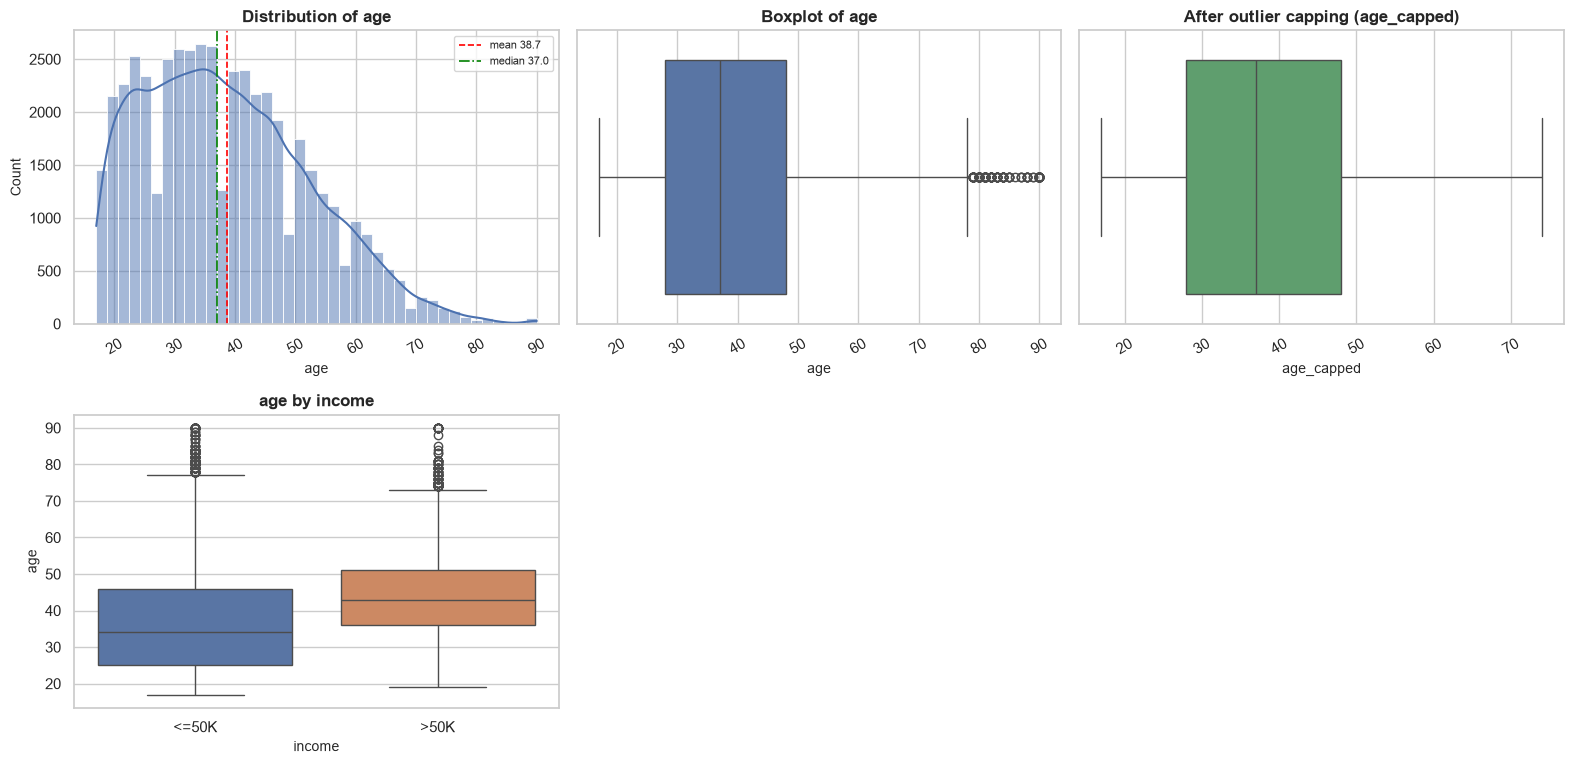

INSIGHTS
  - Distribution is moderately skewed to the right (skew = 0.56); mean = 38.65, median = 37.00.
  - 215 IQR outliers (0.44%) outside [-2.00, 78.00].
  - Median of age by income: <=50K = 34.00, >50K = 43.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [32]:
num_profile(adult, 'age', target='income', raw=adult_q, capped="age_capped")

,count,percent
age_group,,
25-34,12564,25.751
35-44,12184,24.972
45-54,8765,17.965
<25,8409,17.235
55-64,4782,9.801
65+,2086,4.275


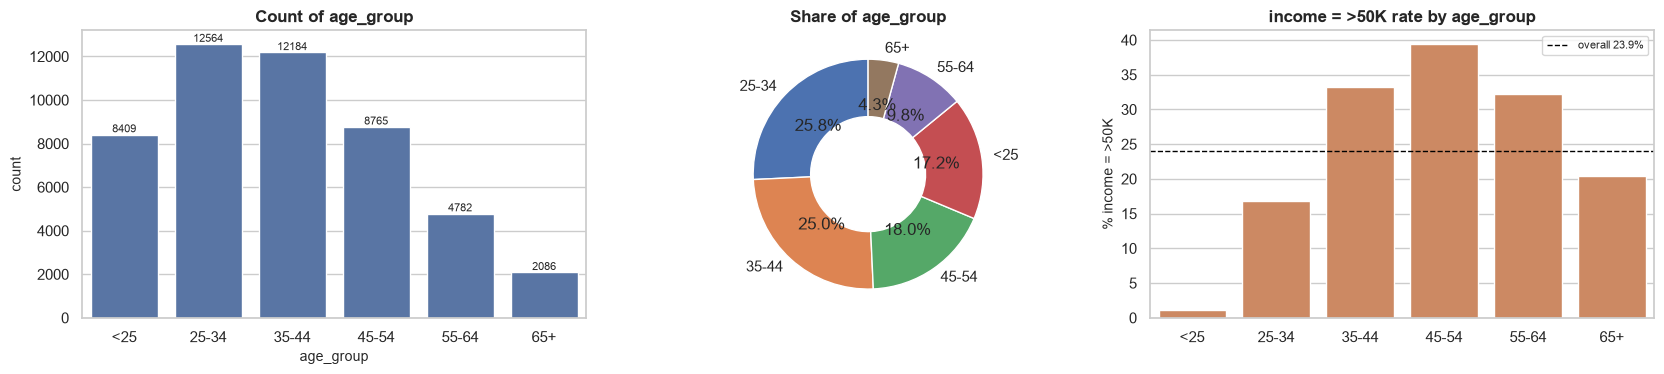

INSIGHTS
  - 6 unique categories; most frequent is "25-34" (25.8%).
  - Highest income=>50K rate: "45-54" (39.4%); lowest: "<25" (1.1%).


In [33]:
cat_profile(adult, 'age_group', target='income', positive='>50K', order=['<25', '25-34', '35-44', '45-54', '55-64', '65+'])

### 2.4.2 `workclass`
**Description:** Type of employer / employment.

**Cleaning:** `?` converted to NaN then labelled `Unknown`.

,count,percent
workclass,,
Private,33860,69.399
Self-emp-not-inc,3861,7.914
Local-gov,3136,6.428
Unknown,2795,5.729
State-gov,1981,4.060
Self-emp-inc,1694,3.472
Federal-gov,1432,2.935
Without-pay,21,0.043
Never-worked,10,0.020


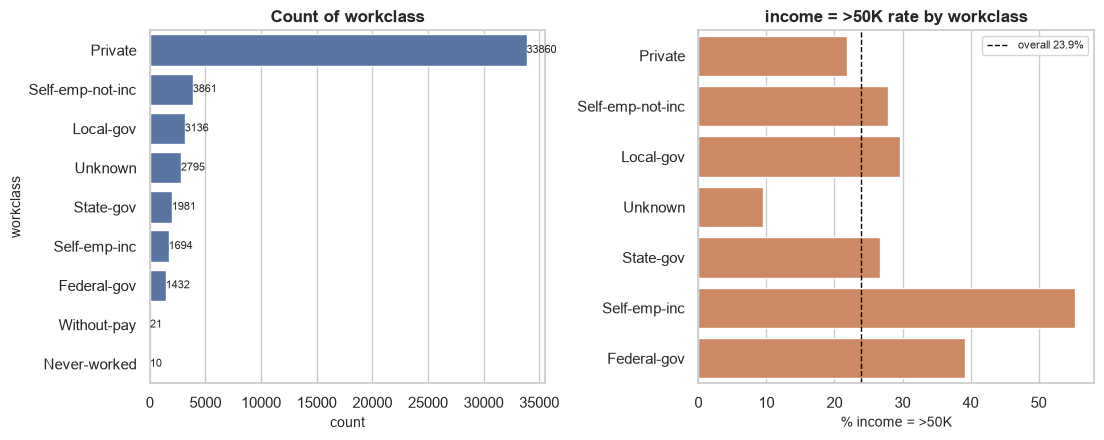

INSIGHTS
  - 9 unique categories; most frequent is "Private" (69.4%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "Self-emp-inc" (55.4%); lowest: "Unknown" (9.5%).
  - Missing values: raw = 2,799 -> cleaned = 0.


In [34]:
cat_profile(adult, 'workclass', target='income', positive='>50K', raw=adult_q)

### 2.4.3 `fnlwgt`
**Description:** Census sampling weight: the number of people in the population the row represents. It is a survey artefact, not a personal attribute.

**Cleaning:** No missing values; capped in `fnlwgt_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
fnlwgt,48790,0,28523,"189,668.999","178,138.500","105,617.231",12285,1490400,1.440,6.061


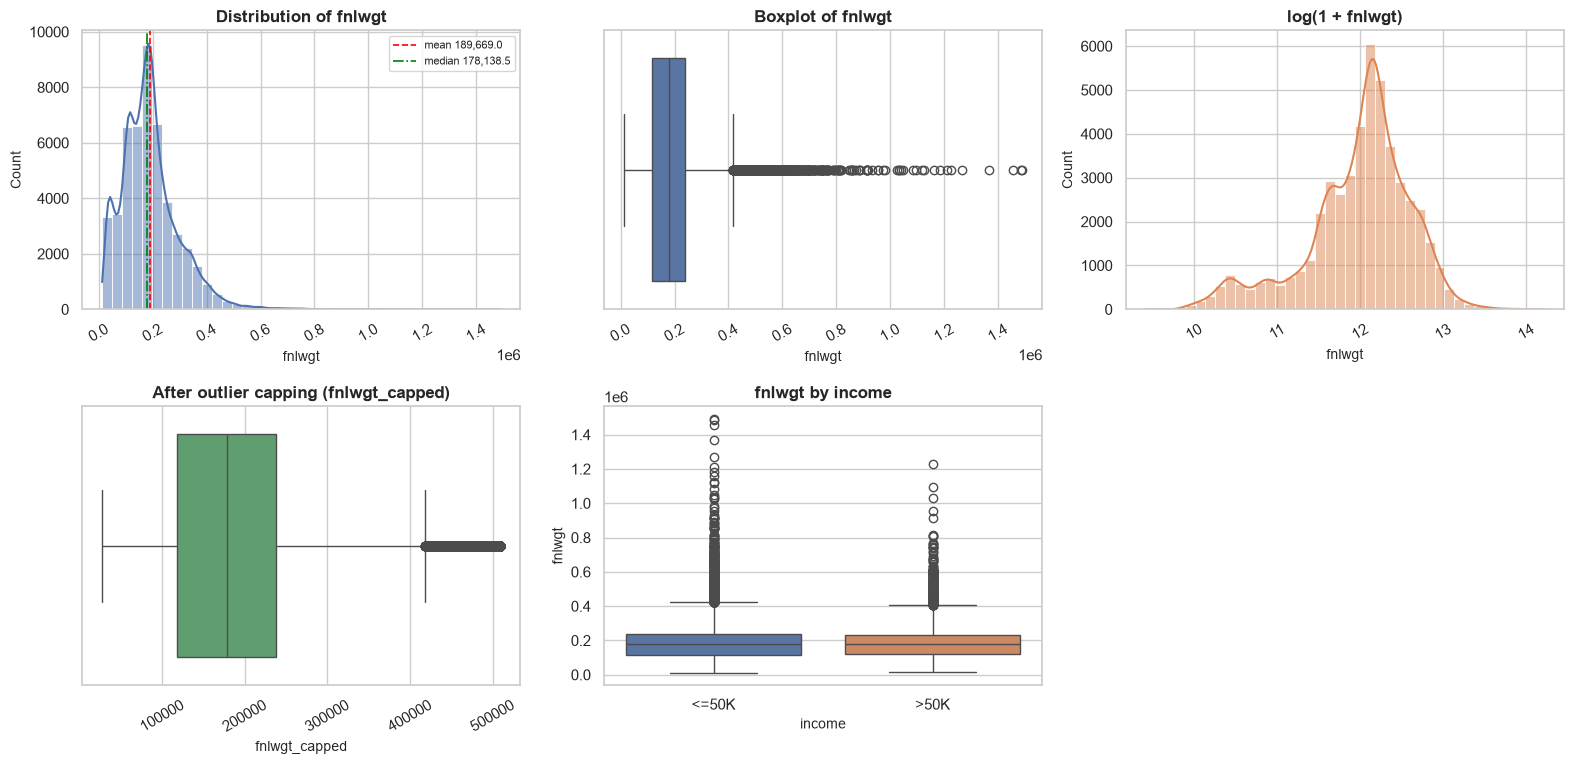

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.44); mean = 189,669.00, median = 178,138.50.
  - 1,453 IQR outliers (2.98%) outside [-62,521.88, 417,683.12].
  - Median of fnlwgt by income: <=50K = 178,811.00, >50K = 176,729.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [35]:
num_profile(adult, 'fnlwgt', target='income', raw=adult_q, capped="fnlwgt_capped")

### 2.4.4 `education`
**Description:** Highest education level (16 levels, shown from lowest to highest).

**Cleaning:** No missing values; grouped into `education_level`.

,count,percent
education,,
HS-grad,15770,32.322
Some-college,10863,22.265
Bachelors,8013,16.423
Masters,2656,5.444
Assoc-voc,2060,4.222
11th,1812,3.714
Assoc-acdm,1601,3.281
10th,1389,2.847
7th-8th,954,1.955


... 4 more categories not shown (total unique = 16).


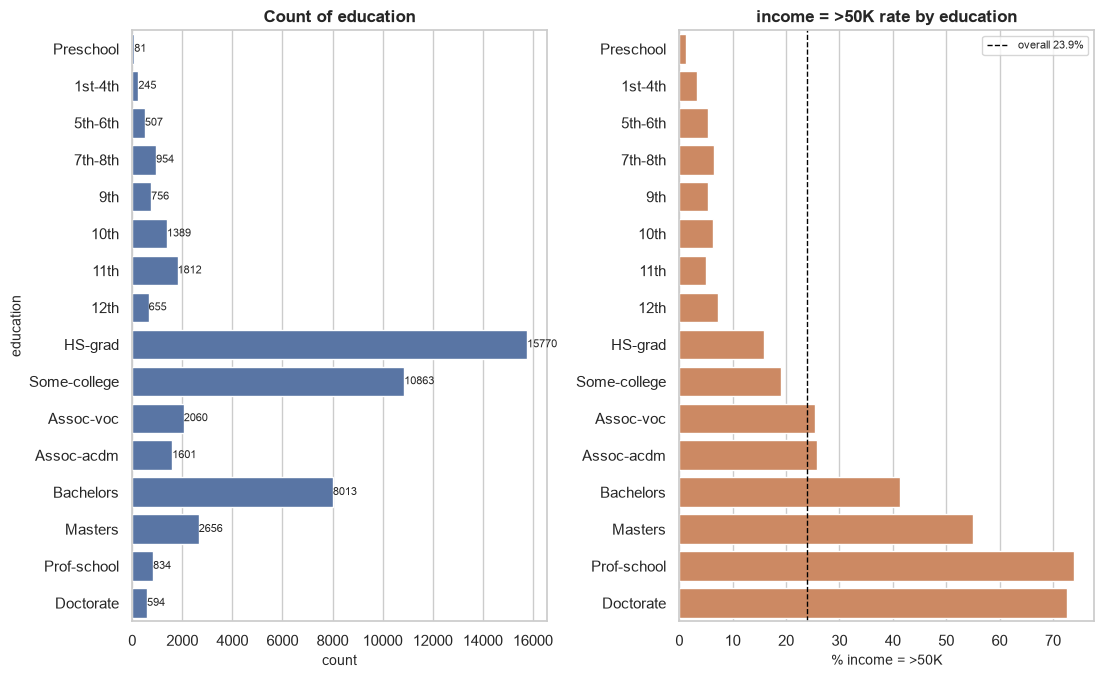

INSIGHTS
  - 16 unique categories; most frequent is "HS-grad" (32.3%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "Prof-school" (74.0%); lowest: "Preschool" (1.2%).
  - Missing values: raw = 0 -> cleaned = 0.


In [36]:
cat_profile(adult, 'education', target='income', positive='>50K', raw=adult_q, order=list(adult.sort_values("educational_num")["education"].unique()))

### 2.4.5 `educational_num`
**Description:** Numeric code of `education` (1 = Preschool ... 16 = Doctorate). Exactly one code per education level, so redundant with `education`.

**Cleaning:** No missing values; kept as a numeric feature, `education` is the readable label.

,count,percent
educational_num,,
9,15770,32.322
10,10863,22.265
13,8013,16.423
14,2656,5.444
11,2060,4.222
7,1812,3.714
12,1601,3.281
6,1389,2.847
4,954,1.955


... 4 more categories not shown (total unique = 16).


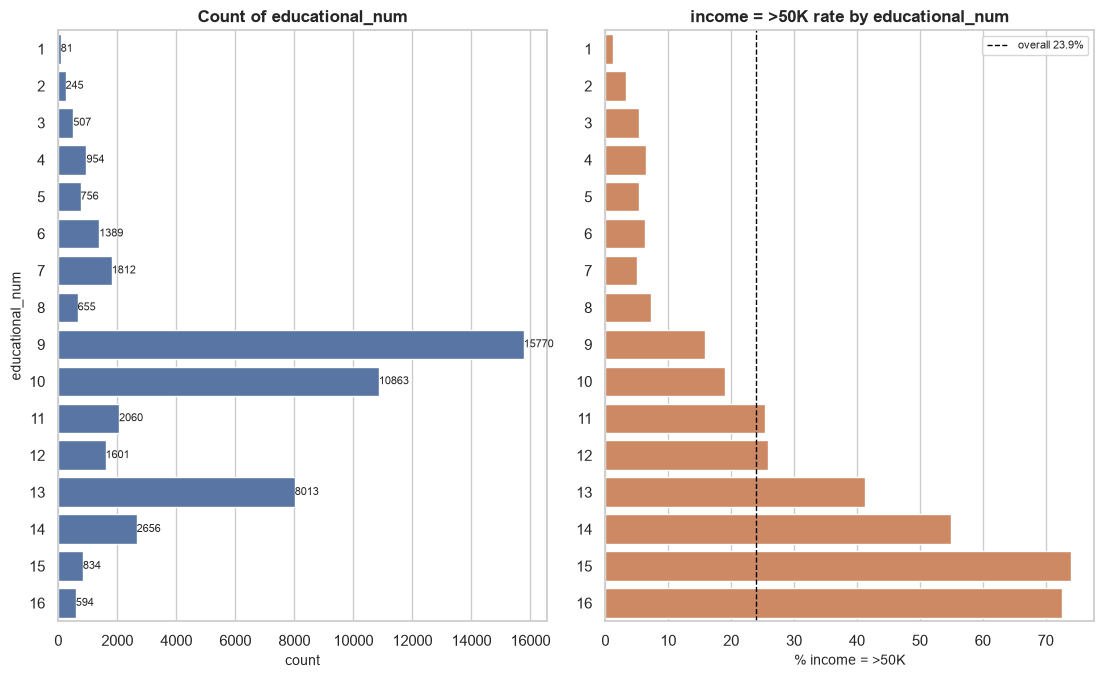

INSIGHTS
  - 16 unique categories; most frequent is "9" (32.3%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "15" (74.0%); lowest: "1" (1.2%).


In [37]:
cat_profile(adult, 'educational_num', target='income', positive='>50K', raw=adult_q, order=sorted(adult["educational_num"].unique()))

,count,percent
education_level,,
HS-grad,15770,32.322
Some college,10863,22.265
Bachelors,8013,16.423
School,6399,13.115
Postgraduate,4084,8.371
Associate,3661,7.504


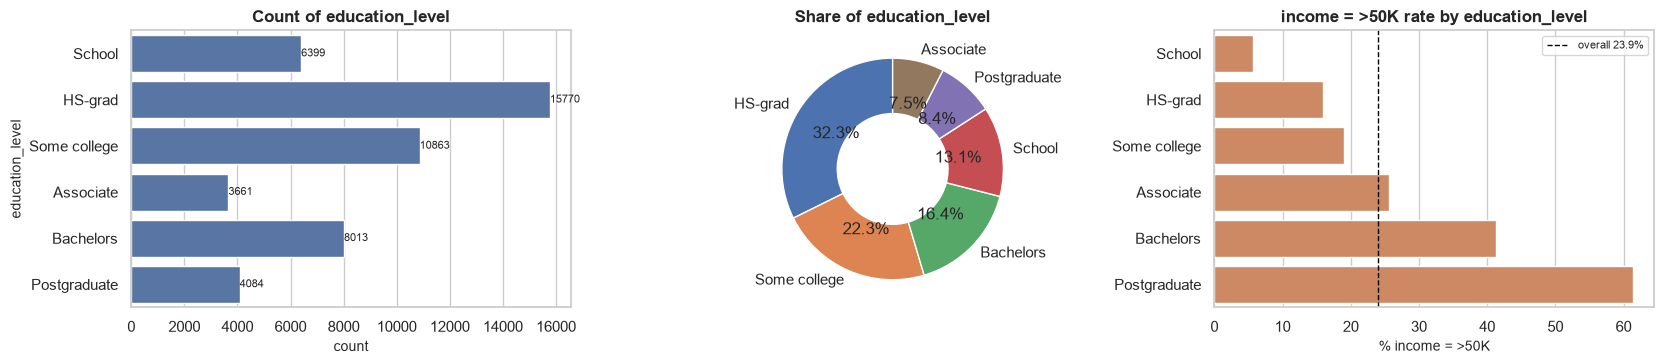

INSIGHTS
  - 6 unique categories; most frequent is "HS-grad" (32.3%).
  - Highest income=>50K rate: "Postgraduate" (61.4%); lowest: "School" (5.7%).


In [38]:
cat_profile(adult, 'education_level', target='income', positive='>50K', order=['School', 'HS-grad', 'Some college', 'Associate', 'Bachelors', 'Postgraduate'])

### 2.4.6 `marital_status`
**Description:** Marital status.

**Cleaning:** No missing values.

,count,percent
marital_status,,
Married-civ-spouse,22366,45.841
Never-married,16082,32.962
Divorced,6630,13.589
Separated,1530,3.136
Widowed,1518,3.111
Married-spouse-absent,627,1.285
Married-AF-spouse,37,0.076


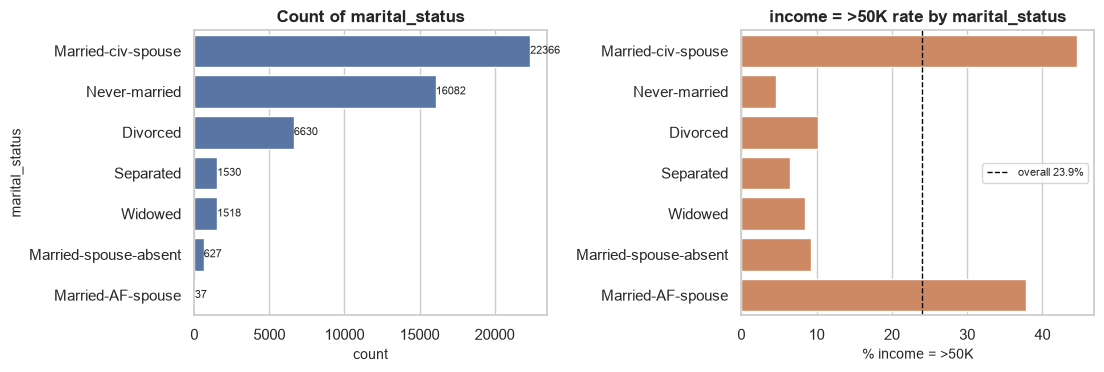

INSIGHTS
  - 7 unique categories; most frequent is "Married-civ-spouse" (45.8%).
  - 1 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "Married-civ-spouse" (44.6%); lowest: "Never-married" (4.6%).


In [39]:
cat_profile(adult, 'marital_status', target='income', positive='>50K', raw=adult_q)

### 2.4.7 `occupation`
**Description:** Occupation of the person.

**Cleaning:** `?` converted to NaN then labelled `Unknown`.

,count,percent
occupation,,
Prof-specialty,6165,12.636
Craft-repair,6102,12.507
Exec-managerial,6082,12.466
Adm-clerical,5606,11.490
Sales,5501,11.275
Other-service,4919,10.082
Machine-op-inspct,3017,6.184
Unknown,2805,5.749
Transport-moving,2355,4.827


... 3 more categories not shown (total unique = 15).


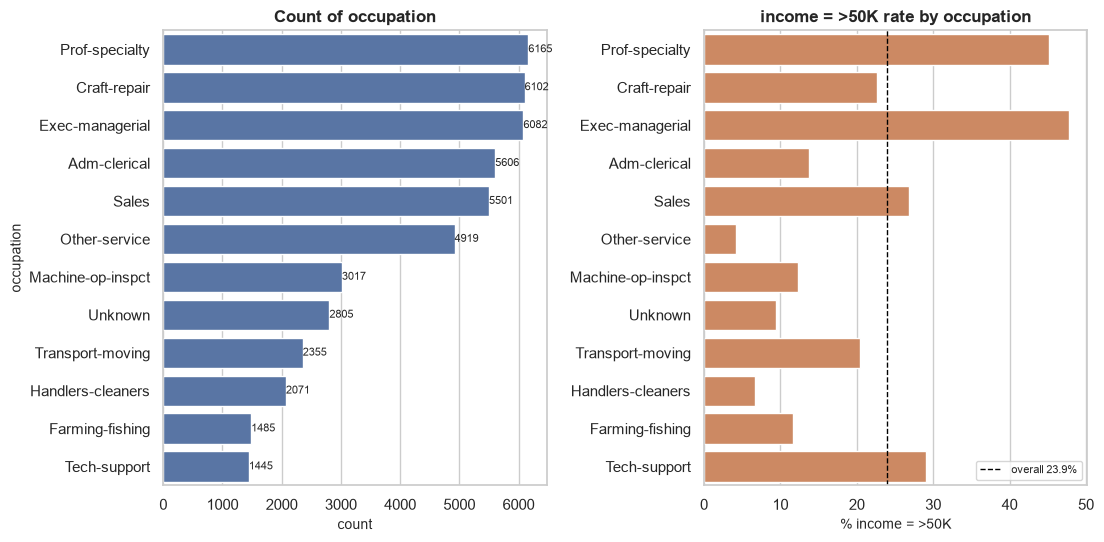

INSIGHTS
  - 15 unique categories; most frequent is "Prof-specialty" (12.6%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "Exec-managerial" (47.8%); lowest: "Other-service" (4.1%).
  - Missing values: raw = 2,809 -> cleaned = 0.


In [40]:
cat_profile(adult, 'occupation', target='income', positive='>50K', raw=adult_q)

### 2.4.8 `relationship`
**Description:** Role of the person in the household.

**Cleaning:** No missing values.

,count,percent
relationship,,
Husband,19703,40.383
Not-in-family,12557,25.737
Own-child,7569,15.513
Unmarried,5124,10.502
Wife,2331,4.778
Other-relative,1506,3.087


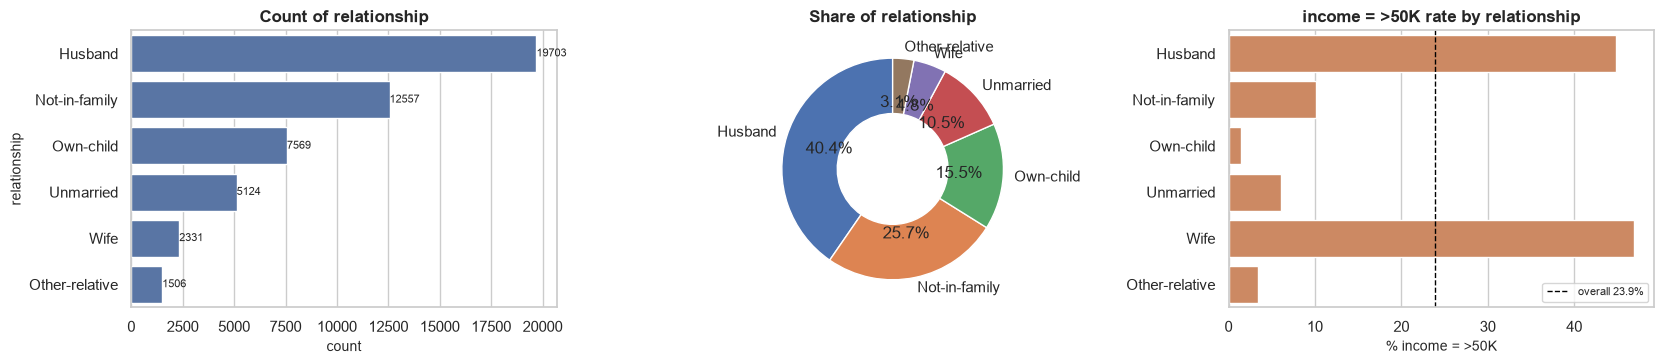

INSIGHTS
  - 6 unique categories; most frequent is "Husband" (40.4%).
  - Highest income=>50K rate: "Wife" (46.9%); lowest: "Own-child" (1.5%).
  - Missing values: raw = 0 -> cleaned = 0.


In [41]:
cat_profile(adult, 'relationship', target='income', positive='>50K', raw=adult_q)

### 2.4.9 `race`
**Description:** Race of the person.

**Cleaning:** No missing values.

,count,percent
race,,
White,41714,85.497
Black,4683,9.598
Asian-Pac-Islander,1517,3.109
Amer-Indian-Eskimo,470,0.963
Other,406,0.832


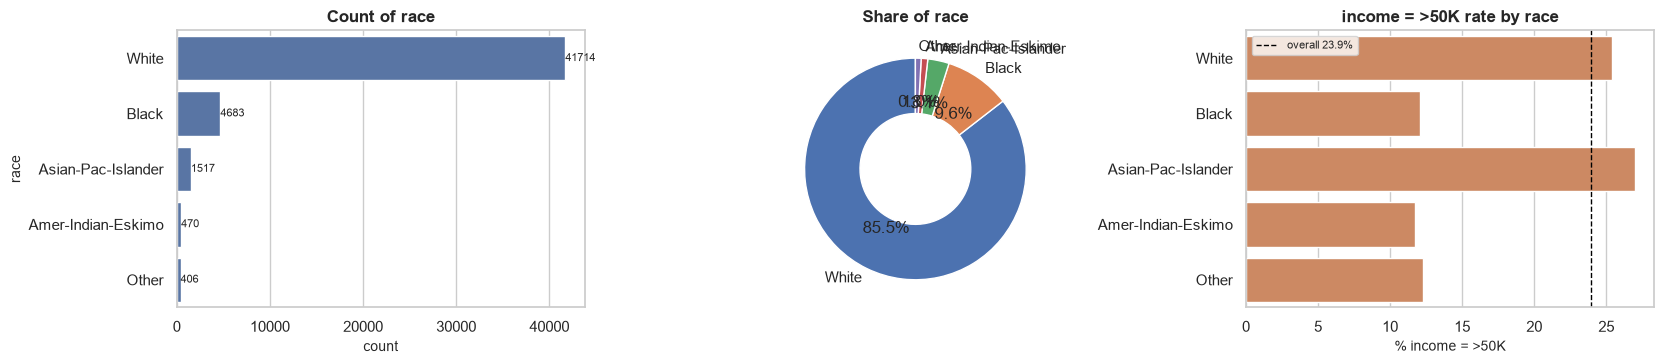

INSIGHTS
  - 5 unique categories; most frequent is "White" (85.5%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "Asian-Pac-Islander" (27.0%); lowest: "Amer-Indian-Eskimo" (11.7%).
  - Missing values: raw = 0 -> cleaned = 0.


In [42]:
cat_profile(adult, 'race', target='income', positive='>50K', raw=adult_q)

### 2.4.10 `gender`
**Description:** Male / Female.

**Cleaning:** No missing values.

,count,percent
gender,,
Male,32614,66.846
Female,16176,33.154


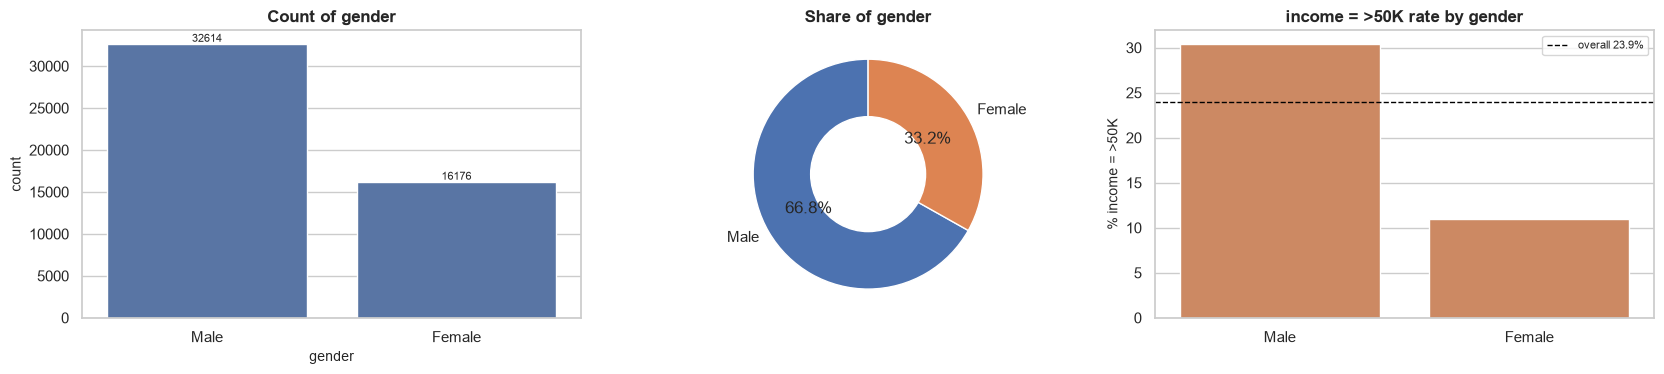

INSIGHTS
  - 2 unique categories; most frequent is "Male" (66.8%).
  - Highest income=>50K rate: "Male" (30.4%); lowest: "Female" (10.9%).
  - Missing values: raw = 0 -> cleaned = 0.


In [43]:
cat_profile(adult, 'gender', target='income', positive='>50K', raw=adult_q)

### 2.4.11 `capital_gain`
**Description:** Capital gains for the year. Mostly 0; the value 99999 is a top-coded placeholder for very large gains.

**Cleaning:** No missing values; capped in `capital_gain_capped`; flag `has_capital_gain` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
capital_gain,48790,0,123,"1,080.218",0.000,"7,455.906",0,99999,11.888,152.527


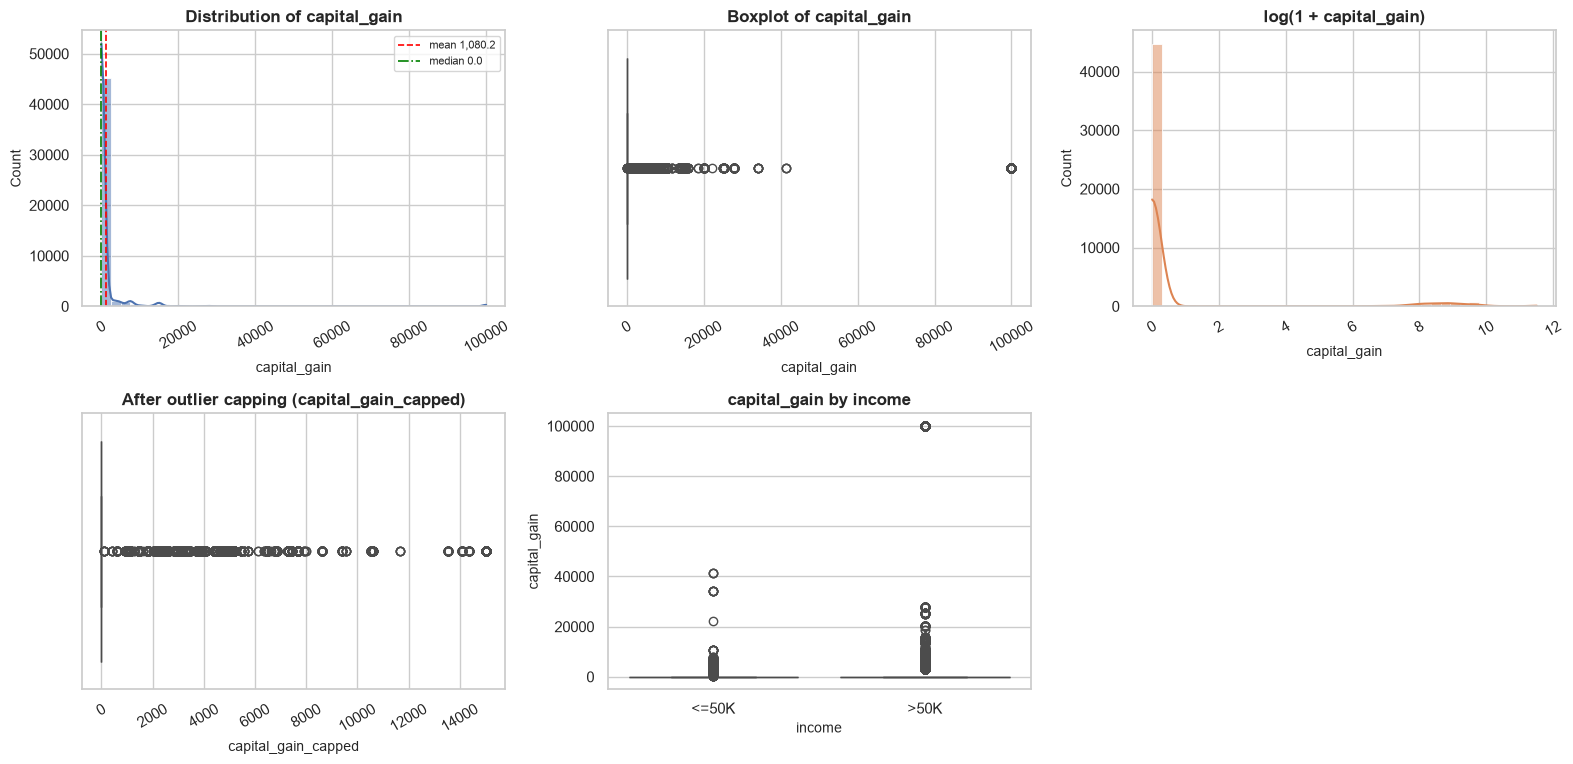

INSIGHTS
  - Distribution is highly skewed to the right (skew = 11.89); mean = 1,080.22, median = 0.00.
  - 4,035 IQR outliers (8.27%) outside [0.00, 0.00].
  - 91.7% of the values are exactly 0.
  - Median of capital_gain by income: <=50K = 0.00, >50K = 0.00.


In [44]:
num_profile(adult, 'capital_gain', target='income', raw=adult_q, capped="capital_gain_capped")

Non-zero capital gains: 4,035 rows (8.3%), of which 99999 (top-coded): 244


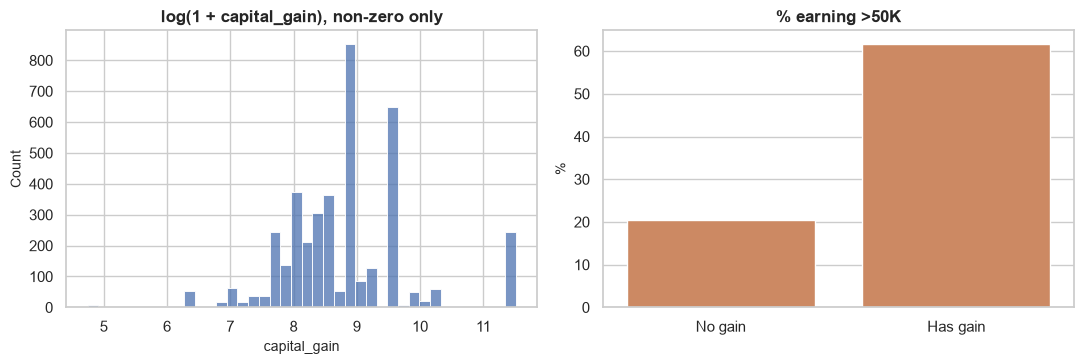

In [45]:
nz = adult.loc[adult['capital_gain'] > 0, 'capital_gain']
print(f'Non-zero capital gains: {len(nz):,} rows ({len(nz)/len(adult)*100:.1f}%), of which 99999 (top-coded): {(nz == 99999).sum()}')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(np.log1p(nz), bins=40, color=BLUE, ax=ax[0]); ax[0].set_title('log(1 + capital_gain), non-zero only')
sns.barplot(x=['No gain', 'Has gain'], y=adult.groupby('has_capital_gain')['income_bin'].mean() * 100, color=ORANGE, ax=ax[1]); ax[1].set_title('% earning >50K'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

### 2.4.12 `capital_loss`
**Description:** Capital losses for the year. Mostly 0.

**Cleaning:** No missing values; capped in `capital_loss_capped`; flag `has_capital_loss` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
capital_loss,48790,0,99,87.596,0.000,403.209,0,4356,4.567,19.988


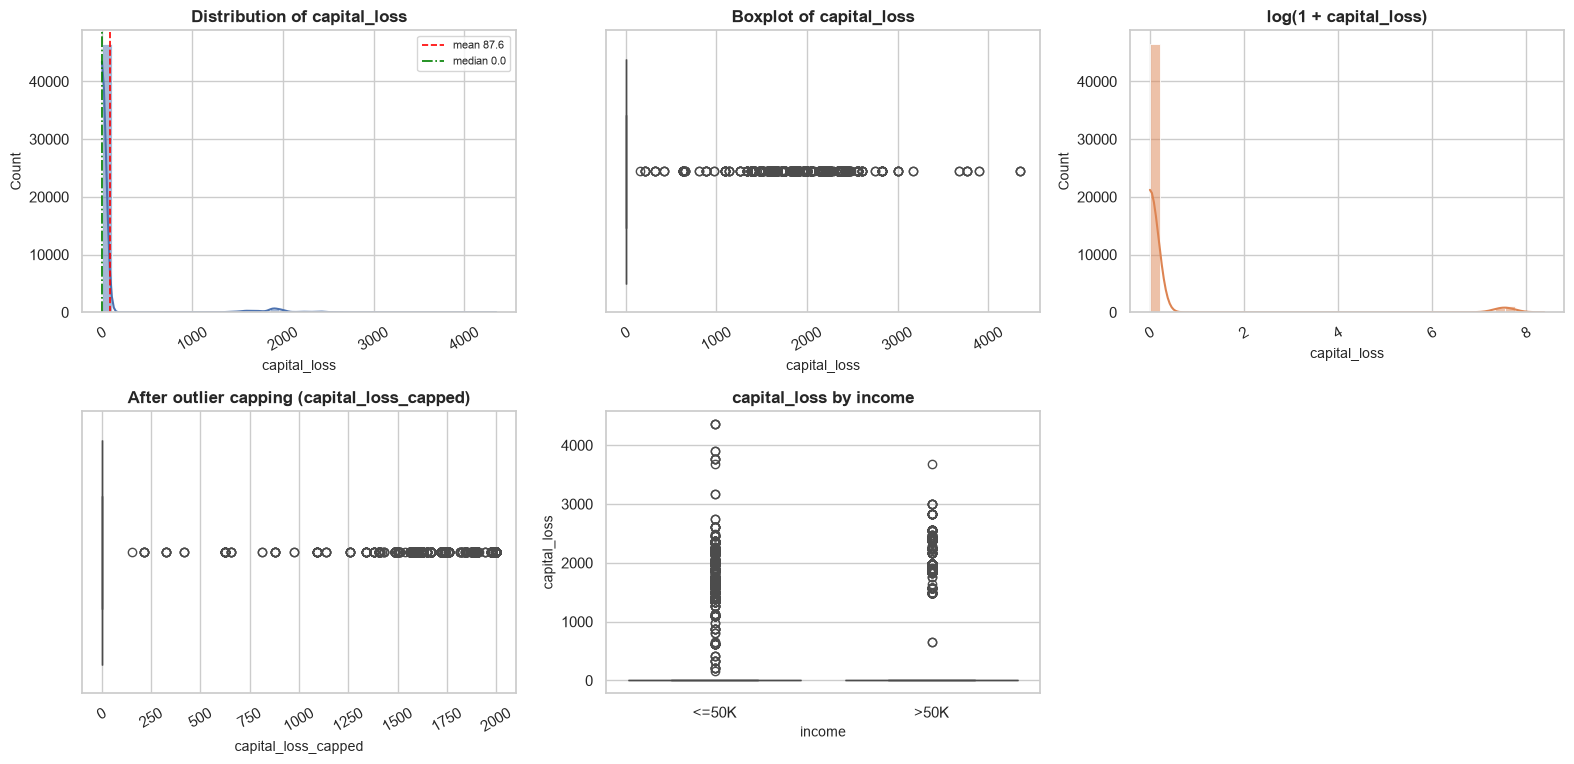

INSIGHTS
  - Distribution is highly skewed to the right (skew = 4.57); mean = 87.60, median = 0.00.
  - 2,282 IQR outliers (4.68%) outside [0.00, 0.00].
  - 95.3% of the values are exactly 0.
  - Median of capital_loss by income: <=50K = 0.00, >50K = 0.00.


In [46]:
num_profile(adult, 'capital_loss', target='income', raw=adult_q, capped="capital_loss_capped")

Non-zero capital losses: 2,282 rows (4.7%)


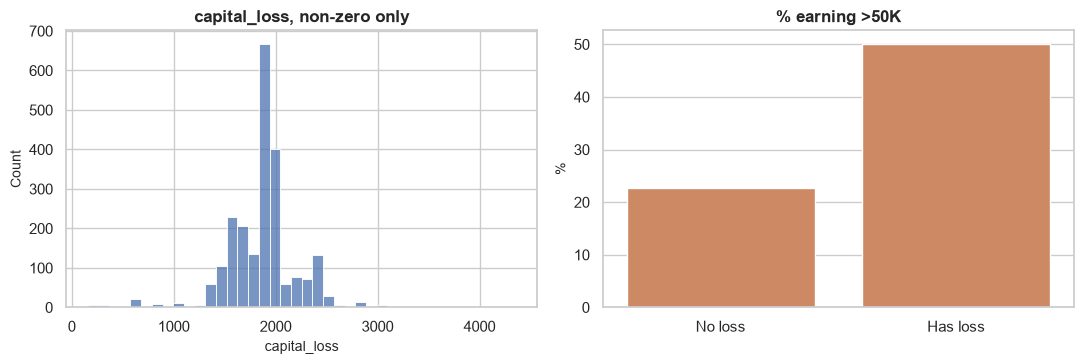

In [47]:
nz = adult.loc[adult['capital_loss'] > 0, 'capital_loss']
print(f'Non-zero capital losses: {len(nz):,} rows ({len(nz)/len(adult)*100:.1f}%)')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(nz, bins=40, color=BLUE, ax=ax[0]); ax[0].set_title('capital_loss, non-zero only')
sns.barplot(x=['No loss', 'Has loss'], y=adult.groupby('has_capital_loss')['income_bin'].mean() * 100, color=ORANGE, ax=ax[1]); ax[1].set_title('% earning >50K'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

### 2.4.13 `hours_per_week`
**Description:** Usual working hours per week.

**Cleaning:** No missing values; capped in `hours_per_week_capped`; `hours_group` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
hours_per_week,48790,0,96,40.426,40.000,12.393,1,99,0.240,2.951


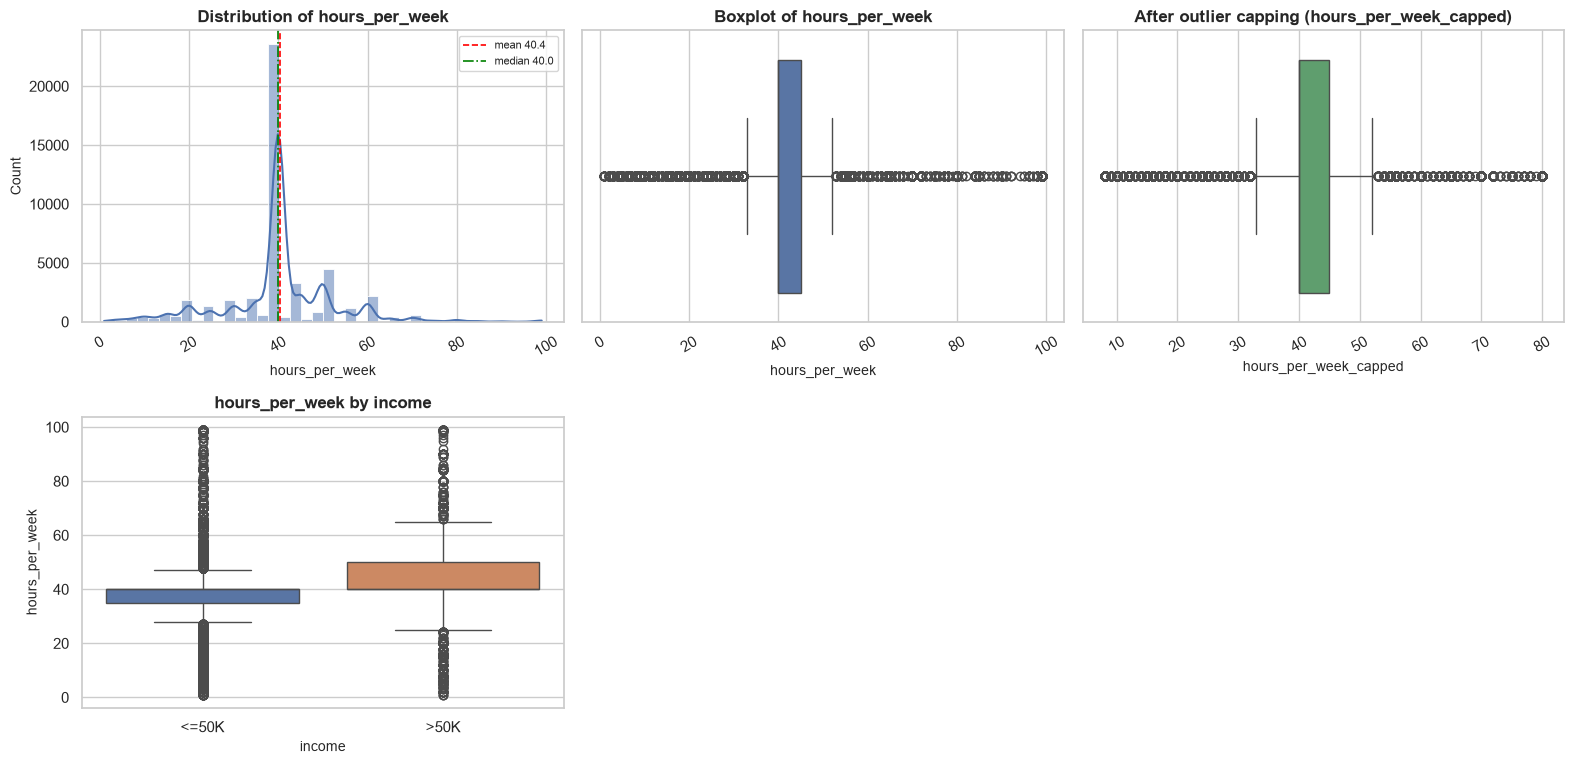

INSIGHTS
  - Distribution is approximately symmetric (skew = 0.24); mean = 40.43, median = 40.00.
  - 13,486 IQR outliers (27.64%) outside [32.50, 52.50].
  - Median of hours_per_week by income: <=50K = 40.00, >50K = 40.00.


In [48]:
num_profile(adult, 'hours_per_week', target='income', raw=adult_q, capped="hours_per_week_capped")

,count,percent
hours_group,,
Full-time (30-40),28304,58.012
Overtime (41-50),8909,18.260
Part-time (<30),6143,12.591
Heavy (50+),5434,11.138


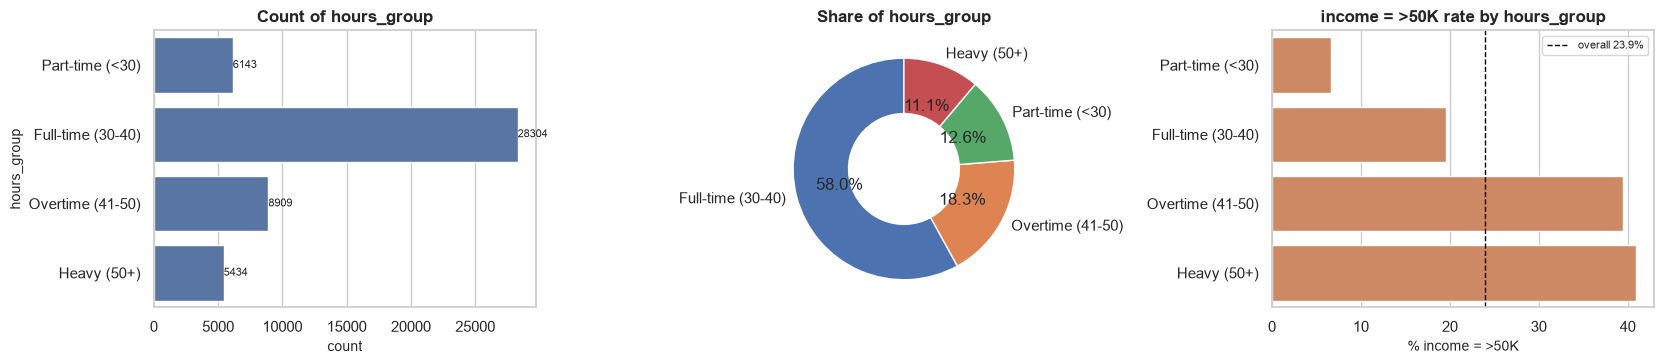

INSIGHTS
  - 4 unique categories; most frequent is "Full-time (30-40)" (58.0%).
  - Highest income=>50K rate: "Heavy (50+)" (40.9%); lowest: "Part-time (<30)" (6.7%).


In [49]:
cat_profile(adult, 'hours_group', target='income', positive='>50K', order=['Part-time (<30)', 'Full-time (30-40)', 'Overtime (41-50)', 'Heavy (50+)'])

### 2.4.14 `native_country`
**Description:** Country of origin (42 countries; top 15 shown).

**Cleaning:** `?` converted to NaN then imputed with the mode (`United-States`); `is_us_native` flag created.

,count,percent
native_country,,
United-States,44648,91.511
Mexico,943,1.933
Philippines,294,0.603
Germany,206,0.422
Puerto-Rico,184,0.377
Canada,182,0.373
El-Salvador,155,0.318
India,151,0.309
Cuba,138,0.283


... 26 more categories not shown (total unique = 41).


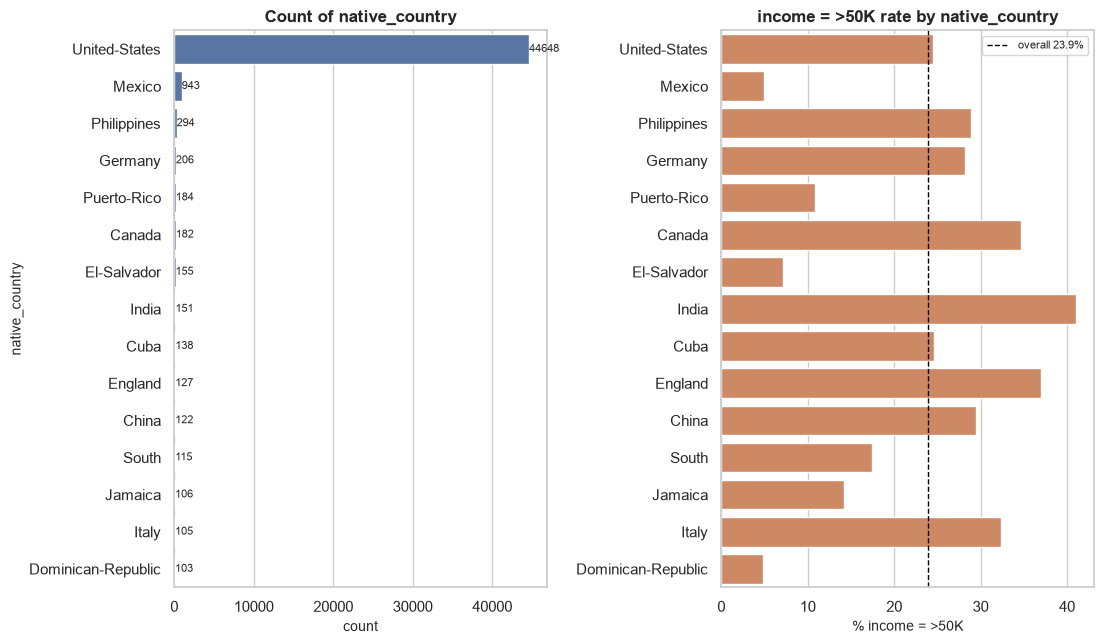

INSIGHTS
  - 41 unique categories; most frequent is "United-States" (91.5%).
  - 39 categories each hold less than 1% of the rows (rare categories).
  - Highest income=>50K rate: "India" (41.1%); lowest: "Dominican-Republic" (4.9%).


In [50]:
cat_profile(adult, 'native_country', target='income', positive='>50K', raw=adult_q, top=15)

### 2.4.15 `income`
**Description:** **Target variable**: yearly income `<=50K` or `>50K`.

**Cleaning:** No missing values; binary copy `income_bin` created.

,count,percent
income,,
<=50K,37109,76.059
>50K,11681,23.941


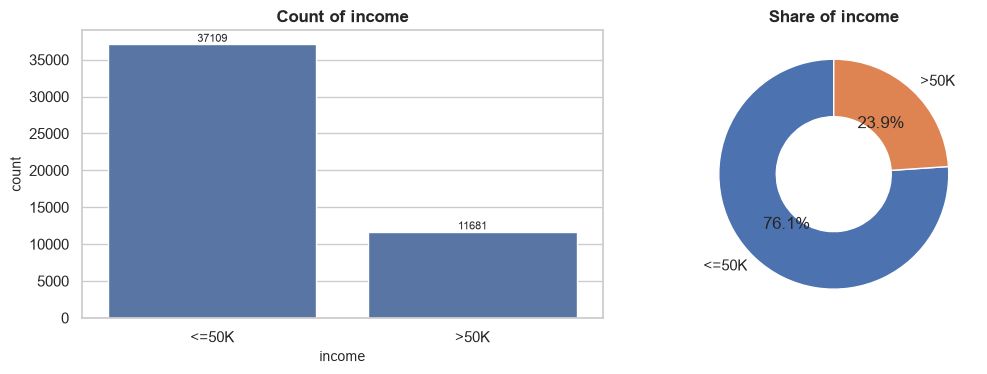

INSIGHTS
  - 2 unique categories; most frequent is "<=50K" (76.1%).
  - Missing values: raw = 0 -> cleaned = 0.
  - Class balance: >50K = 23.9%, <=50K = 76.1% (imbalanced target).


In [51]:
cat_profile(adult, 'income', raw=adult_q)
print(f"  - Class balance: >50K = {(adult['income']=='>50K').mean()*100:.1f}%, <=50K = {(adult['income']=='<=50K').mean()*100:.1f}% (imbalanced target).")

## 2.5 Multivariate analysis

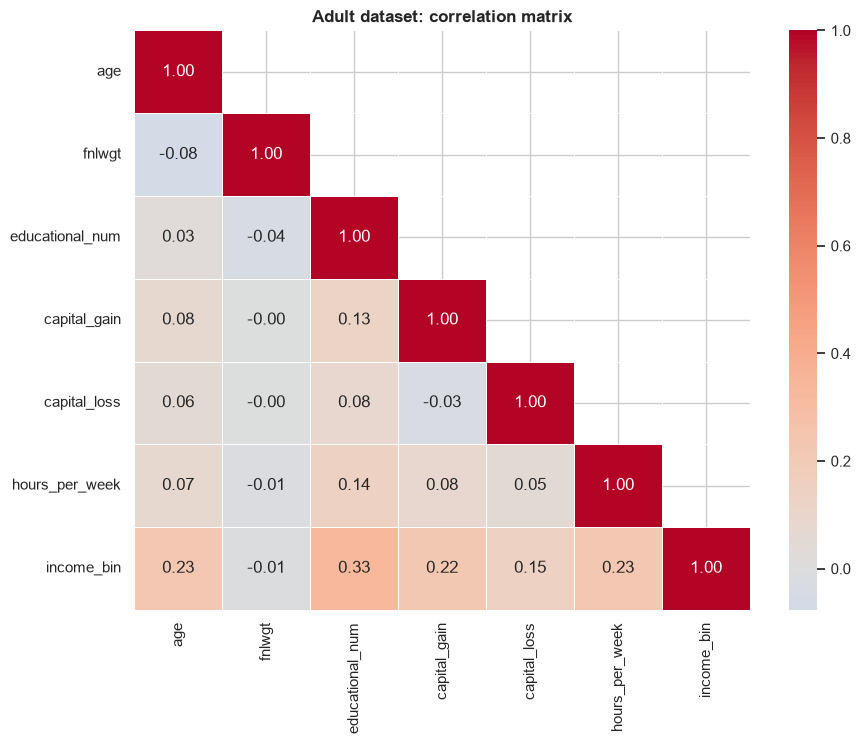

,corr with income_bin
educational_num,0.333
age,0.230
hours_per_week,0.228
capital_gain,0.223
capital_loss,0.148
fnlwgt,-0.006


In [52]:
num_cols = ['age', 'fnlwgt', 'educational_num', 'capital_gain', 'capital_loss', 'hours_per_week', 'income_bin']
corr_adult = corr_heatmap(adult, num_cols, 'Adult dataset: correlation matrix')
display(corr_adult['income_bin'].drop('income_bin').sort_values(ascending=False).to_frame('corr with income_bin'))

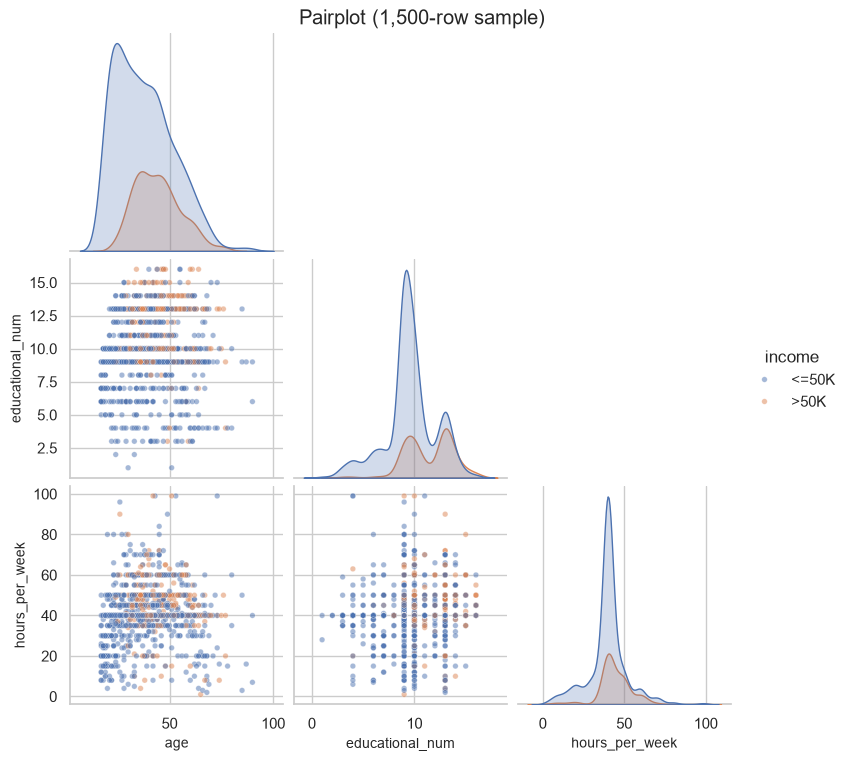

In [53]:
sns.pairplot(adult.sample(1500, random_state=1), vars=['age', 'educational_num', 'hours_per_week'], hue='income', corner=True, plot_kws={'alpha': .5, 's': 16})
plt.suptitle('Pairplot (1,500-row sample)', y=1.01); plt.show()

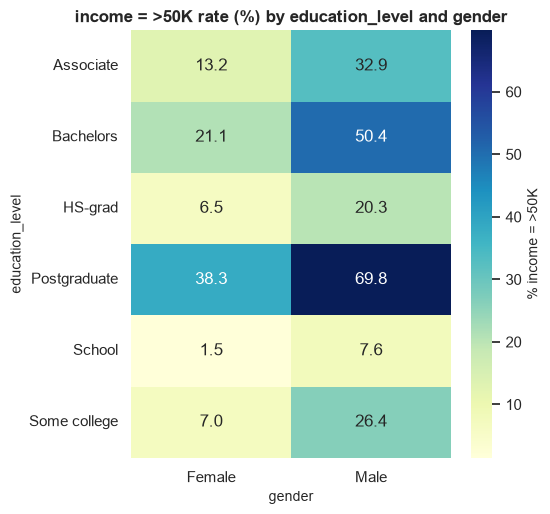

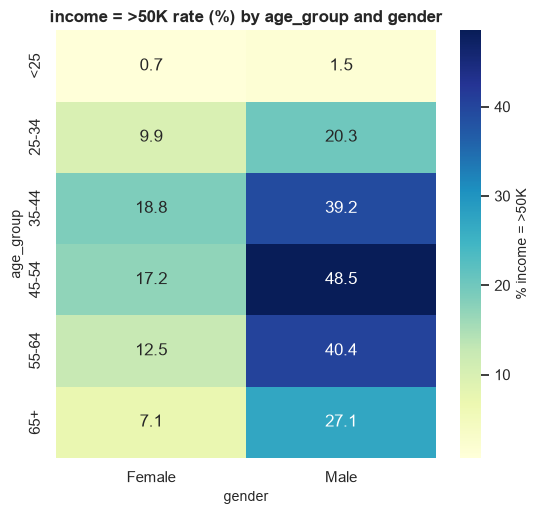

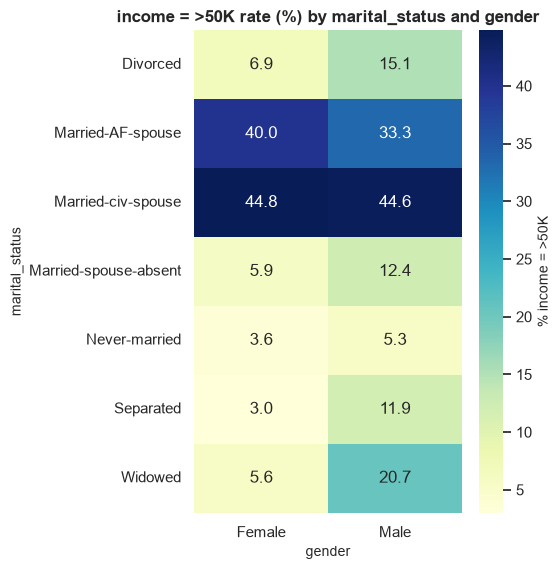

In [54]:
rate_heatmap(adult, 'education_level', 'gender', 'income', '>50K')
rate_heatmap(adult, 'age_group', 'gender', 'income', '>50K')
rate_heatmap(adult, 'marital_status', 'gender', 'income', '>50K')

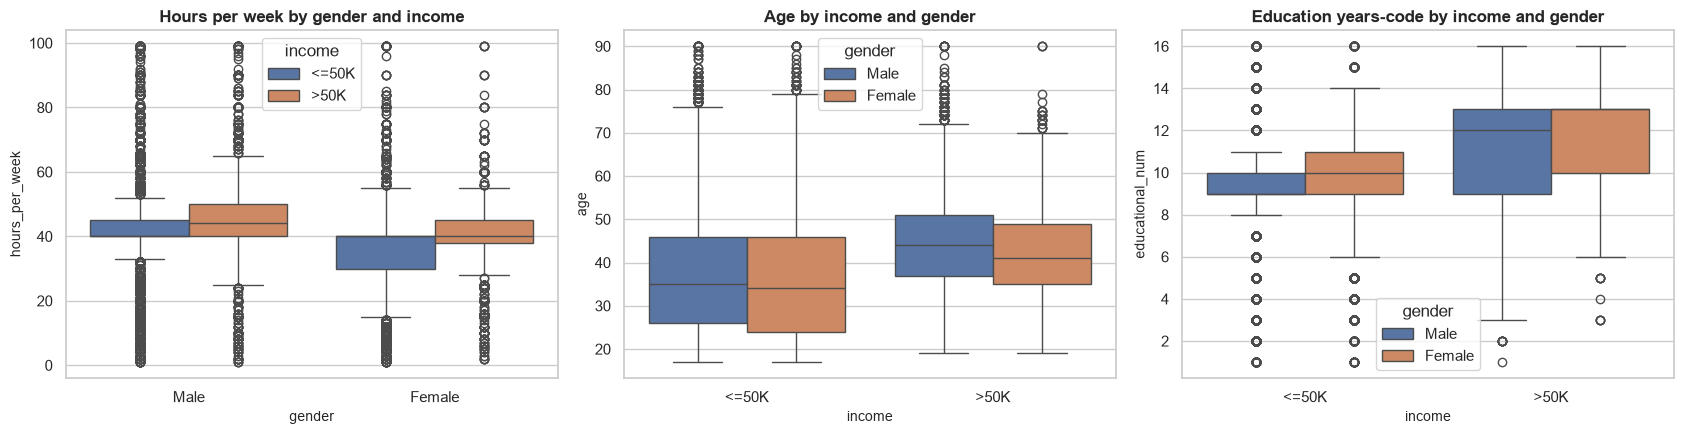

In [55]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
sns.boxplot(data=adult, x='gender', y='hours_per_week', hue='income', ax=ax[0]); ax[0].set_title('Hours per week by gender and income')
sns.boxplot(data=adult, x='income', y='age', hue='gender', ax=ax[1]); ax[1].set_title('Age by income and gender')
sns.boxplot(data=adult, x='income', y='educational_num', hue='gender', ax=ax[2]); ax[2].set_title('Education years-code by income and gender')
plt.tight_layout(); plt.show()

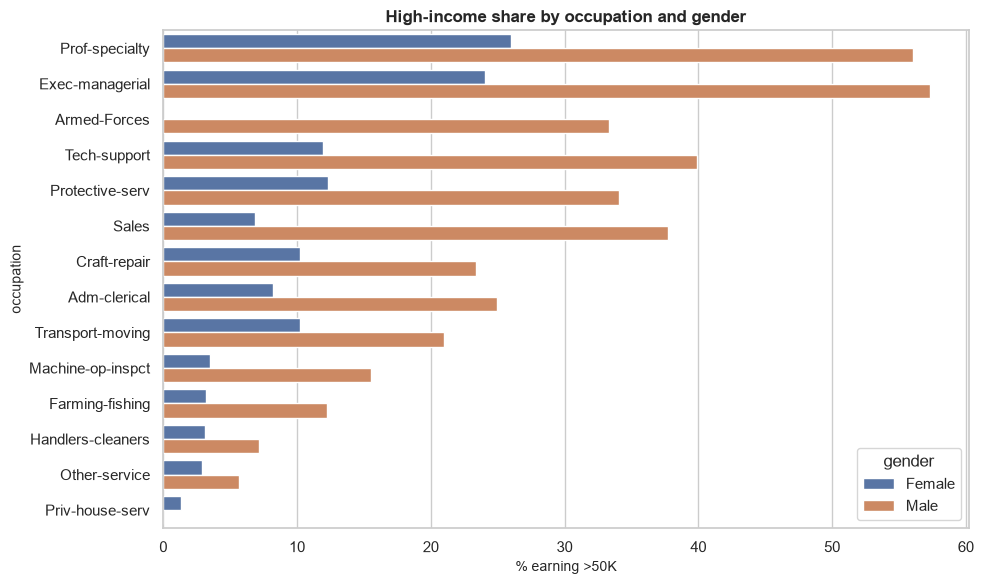

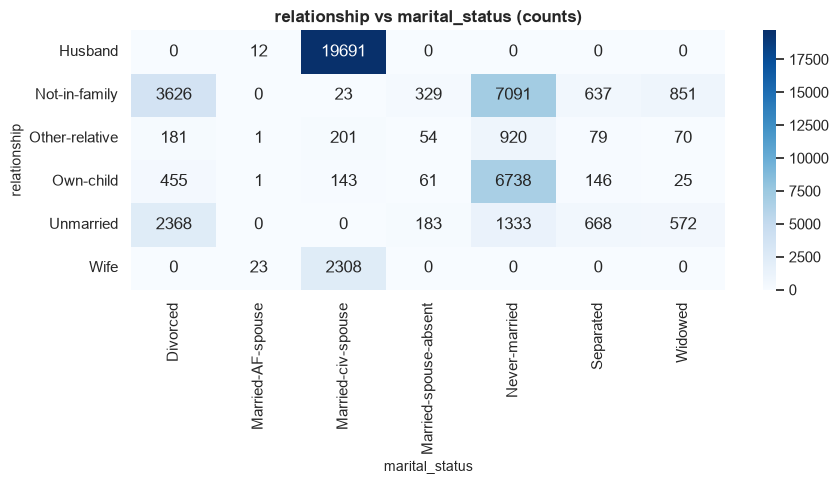

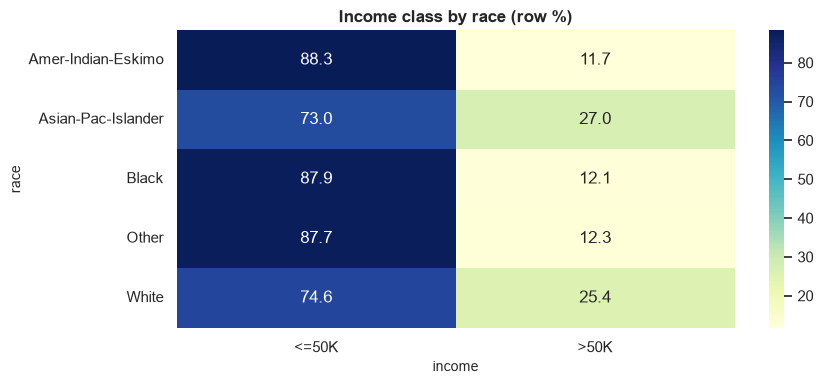

In [56]:
occ = adult[adult['occupation'] != 'Unknown'].groupby(['occupation', 'gender'])['income_bin'].mean().mul(100).reset_index()
order = occ.groupby('occupation')['income_bin'].mean().sort_values(ascending=False).index
plt.figure(figsize=(10, 6)); sns.barplot(data=occ, y='occupation', x='income_bin', hue='gender', order=order)
plt.xlabel('% earning >50K'); plt.title('High-income share by occupation and gender'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
sns.heatmap(pd.crosstab(adult['relationship'], adult['marital_status']), annot=True, fmt='d', cmap='Blues')
plt.title('relationship vs marital_status (counts)'); plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 4)); sns.heatmap(pd.crosstab(adult['race'], adult['income'], normalize='index').mul(100), annot=True, fmt='.1f', cmap='YlGnBu')
plt.title('Income class by race (row %)'); plt.tight_layout(); plt.show()

## 2.6 Key findings: Adult dataset

In [57]:
hi = adult['income_bin'].mean() * 100
g = adult.groupby('gender')['income_bin'].mean() * 100
ms = adult.groupby('marital_status')['income_bin'].mean().mul(100).sort_values(ascending=False)
ed = adult.groupby('education_level')['income_bin'].mean().mul(100)
print(f'1. {hi:.1f}% of people earn >50K (imbalanced target).')
print(f'2. High-income share: Male {g["Male"]:.1f}% vs Female {g["Female"]:.1f}%.')
print(f'3. High-income share by education level: ' + ', '.join(f'{k} {v:.1f}%' for k, v in ed.sort_values().items()) + '.')
print(f'4. Marital status with the highest high-income share: {ms.index[0]} ({ms.iloc[0]:.1f}%); lowest: {ms.index[-1]} ({ms.iloc[-1]:.1f}%).')
cs = corr_adult['income_bin'].drop('income_bin')
print(f'5. Strongest numeric correlation with income: {cs.abs().idxmax()} (r = {cs[cs.abs().idxmax()]:.2f}).')
print(f'6. capital_gain is zero for {(adult.capital_gain==0).mean()*100:.1f}% of rows; capital_loss is zero for {(adult.capital_loss==0).mean()*100:.1f}%.')
print(f'7. Cleaning: {len(adult_raw) - len(adult)} duplicate rows dropped; {int(adult_q.isna().sum().sum())} "?" cells handled in workclass / occupation / native_country.')
adult.to_csv('data/adult_cleaned.csv', index=False)
print('\nCleaned data saved to data/adult_cleaned.csv ->', adult.shape)

1. 23.9% of people earn >50K (imbalanced target).
2. High-income share: Male 30.4% vs Female 10.9%.
3. High-income share by education level: School 5.7%, HS-grad 15.9%, Some college 19.0%, Associate 25.5%, Bachelors 41.3%, Postgraduate 61.4%.
4. Marital status with the highest high-income share: Married-civ-spouse (44.6%); lowest: Never-married (4.6%).
5. Strongest numeric correlation with income: educational_num (r = 0.33).
6. capital_gain is zero for 91.7% of rows; capital_loss is zero for 95.3%.
7. Cleaning: 52 duplicate rows dropped; 6465 "?" cells handled in workclass / occupation / native_country.

Cleaned data saved to data/adult_cleaned.csv -> (48790, 28)


**Conclusion (Adult):** hidden missing values (`?`) and 52 duplicate rows were handled and every column was profiled. About 23.9% of people earn >50K. The high-income share rises steadily with education (5.7% for school-level up to 61.4% for postgraduates), is much higher for men than women (30.4% vs 10.9%) and for married-civ-spouse people (44.6%) than for never-married people (4.6%). `educational_num` has the strongest numeric correlation with income (r = 0.33), and capital gain / loss are zero for more than 90% of rows.

---
# PART 3: Hotel Booking Dataset
**Goal:** understand booking behaviour of a *City Hotel* and a *Resort Hotel*, and what relates to cancellations (`is_canceled`).

## 3.1 Load the data & first look

In [58]:
hotel_raw = pd.read_csv(HOTEL_PATH)
overview(hotel_raw, 'Hotel booking dataset (raw)')

Hotel booking dataset (raw): 119,390 rows x 36 columns
Memory usage: 48.78 MB



,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,name,email,phone-number,credit_card
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01,Ernest Barnes,Ernest.Barnes31@outlook.com,669-792-1661,************4322
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.000,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.000,0,0,Check-Out,2015-07-01,Andrea Baker,Andrea_Baker94@aol.com,858-637-6955,************9157
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02,Rebecca Parker,Rebecca_Parker@comcast.net,652-885-2745,************3734
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.000,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.000,NaN,0,Transient,75.000,0,0,Check-Out,2015-07-02,Laura Murray,Laura_M@gmail.com,364-656-8427,************5677
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.000,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.000,NaN,0,Transient,98.000,0,1,Check-Out,2015-07-03,Linda Hines,LHines@verizon.com,713-226-5883,************5498



--- df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 36 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal    

,count,mean,std,min,25%,50%,75%,max
is_canceled,"119,390.000",0.370,0.483,0.000,0.000,0.000,1.000,1.000
lead_time,"119,390.000",104.011,106.863,0.000,18.000,69.000,160.000,737.000
arrival_date_year,"119,390.000","2,016.157",0.707,"2,015.000","2,016.000","2,016.000","2,017.000","2,017.000"
arrival_date_week_number,"119,390.000",27.165,13.605,1.000,16.000,28.000,38.000,53.000
arrival_date_day_of_month,"119,390.000",15.798,8.781,1.000,8.000,16.000,23.000,31.000
stays_in_weekend_nights,"119,390.000",0.928,0.999,0.000,0.000,1.000,2.000,19.000
stays_in_week_nights,"119,390.000",2.500,1.908,0.000,1.000,2.000,3.000,50.000
adults,"119,390.000",1.856,0.579,0.000,2.000,2.000,2.000,55.000
children,"119,386.000",0.104,0.399,0.000,0.000,0.000,0.000,10.000
babies,"119,390.000",0.008,0.097,0.000,0.000,0.000,0.000,10.000



--- Non-numeric summary ---


,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


### Column dictionary
| Column | Meaning |
|---|---|
| hotel | Resort Hotel or City Hotel |
| **is_canceled** | **Target**: 1 = booking cancelled, 0 = not cancelled |
| lead_time | Days between booking and arrival |
| arrival_date_year / month / week_number / day_of_month | Arrival date parts |
| stays_in_weekend_nights / stays_in_week_nights | Weekend / week nights booked |
| adults / children / babies | Guests |
| meal | BB bed & breakfast, HB half board, FB full board, SC / Undefined no meal package |
| country | Guest country (ISO code) |
| market_segment / distribution_channel | How the booking was sold (TA = travel agent, TO = tour operator) |
| is_repeated_guest | 1 = guest has booked before |
| previous_cancellations / previous_bookings_not_canceled | Guest history |
| reserved_room_type / assigned_room_type | Room type booked vs. actually given (coded letters) |
| booking_changes | Number of changes made to the booking |
| deposit_type | No Deposit / Refundable / Non Refund |
| agent / company | ID of the travel agent / company that made the booking |
| days_in_waiting_list | Days on the waiting list before confirmation |
| customer_type | Contract / Group / Transient / Transient-Party |
| adr | Average daily rate (price per night) |
| required_car_parking_spaces / total_of_special_requests | Guest requests |
| reservation_status / reservation_status_date | Final status (Check-Out / Canceled / No-Show) and its date |
| name / email / phone-number / credit_card | Personal data (PII) |

## 3.2 Data-quality audit (before cleaning)

Exact duplicate rows: 0
Duplicate rows when personal-data columns are ignored: 31994 (identical bookings by different guests are normal, so these are NOT dropped)


,missing,percent
company,112593,94.307
agent,16340,13.686
country,488,0.409
children,4,0.003


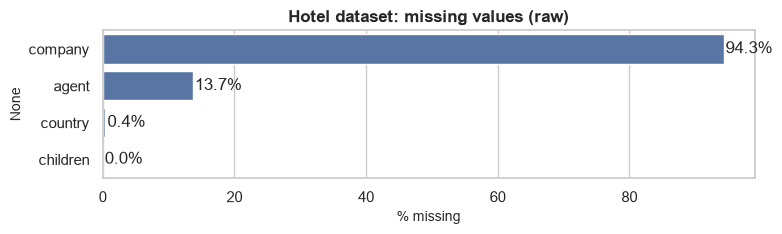

In [59]:
pii_cols = ['name', 'email', 'phone-number', 'credit_card']
print('Exact duplicate rows:', hotel_raw.duplicated().sum())
print('Duplicate rows when personal-data columns are ignored:', hotel_raw.drop(columns=pii_cols).duplicated().sum(),
      '(identical bookings by different guests are normal, so these are NOT dropped)')
rep = missing_report(hotel_raw, 'Hotel dataset: missing values (raw)')

In [60]:
print('--- Logical checks ---')
guests = hotel_raw['adults'] + hotel_raw['children'].fillna(0) + hotel_raw['babies']
nights = hotel_raw['stays_in_weekend_nights'] + hotel_raw['stays_in_week_nights']
print('Bookings with ZERO guests            :', (guests == 0).sum())
print('Bookings with ZERO nights            :', (nights == 0).sum())
print('Negative adr (price)                 :', (hotel_raw['adr'] < 0).sum(), '| adr == 0:', (hotel_raw['adr'] == 0).sum(), '| adr max:', hotel_raw['adr'].max())
print('adults >= 10                         :', (hotel_raw['adults'] >= 10).sum(), '| max adults:', hotel_raw['adults'].max())
print("'Undefined' in meal / market_segment / distribution_channel:", (hotel_raw['meal'] == 'Undefined').sum(), (hotel_raw['market_segment'] == 'Undefined').sum(), (hotel_raw['distribution_channel'] == 'Undefined').sum())
print('Reserved room type != assigned room type:', (hotel_raw['reserved_room_type'] != hotel_raw['assigned_room_type']).sum())
print('\nis_canceled vs reservation_status (data-leakage check):'); display(pd.crosstab(hotel_raw['is_canceled'], hotel_raw['reservation_status']))
print('Personal-data format checks:')
print('  invalid e-mails      :', (~hotel_raw['email'].str.match(r'^[\w.+-]+@[\w-]+\.[\w.]+$')).sum())
print('  phone not NNN-NNN-NNNN:', (~hotel_raw['phone-number'].str.match(r'^\d{3}-\d{3}-\d{4}$')).sum())
print('  card not ************NNNN:', (~hotel_raw['credit_card'].str.match(r'^\*{12}\d{4}$')).sum())
text_cols = [c for c in hotel_raw.columns if not pd.api.types.is_numeric_dtype(hotel_raw[c])]
print('\nText values with leading/trailing whitespace:', {c: int((hotel_raw[c].dropna() != hotel_raw[c].dropna().str.strip()).sum()) for c in text_cols if (hotel_raw[c].dropna() != hotel_raw[c].dropna().str.strip()).sum() > 0} or 'none')

--- Logical checks ---
Bookings with ZERO guests            : 180
Bookings with ZERO nights            : 715
Negative adr (price)                 : 1 | adr == 0: 1959 | adr max: 5400.0
adults >= 10                         : 13 | max adults: 55
'Undefined' in meal / market_segment / distribution_channel: 1169 2 5
Reserved room type != assigned room type: 14917

is_canceled vs reservation_status (data-leakage check):


reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,75166,0
1,43017,0,1207


Personal-data format checks:
  invalid e-mails      : 0
  phone not NNN-NNN-NNNN: 0
  card not ************NNNN: 0

Text values with leading/trailing whitespace: none


## 3.3 Data cleaning

**Cleaning plan (and why)**

| Issue | Treatment | Reason |
|---|---|---|
| `children` missing (4) | fill with 0 | tiny number, 0 is the mode |
| `country` missing (488) | label `Unknown` | keeps rows without inventing a country |
| `agent` missing | 0 = "no agent" (+ `has_agent`) | missing means booked without an agent |
| `company` missing (~94%) | 0 = "no company" (+ `has_company`) | missing means no company booking; too sparse to impute |
| `meal` = `Undefined` | merged into `SC` | both mean "no meal package" |
| `market_segment`, `distribution_channel` = `Undefined` (few rows) | replaced by the mode | negligible number of rows |
| Bookings with 0 guests | rows dropped | impossible bookings |
| Negative `adr` | row dropped | a price cannot be negative |
| 0-night stays | flagged in `zero_night_stay`, kept | mostly no-shows / same-day cases |
| Extreme values (adr = 5400, 55 adults, ...) | 1-99 percentile capping into `*_capped` | originals preserved |
| Date columns | converted to datetime, ordered month category, `arrival_date` built | enables time analysis |
| `reservation_status` | kept for analysis but flagged as **leakage** | it reveals the target |
| PII columns | analysed, then removed from the final dataset | privacy |

In [61]:
hotel = hotel_raw.copy()
hlog = []
def hl(step, detail): hlog.append({'step': step, 'detail': detail})

# 1) whitespace
for c in [c for c in hotel.columns if not pd.api.types.is_numeric_dtype(hotel[c])]:
    hotel[c] = hotel[c].str.strip()

# 2) missing values
n = hotel['children'].isna().sum(); hotel['children'] = hotel['children'].fillna(0).astype(int); hl('Impute children', f'{n} missing -> 0')
n = hotel['country'].isna().sum(); hotel['country'] = hotel['country'].fillna('Unknown'); hl('Impute country', f"{n} missing -> 'Unknown'")
n = hotel['agent'].isna().sum(); hotel['has_agent'] = hotel['agent'].notna().astype(int); hotel['agent'] = hotel['agent'].fillna(0).astype(int); hl('Impute agent', f'{n} missing -> 0 (no agent)')
n = hotel['company'].isna().sum(); hotel['has_company'] = hotel['company'].notna().astype(int); hotel['company'] = hotel['company'].fillna(0).astype(int); hl('Impute company', f'{n} missing -> 0 (no company)')

# 3) 'Undefined' categories
n = (hotel['meal'] == 'Undefined').sum(); hotel['meal'] = hotel['meal'].replace('Undefined', 'SC'); hl('meal Undefined -> SC', f'{n} rows')
for c in ['market_segment', 'distribution_channel']:
    mode = hotel.loc[hotel[c] != 'Undefined', c].mode()[0]
    n = (hotel[c] == 'Undefined').sum(); hotel[c] = hotel[c].replace('Undefined', mode); hl(f'{c} Undefined -> mode', f'{n} rows -> {mode}')

# 4) impossible rows
before = len(hotel)
zero_guests = (hotel['adults'] + hotel['children'] + hotel['babies']) == 0
hotel = hotel[~zero_guests]; hl('Drop zero-guest bookings', f'{int(zero_guests.sum())} rows')
neg = hotel['adr'] < 0; hotel = hotel[~neg]; hl('Drop negative adr', f'{int(neg.sum())} rows')
hotel = hotel.reset_index(drop=True)

# 5) dates
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
hotel['arrival_date_month'] = pd.Categorical(hotel['arrival_date_month'], categories=month_order, ordered=True)
hotel['arrival_date'] = pd.to_datetime(pd.DataFrame({'year': hotel['arrival_date_year'], 'month': hotel['arrival_date_month'].cat.codes + 1, 'day': hotel['arrival_date_day_of_month']}), errors='coerce')
hotel['reservation_status_date'] = pd.to_datetime(hotel['reservation_status_date'], errors='coerce')
hl('Dates', f"arrival_date built (NaT: {int(hotel['arrival_date'].isna().sum())}); reservation_status_date -> datetime (NaT: {int(hotel['reservation_status_date'].isna().sum())})")

# 6) outlier capping (1-99 percentile)
cap_log = [winsor(hotel, c) for c in ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'booking_changes', 'days_in_waiting_list', 'adr']]
hl('Cap outliers', ', '.join(d['new_column'] for d in cap_log))
display(pd.DataFrame(cap_log))

# 7) feature engineering
hotel['total_nights'] = hotel['stays_in_weekend_nights'] + hotel['stays_in_week_nights']
hotel['zero_night_stay'] = (hotel['total_nights'] == 0).astype(int)
hotel['total_guests'] = hotel['adults'] + hotel['children'] + hotel['babies']
hotel['is_family'] = ((hotel['children'] + hotel['babies']) > 0).astype(int)
hotel['room_changed'] = (hotel['reserved_room_type'] != hotel['assigned_room_type']).astype(int)
hotel['total_revenue'] = hotel['adr'] * hotel['total_nights']
hotel['lead_time_group'] = pd.cut(hotel['lead_time'], [-1, 7, 30, 90, 180, 365, 1000], labels=['0-7 d', '8-30 d', '31-90 d', '91-180 d', '181-365 d', '>365 d'])
hotel['email_domain'] = hotel['email'].str.extract(r'@(.+)$')[0].str.lower()
hotel['card_bookings'] = hotel.groupby('credit_card')['credit_card'].transform('size')
hl('Feature engineering', 'total_nights, zero_night_stay, total_guests, is_family, room_changed, total_revenue, lead_time_group, email_domain, card_bookings')

print('Rows:', len(hotel_raw), '->', len(hotel), f'({len(hotel_raw) - len(hotel)} removed)')
print('Remaining missing values (excluding none):', int(hotel.drop(columns=[]).isna().sum().sum()))
display(pd.DataFrame(hlog))

,column,method,lower,upper,values_capped,new_column
0,lead_time,1-99 percentile,0.000,444.000,1178,lead_time_capped
1,stays_in_weekend_nights,1-99 percentile,0.000,4.000,335,stays_in_weekend_nights_capped
2,stays_in_week_nights,1-99 percentile,0.000,10.000,394,stays_in_week_nights_capped
3,adults,1-99 percentile,1.000,3.000,301,adults_capped
4,booking_changes,1-99 percentile,0.000,3.000,618,booking_changes_capped
5,days_in_waiting_list,1-99 percentile,0.000,75.000,1175,days_in_waiting_list_capped
6,adr,1-99 percentile,0.000,252.000,1168,adr_capped


Rows: 119390 -> 119209 (181 removed)
Remaining missing values (excluding none): 0


,step,detail
0,Impute children,4 missing -> 0
1,Impute country,488 missing -> 'Unknown'
2,Impute agent,16340 missing -> 0 (no agent)
3,Impute company,112593 missing -> 0 (no company)
4,meal Undefined -> SC,1169 rows
5,market_segment Undefined -> mode,2 rows -> Online TA
6,distribution_channel Undefined -> mode,5 rows -> TA/TO
7,Drop zero-guest bookings,180 rows
8,Drop negative adr,1 rows
9,Dates,arrival_date built (NaT: 0); reservation_statu...


## 3.4 Column-by-column analysis

### 3.4.1 `hotel`
**Description:** Hotel type: City Hotel or Resort Hotel.

**Cleaning:** No missing values.

,count,percent
hotel,,
City Hotel,79163,66.407
Resort Hotel,40046,33.593


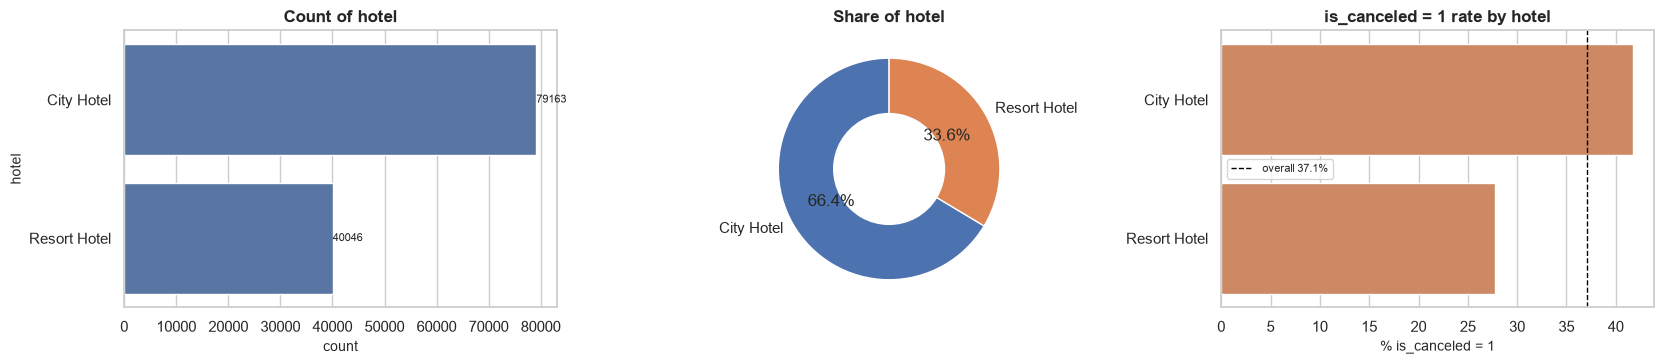

INSIGHTS
  - 2 unique categories; most frequent is "City Hotel" (66.4%).
  - Highest is_canceled=1 rate: "City Hotel" (41.8%); lowest: "Resort Hotel" (27.8%).
  - Missing values: raw = 0 -> cleaned = 0.


In [62]:
cat_profile(hotel, 'hotel', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.2 `is_canceled`
**Description:** **Target**: 1 = booking was cancelled.

**Cleaning:** No missing values.

,count,percent
is_canceled,,
0,75010,62.923
1,44199,37.077


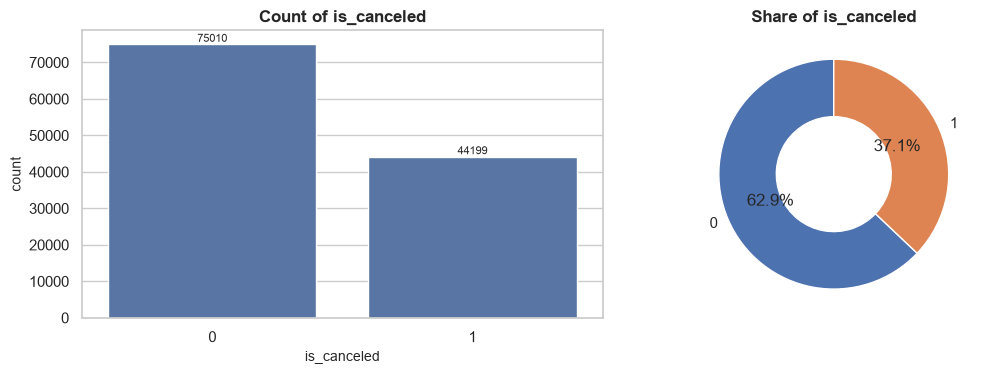

INSIGHTS
  - 2 unique categories; most frequent is "0" (62.9%).
  - Missing values: raw = 0 -> cleaned = 0.
  - Cancellation rate: 37.1% of bookings were cancelled.


In [63]:
cat_profile(hotel, 'is_canceled', raw=hotel_raw)
print(f"  - Cancellation rate: {hotel['is_canceled'].mean()*100:.1f}% of bookings were cancelled.")

### 3.4.3 `lead_time`
**Description:** Days between booking date and arrival date.

**Cleaning:** No missing; capped in `lead_time_capped`; `lead_time_group` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
lead_time,119209,0,479,104.108,69.000,106.876,0,737,1.346,1.694


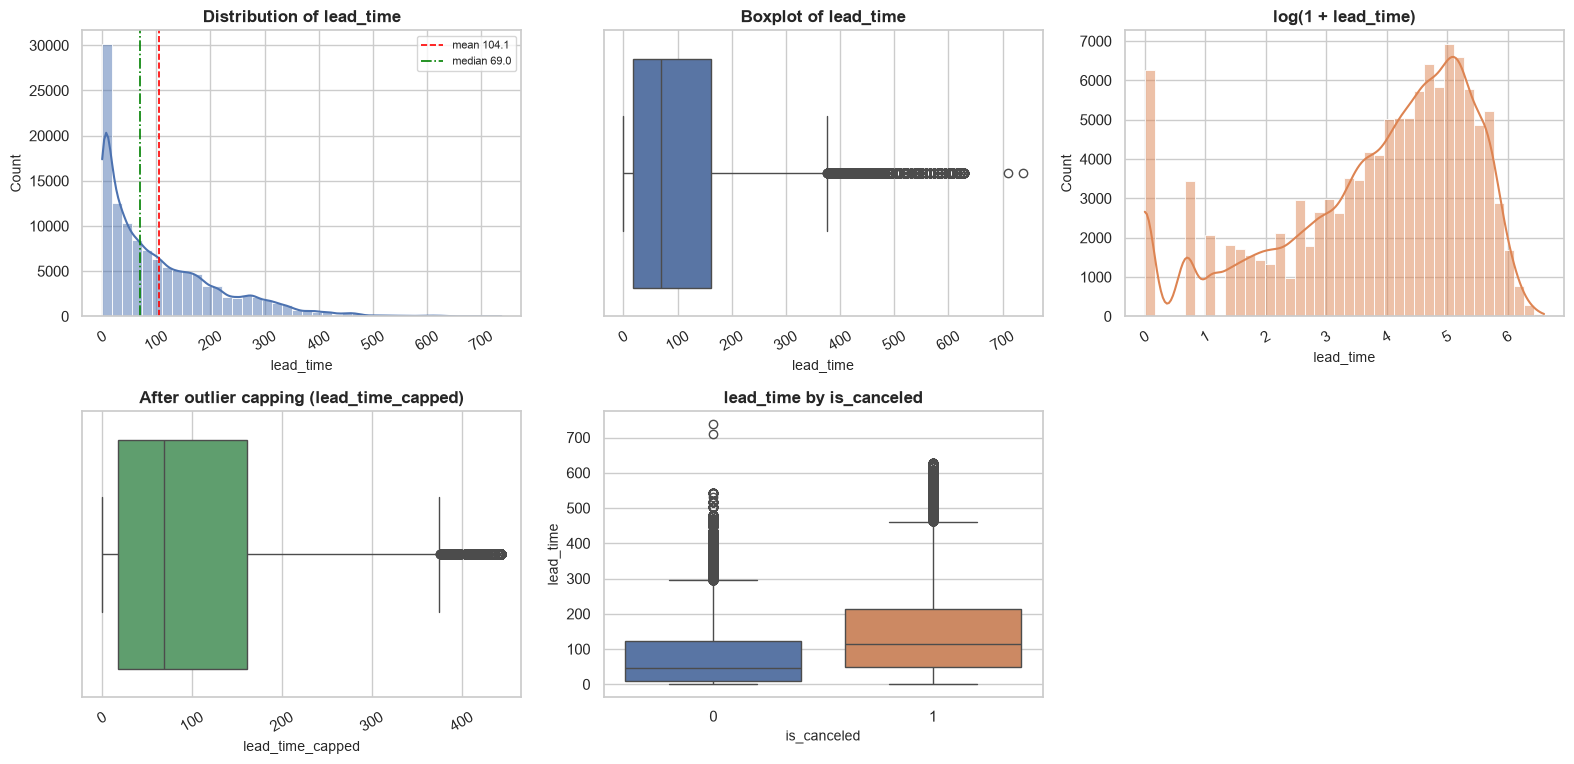

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.35); mean = 104.11, median = 69.00.
  - 2,981 IQR outliers (2.50%) outside [-196.50, 375.50].
  - 5.3% of the values are exactly 0.
  - Median of lead_time by is_canceled: 0 = 45.00, 1 = 113.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [64]:
num_profile(hotel, 'lead_time', target='is_canceled', raw=hotel_raw, capped="lead_time_capped")

,count,percent
lead_time_group,,
31-90 d,29529,24.771
91-180 d,26420,22.163
181-365 d,21533,18.063
0-7 d,19635,16.471
8-30 d,18945,15.892
>365 d,3147,2.640


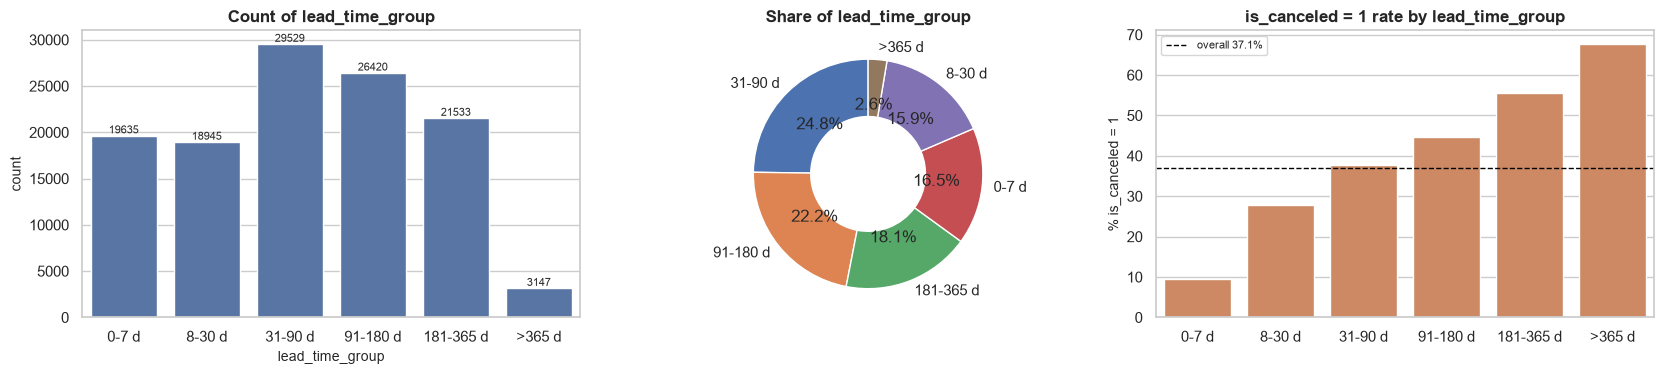

INSIGHTS
  - 6 unique categories; most frequent is "31-90 d" (24.8%).
  - Highest is_canceled=1 rate: ">365 d" (67.7%); lowest: "0-7 d" (9.6%).


In [65]:
cat_profile(hotel, 'lead_time_group', target='is_canceled', positive=1, order=['0-7 d', '8-30 d', '31-90 d', '91-180 d', '181-365 d', '>365 d'])

### 3.4.4 `arrival_date_year`
**Description:** Year of arrival (2015 - 2017).

**Cleaning:** No missing values.

,count,percent
arrival_date_year,,
2016,56623,47.499
2017,40619,34.074
2015,21967,18.427


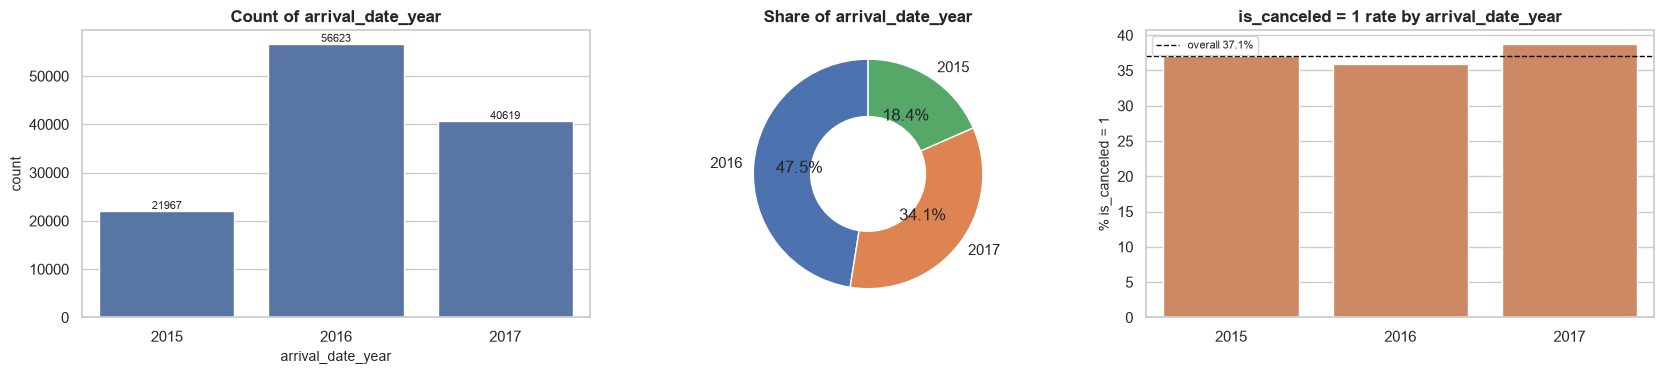

INSIGHTS
  - 3 unique categories; most frequent is "2016" (47.5%).
  - Highest is_canceled=1 rate: "2017" (38.7%); lowest: "2016" (35.9%).
  - Missing values: raw = 0 -> cleaned = 0.


In [66]:
cat_profile(hotel, 'arrival_date_year', target='is_canceled', positive=1, raw=hotel_raw, order=[2015, 2016, 2017])

### 3.4.5 `arrival_date_month`
**Description:** Month of arrival.

**Cleaning:** Converted to an ordered categorical (January ... December).

,count,percent
arrival_date_month,,
August,13861,11.627
July,12644,10.607
May,11780,9.882
October,11147,9.351
April,11078,9.293
June,10929,9.168
September,10500,8.808
March,9767,8.193
February,8052,6.755


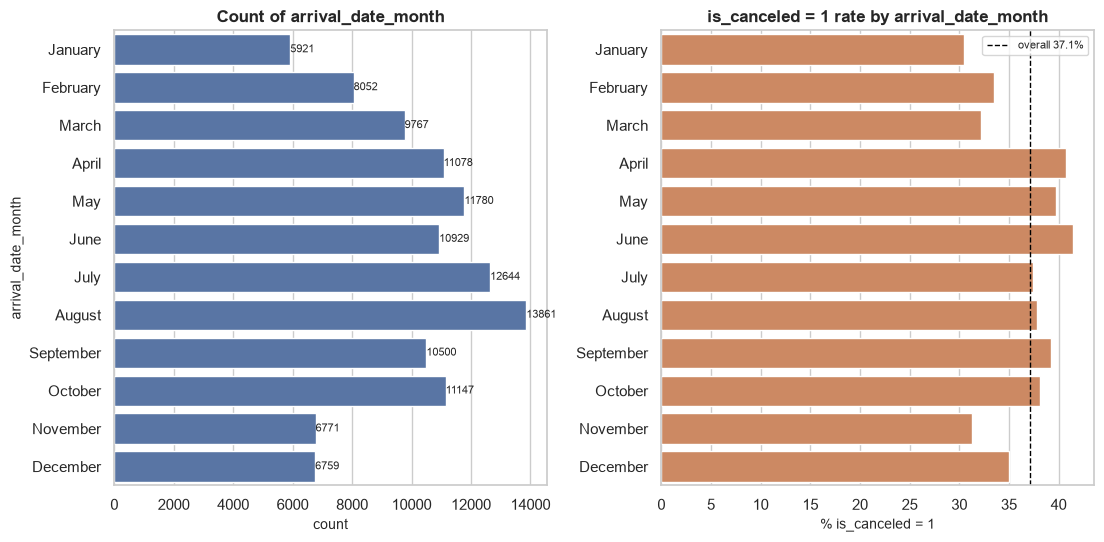

INSIGHTS
  - 12 unique categories; most frequent is "August" (11.6%).
  - Highest is_canceled=1 rate: "June" (41.5%); lowest: "January" (30.5%).
  - Missing values: raw = 0 -> cleaned = 0.


In [67]:
cat_profile(hotel, 'arrival_date_month', target='is_canceled', positive=1, raw=hotel_raw, order=month_order)

### 3.4.6 `arrival_date_week_number`
**Description:** ISO week number of arrival (1 - 53).

**Cleaning:** No missing values.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
arrival_date_week_number,119209,0,53,27.164,28.000,13.601,1,53,-0.010,-0.985


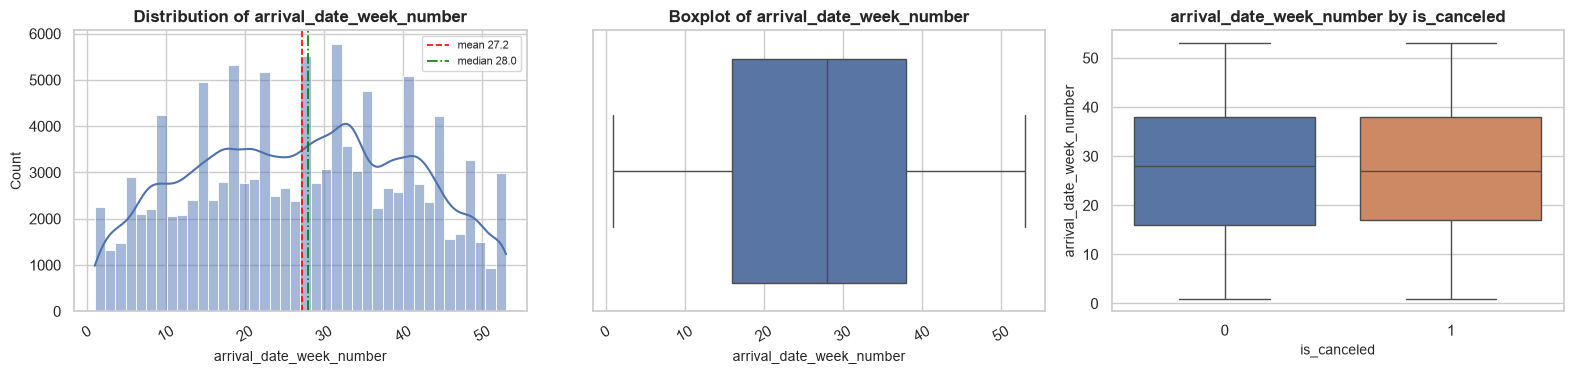

INSIGHTS
  - Distribution is approximately symmetric (skew = -0.01); mean = 27.16, median = 28.00.
  - 0 IQR outliers (0.00%) outside [-17.00, 71.00].
  - Median of arrival_date_week_number by is_canceled: 0 = 28.00, 1 = 27.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [68]:
num_profile(hotel, 'arrival_date_week_number', target='is_canceled', raw=hotel_raw)

### 3.4.7 `arrival_date_day_of_month`
**Description:** Day of the month of arrival.

**Cleaning:** No missing values; combined with year and month into `arrival_date`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
arrival_date_day_of_month,119209,0,31,15.799,16.000,8.781,1,31,-0.002,-1.187


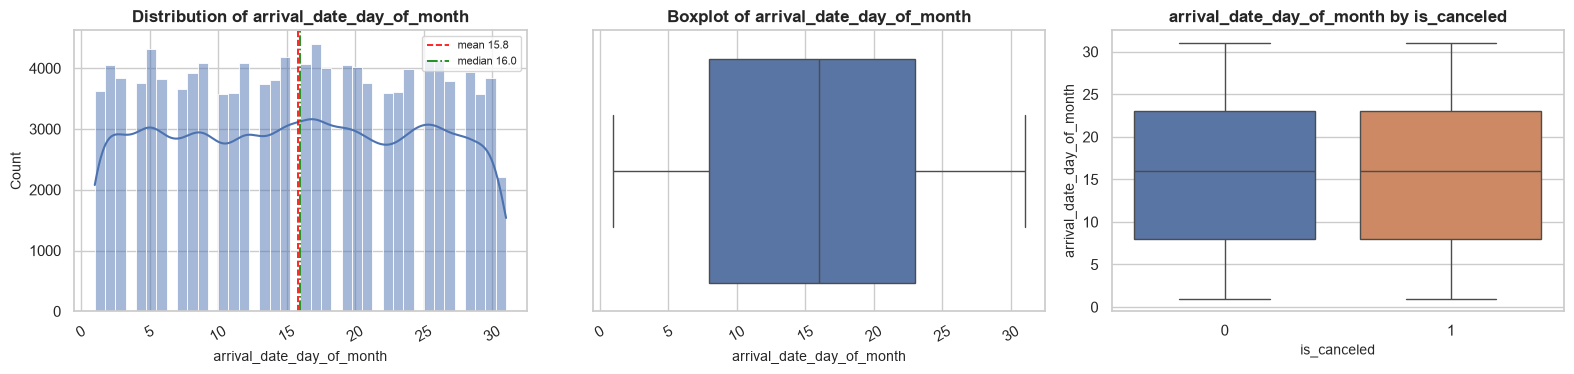

INSIGHTS
  - Distribution is approximately symmetric (skew = -0.00); mean = 15.80, median = 16.00.
  - 0 IQR outliers (0.00%) outside [-14.50, 45.50].
  - Median of arrival_date_day_of_month by is_canceled: 0 = 16.00, 1 = 16.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [69]:
num_profile(hotel, 'arrival_date_day_of_month', target='is_canceled', raw=hotel_raw)

### 3.4.8 `stays_in_weekend_nights`
**Description:** Number of weekend nights (Sat/Sun) booked.

**Cleaning:** No missing; capped in `stays_in_weekend_nights_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
stays_in_weekend_nights,119209,0,17,0.927,1.000,0.995,0,19,1.320,6.366


Value counts:


stays_in_weekend_nights,0,1,2,3,4,5,6,7,8,9,10,12
count,51895,30615,33266,1252,1846,77,152,19,58,10,7,5


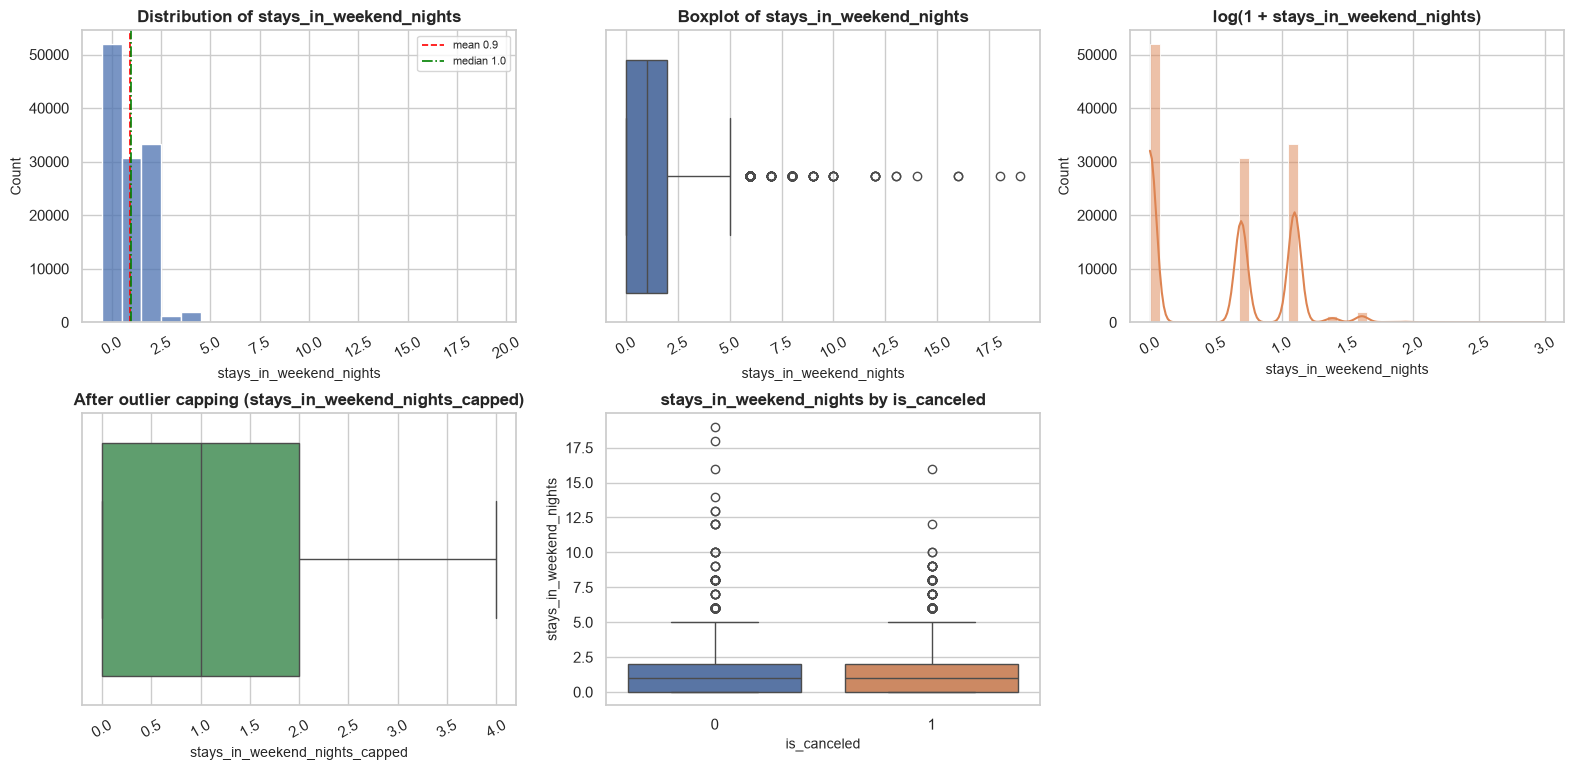

INSIGHTS
  - Distribution is highly skewed to the right (skew = 1.32); mean = 0.93, median = 1.00.
  - 258 IQR outliers (0.22%) outside [-3.00, 5.00].
  - 43.5% of the values are exactly 0.
  - Median of stays_in_weekend_nights by is_canceled: 0 = 1.00, 1 = 1.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [70]:
num_profile(hotel, 'stays_in_weekend_nights', target='is_canceled', raw=hotel_raw, capped="stays_in_weekend_nights_capped")

### 3.4.9 `stays_in_week_nights`
**Description:** Number of week nights (Mon-Fri) booked.

**Cleaning:** No missing; capped in `stays_in_week_nights_capped`; `total_nights` created.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
stays_in_week_nights,119209,0,33,2.499,2.000,1.897,0,50,2.755,22.252


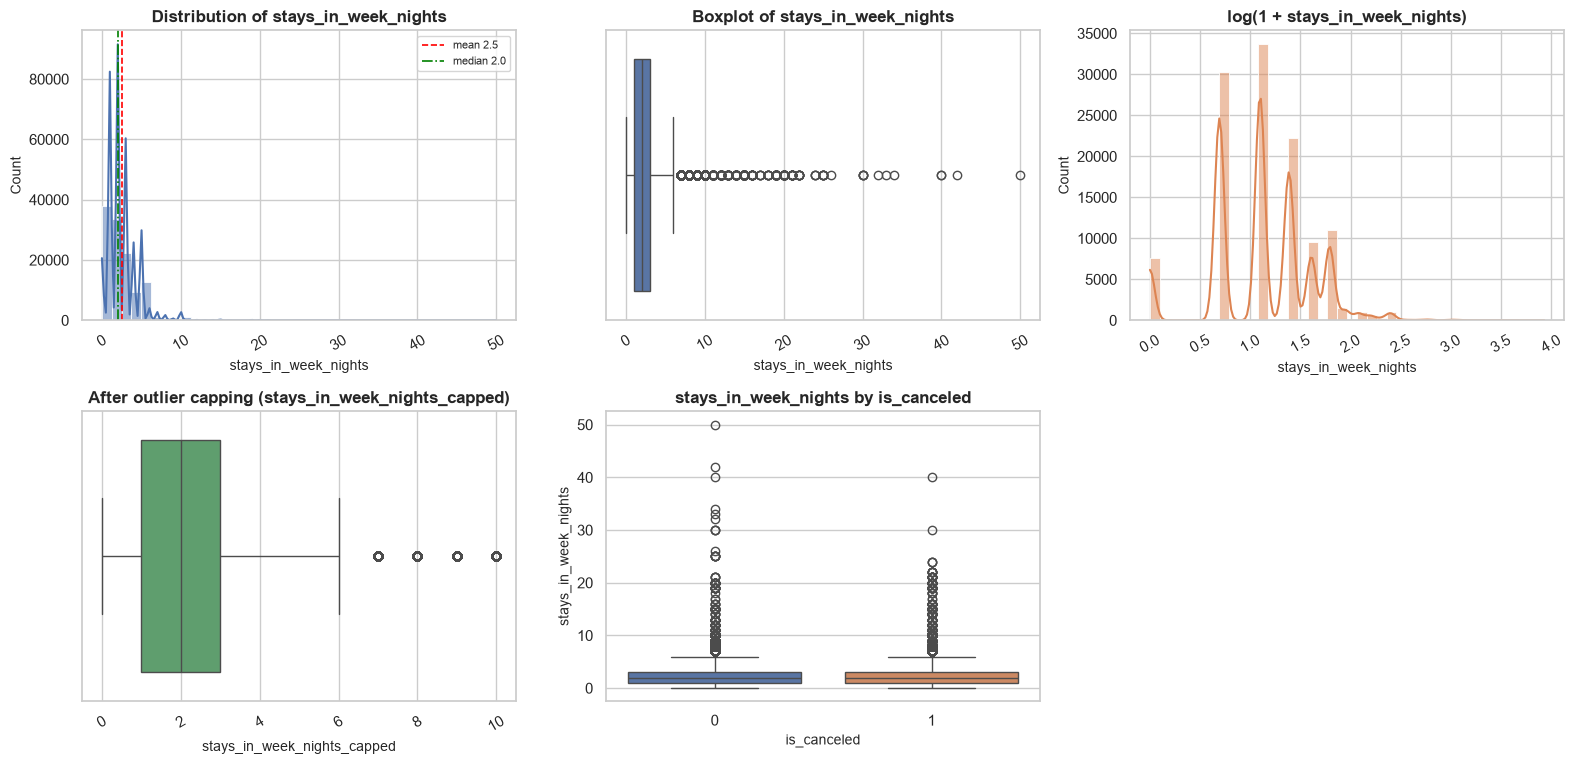

INSIGHTS
  - Distribution is highly skewed to the right (skew = 2.75); mean = 2.50, median = 2.00.
  - 3,330 IQR outliers (2.79%) outside [-2.00, 6.00].
  - 6.4% of the values are exactly 0.
  - Median of stays_in_week_nights by is_canceled: 0 = 2.00, 1 = 2.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [71]:
num_profile(hotel, 'stays_in_week_nights', target='is_canceled', raw=hotel_raw, capped="stays_in_week_nights_capped")

### 3.4.10 `adults`
**Description:** Number of adults.

**Cleaning:** Bookings with zero guests removed; capped in `adults_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
adults,119209,0,14,1.859,2.000,0.575,0,55,18.774,"1,392.496"


Value counts:


adults,0,1,2,3,4,5,6,10,20,26,27,40
count,223,23027,89679,6202,62,2,1,1,2,5,2,1


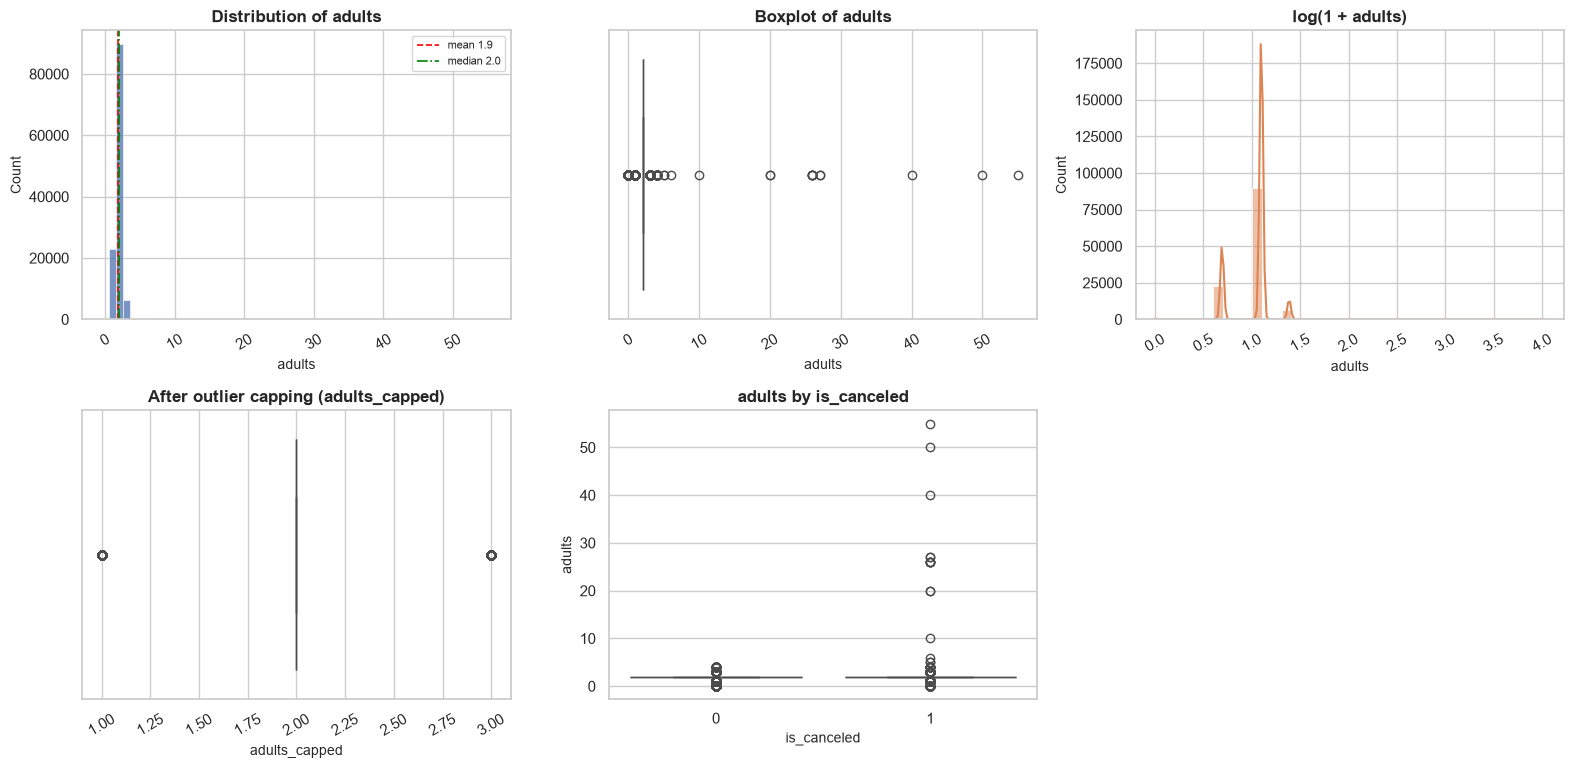

INSIGHTS
  - Distribution is highly skewed to the right (skew = 18.77); mean = 1.86, median = 2.00.
  - 29,530 IQR outliers (24.77%) outside [2.00, 2.00].
  - Median of adults by is_canceled: 0 = 2.00, 1 = 2.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [72]:
num_profile(hotel, 'adults', target='is_canceled', raw=hotel_raw, capped="adults_capped")

### 3.4.11 `children`
**Description:** Number of children.

**Cleaning:** 4 missing values filled with 0; cast to integer.

,count,percent
children,,
0,110619,92.794
1,4861,4.078
2,3652,3.064
3,76,0.064
10,1,0.001


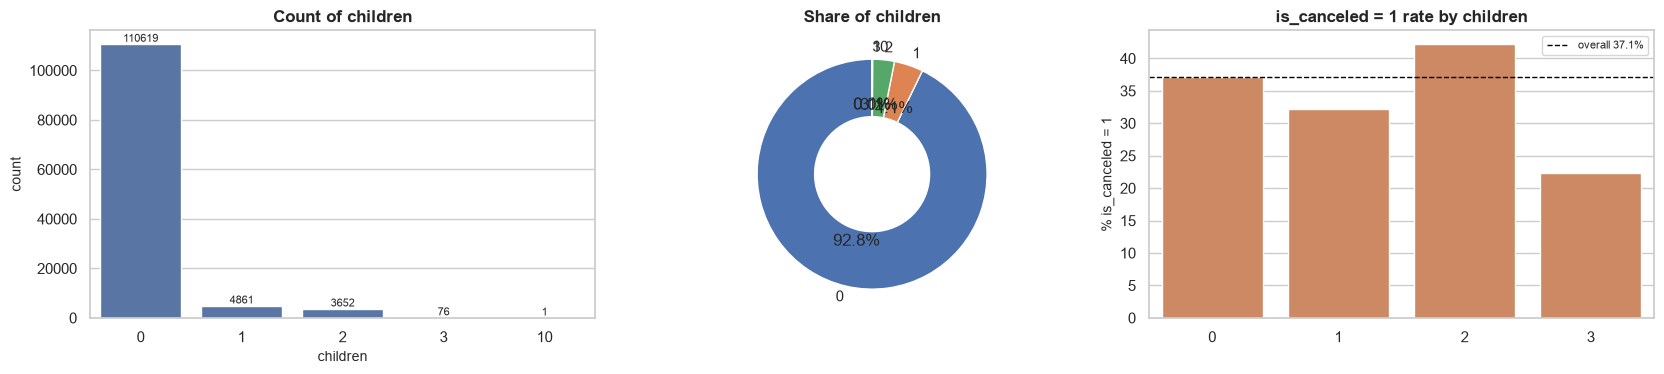

INSIGHTS
  - 5 unique categories; most frequent is "0" (92.8%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "2" (42.2%); lowest: "3" (22.4%).
  - Missing values: raw = 4 -> cleaned = 0.


In [73]:
cat_profile(hotel, 'children', target='is_canceled', positive=1, raw=hotel_raw, order=sorted(hotel["children"].unique()))

### 3.4.12 `babies`
**Description:** Number of babies.

**Cleaning:** No missing values.

,count,percent
babies,,
0,118292,99.231
1,900,0.755
2,15,0.013
10,1,0.001
9,1,0.001


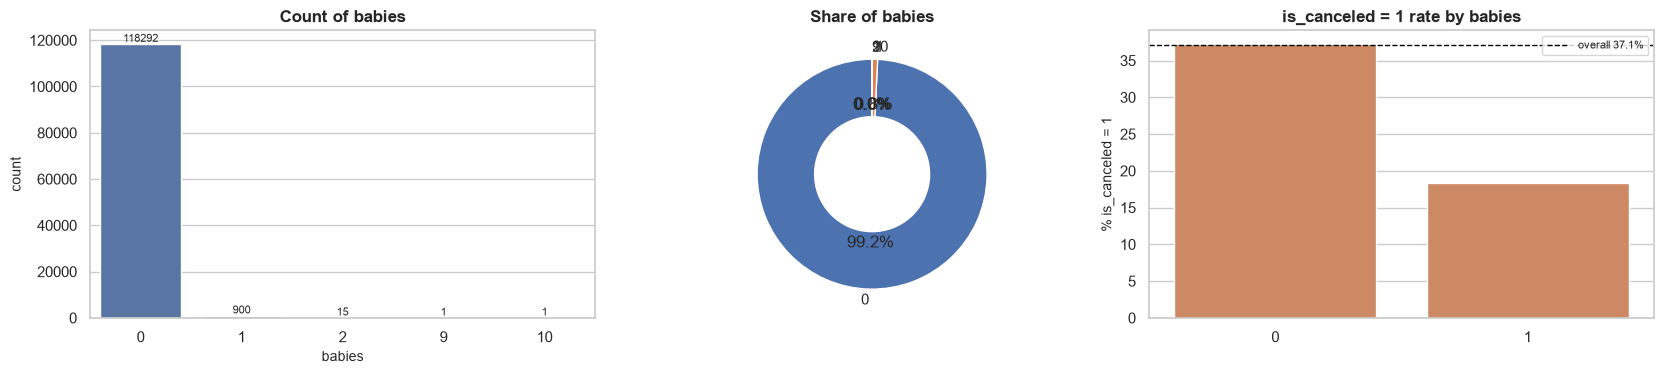

INSIGHTS
  - 5 unique categories; most frequent is "0" (99.2%).
  - 4 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "0" (37.2%); lowest: "1" (18.3%).
  - Missing values: raw = 0 -> cleaned = 0.


In [74]:
cat_profile(hotel, 'babies', target='is_canceled', positive=1, raw=hotel_raw, order=sorted(hotel["babies"].unique()))

### 3.4.13 `meal`
**Description:** Meal package booked.

**Cleaning:** `Undefined` merged into `SC` (both mean no meal package).

,count,percent
meal,,
BB,92235,77.373
HB,14458,12.128
SC,11718,9.830
FB,798,0.669


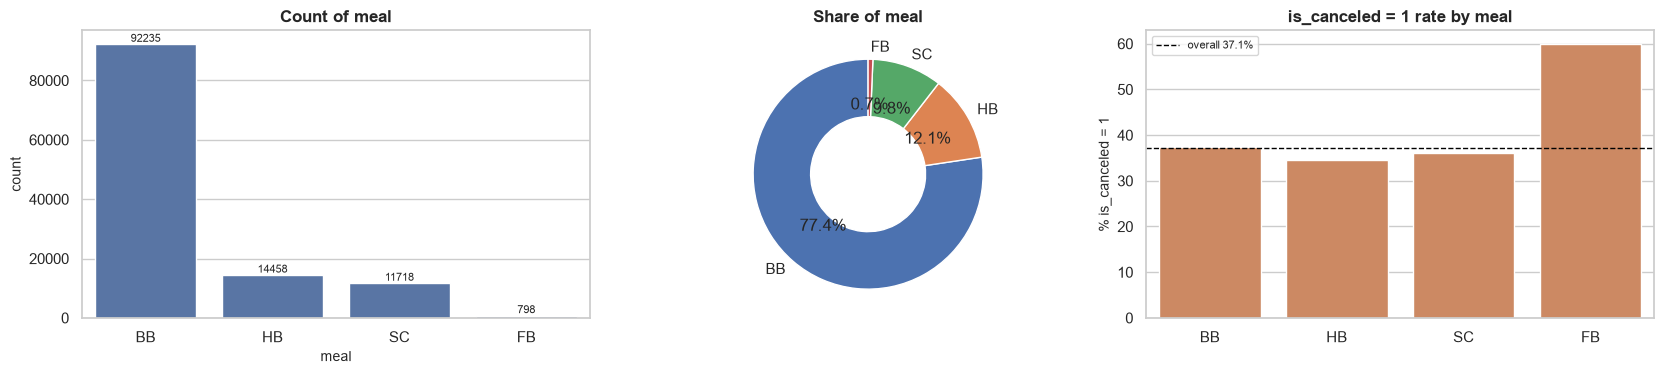

INSIGHTS
  - 4 unique categories; most frequent is "BB" (77.4%).
  - 1 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "FB" (59.9%); lowest: "HB" (34.5%).
  - Missing values: raw = 0 -> cleaned = 0.


In [75]:
cat_profile(hotel, 'meal', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.14 `country`
**Description:** Country of origin of the guest (ISO 3166 code; top 15 shown).

**Cleaning:** Missing values labelled `Unknown`.

,count,percent
country,,
PRT,48483,40.671
GBR,12119,10.166
FRA,10401,8.725
ESP,8560,7.181
DEU,7285,6.111
ITA,3761,3.155
IRL,3374,2.830
BEL,2342,1.965
BRA,2222,1.864


... 163 more categories not shown (total unique = 178).


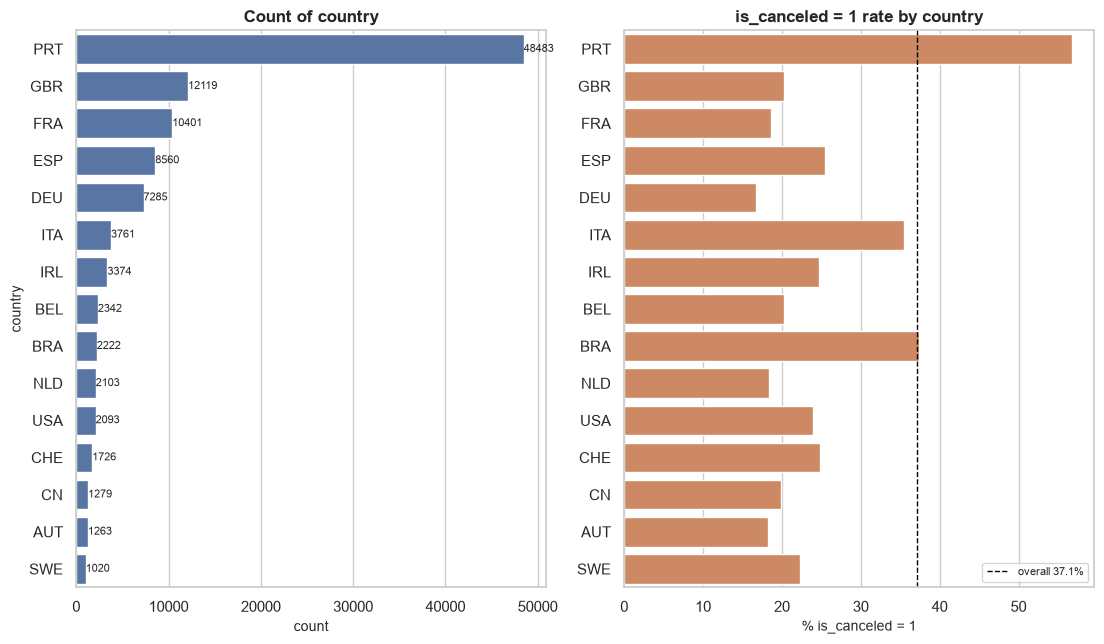

INSIGHTS
  - 178 unique categories; most frequent is "PRT" (40.7%).
  - 164 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "PRT" (56.7%); lowest: "DEU" (16.7%).
  - Missing values: raw = 488 -> cleaned = 0.


In [76]:
cat_profile(hotel, 'country', target='is_canceled', positive=1, raw=hotel_raw, top=15)

### 3.4.15 `market_segment`
**Description:** Market segment of the booking.

**Cleaning:** `Undefined` rows replaced by the mode.

,count,percent
market_segment,,
Online TA,56410,47.320
Offline TA/TO,24182,20.285
Groups,19790,16.601
Direct,12582,10.555
Corporate,5282,4.431
Complementary,728,0.611
Aviation,235,0.197


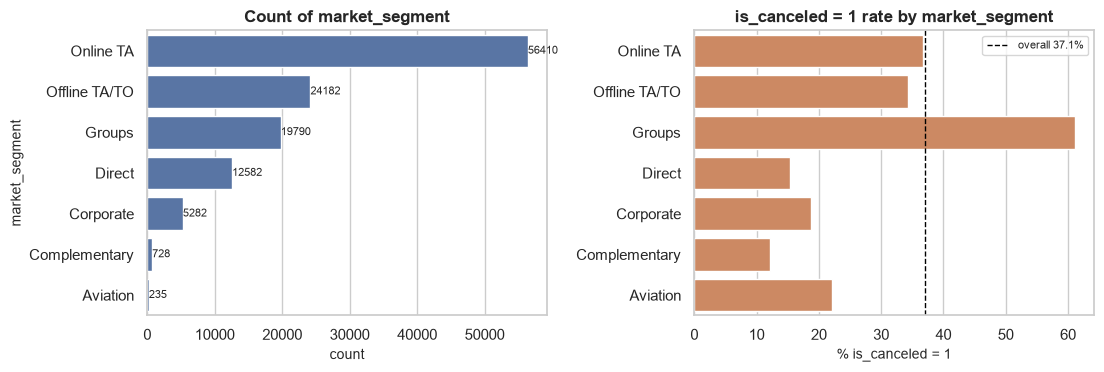

INSIGHTS
  - 7 unique categories; most frequent is "Online TA" (47.3%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "Groups" (61.1%); lowest: "Complementary" (12.2%).
  - Missing values: raw = 0 -> cleaned = 0.


In [77]:
cat_profile(hotel, 'market_segment', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.16 `distribution_channel`
**Description:** Booking distribution channel.

**Cleaning:** `Undefined` rows replaced by the mode.

,count,percent
distribution_channel,,
TA/TO,97755,82.003
Direct,14610,12.256
Corporate,6651,5.579
GDS,193,0.162


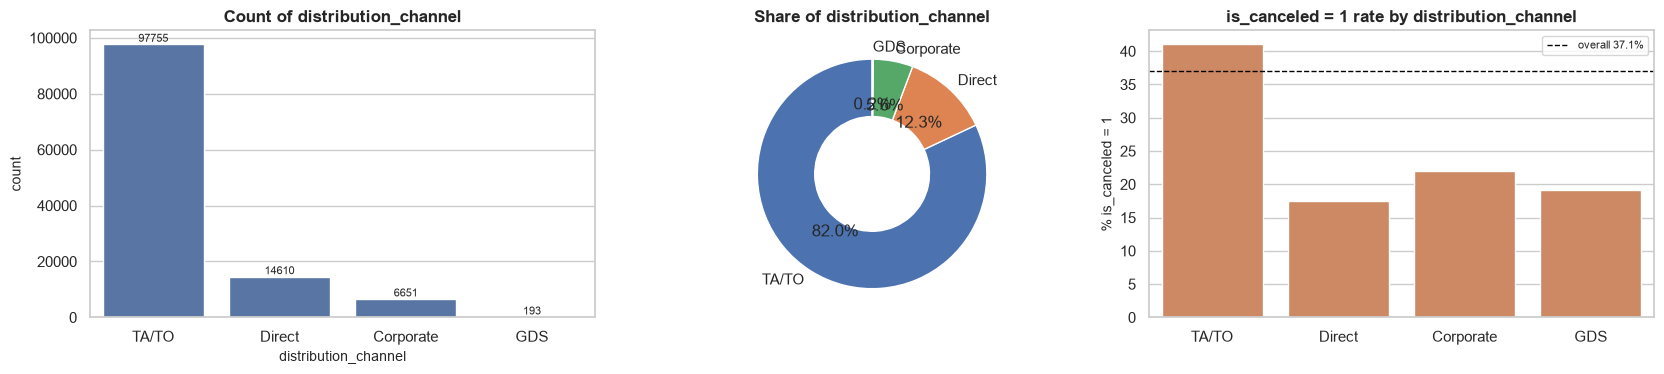

INSIGHTS
  - 4 unique categories; most frequent is "TA/TO" (82.0%).
  - 1 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "TA/TO" (41.1%); lowest: "Direct" (17.5%).
  - Missing values: raw = 0 -> cleaned = 0.


In [78]:
cat_profile(hotel, 'distribution_channel', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.17 `is_repeated_guest`
**Description:** 1 = returning guest.

**Cleaning:** No missing values.

,count,percent
is_repeated_guest,,
0,115455,96.851
1,3754,3.149


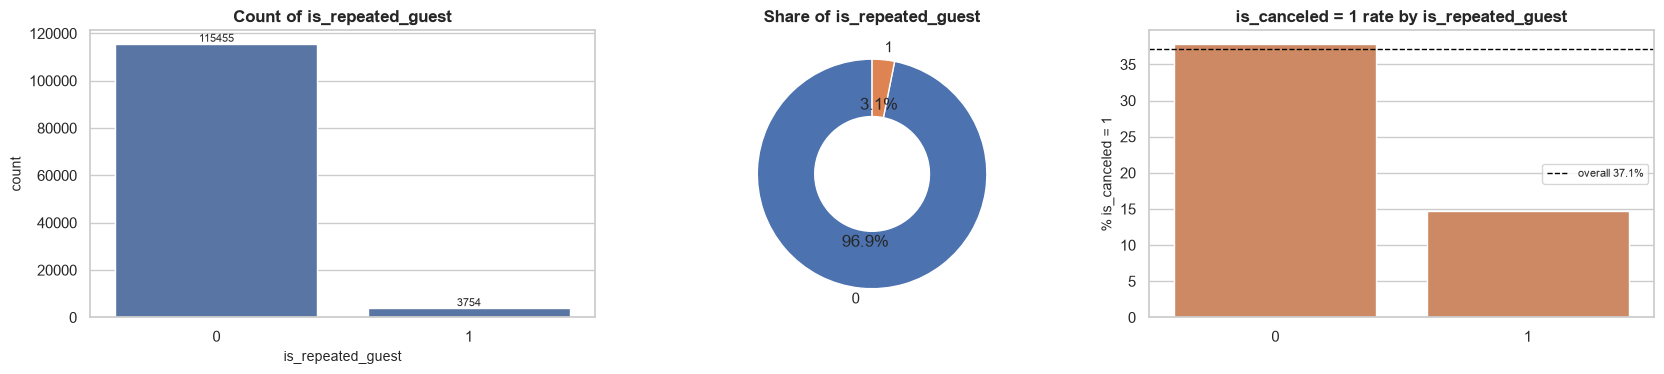

INSIGHTS
  - 2 unique categories; most frequent is "0" (96.9%).
  - Highest is_canceled=1 rate: "0" (37.8%); lowest: "1" (14.7%).
  - Missing values: raw = 0 -> cleaned = 0.


In [79]:
cat_profile(hotel, 'is_repeated_guest', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.18 `previous_cancellations`
**Description:** Number of earlier bookings of this guest that were cancelled.

**Cleaning:** No missing values.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
previous_cancellations,119209,0,15,0.087,0.000,0.845,0,26,24.444,673.216


Value counts:


previous_cancellations,0,1,2,3,4,5,6,11,13,14,19,21
count,112730,6048,114,65,31,19,22,35,12,14,19,1


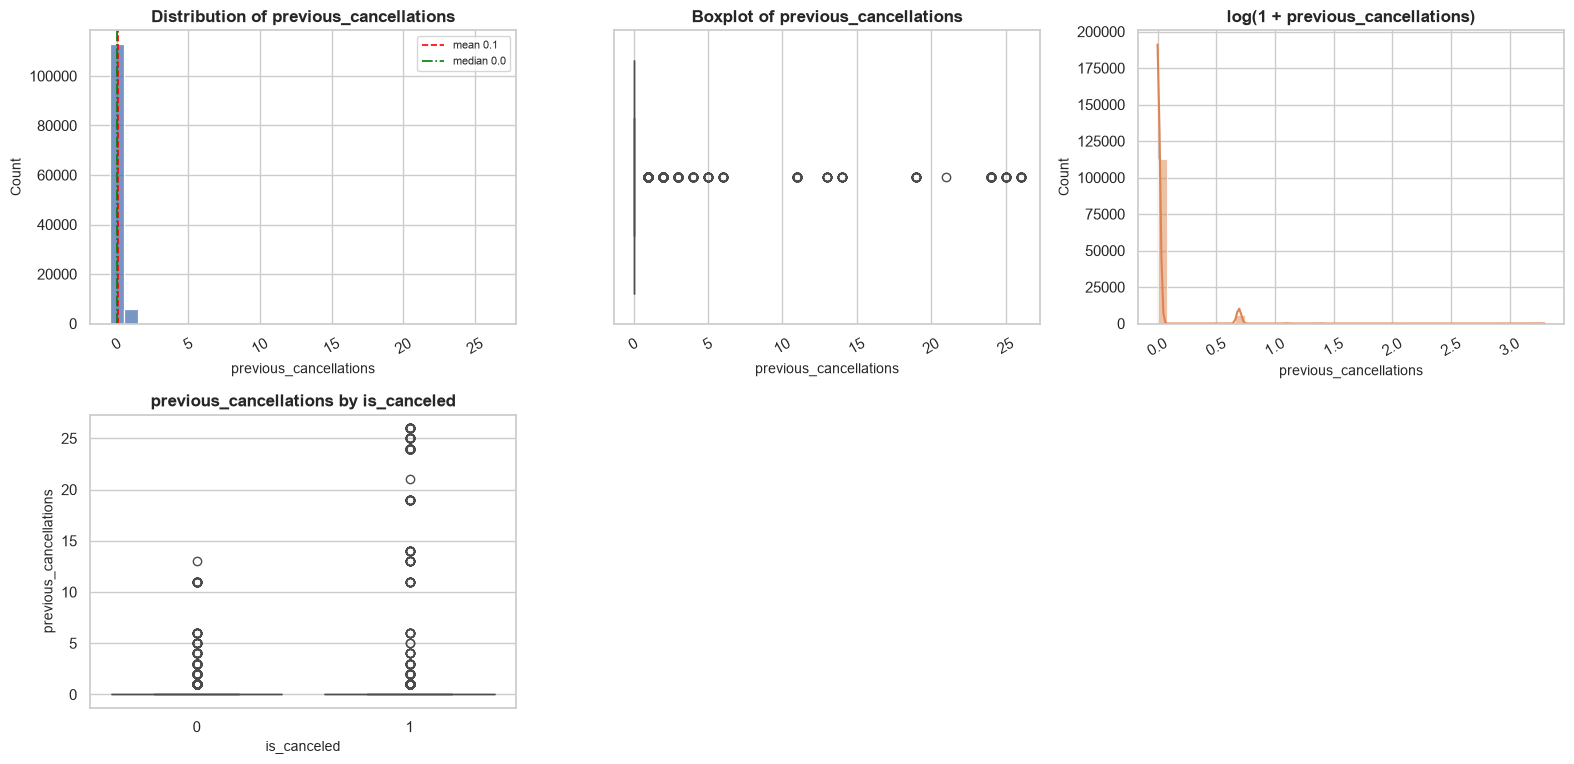

INSIGHTS
  - Distribution is highly skewed to the right (skew = 24.44); mean = 0.09, median = 0.00.
  - 6,479 IQR outliers (5.43%) outside [0.00, 0.00].
  - 94.6% of the values are exactly 0.
  - Median of previous_cancellations by is_canceled: 0 = 0.00, 1 = 0.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [80]:
num_profile(hotel, 'previous_cancellations', target='is_canceled', raw=hotel_raw)

### 3.4.19 `previous_bookings_not_canceled`
**Description:** Number of earlier bookings of this guest that were not cancelled.

**Cleaning:** No missing values.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
previous_bookings_not_canceled,119209,0,73,0.137,0.000,1.498,0,72,23.540,766.967


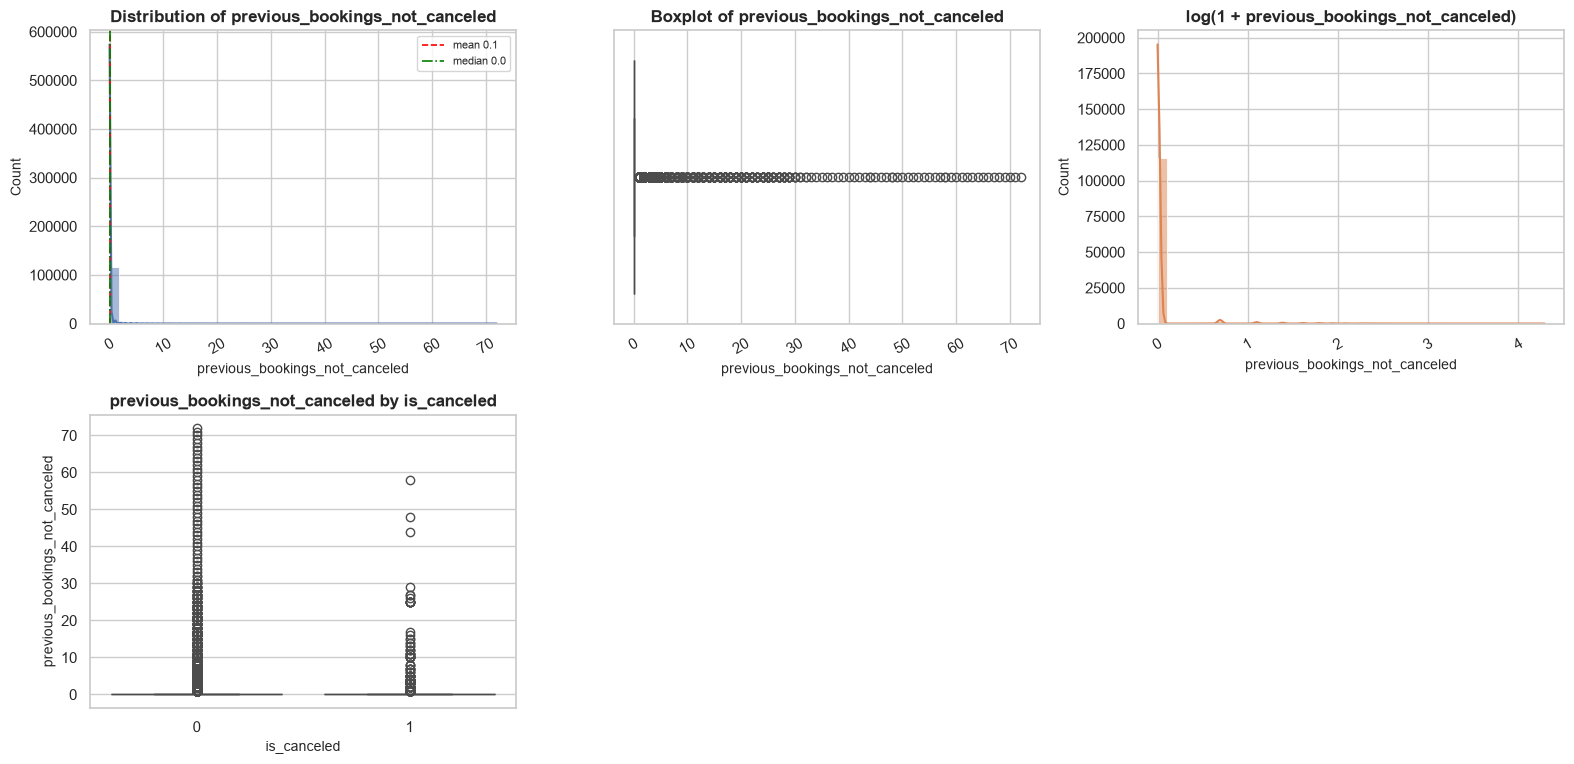

INSIGHTS
  - Distribution is highly skewed to the right (skew = 23.54); mean = 0.14, median = 0.00.
  - 3,612 IQR outliers (3.03%) outside [0.00, 0.00].
  - 97.0% of the values are exactly 0.
  - Median of previous_bookings_not_canceled by is_canceled: 0 = 0.00, 1 = 0.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [81]:
num_profile(hotel, 'previous_bookings_not_canceled', target='is_canceled', raw=hotel_raw)

### 3.4.20 `reserved_room_type`
**Description:** Room type reserved by the guest (coded letter).

**Cleaning:** No missing values.

,count,percent
reserved_room_type,,
A,85872,72.035
D,19179,16.089
E,6519,5.469
F,2894,2.428
G,2092,1.755
B,1115,0.935
C,931,0.781
H,601,0.504
L,6,0.005


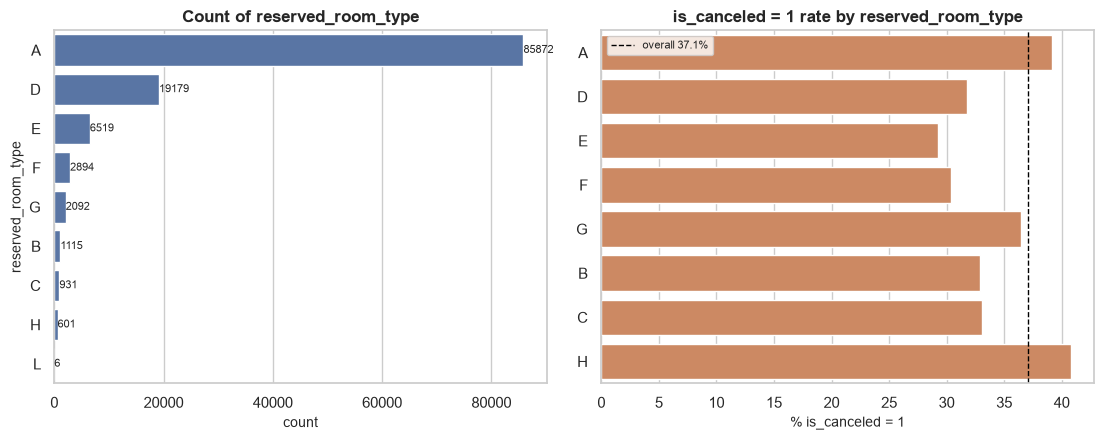

INSIGHTS
  - 9 unique categories; most frequent is "A" (72.0%).
  - 4 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "H" (40.8%); lowest: "E" (29.3%).
  - Missing values: raw = 0 -> cleaned = 0.


In [82]:
cat_profile(hotel, 'reserved_room_type', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.21 `assigned_room_type`
**Description:** Room type actually assigned (coded letter).

**Cleaning:** No missing; `room_changed` flag created.

,count,percent
assigned_room_type,,
A,74020,62.093
D,25309,21.231
E,7798,6.541
F,3751,3.147
G,2549,2.138
C,2370,1.988
B,2154,1.807
H,711,0.596
I,359,0.301


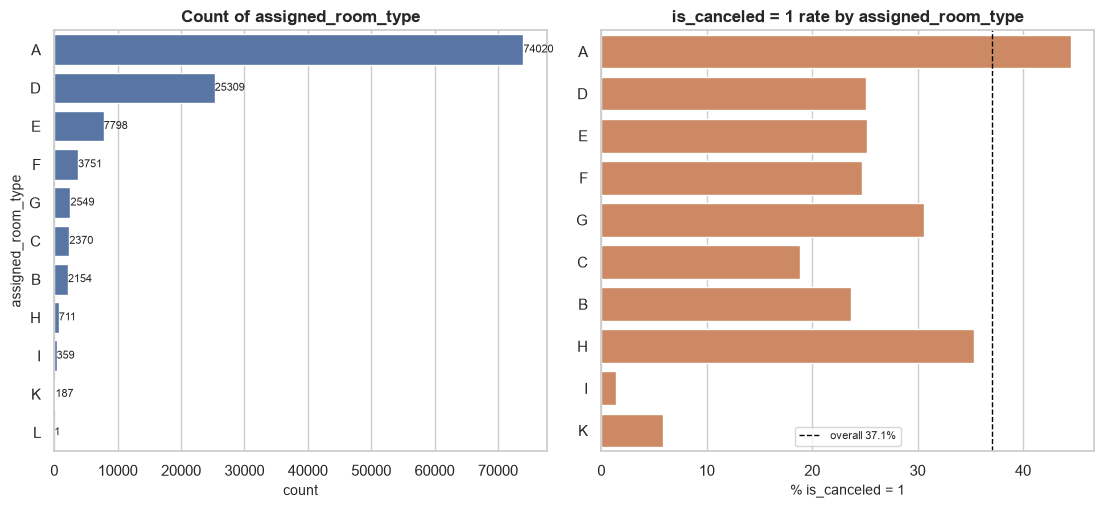

INSIGHTS
  - 11 unique categories; most frequent is "A" (62.1%).
  - 4 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "A" (44.5%); lowest: "I" (1.4%).
  - Missing values: raw = 0 -> cleaned = 0.


In [83]:
cat_profile(hotel, 'assigned_room_type', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.22 `booking_changes`
**Description:** Number of changes made to the booking.

**Cleaning:** No missing; capped in `booking_changes_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
booking_changes,119209,0,19,0.219,0.000,0.638,0,18,5.500,63.446


Value counts:


booking_changes,0,1,2,3,4,5,6,7,8,9,10,11
count,101232,12666,3779,914,367,115,61,29,14,8,6,1


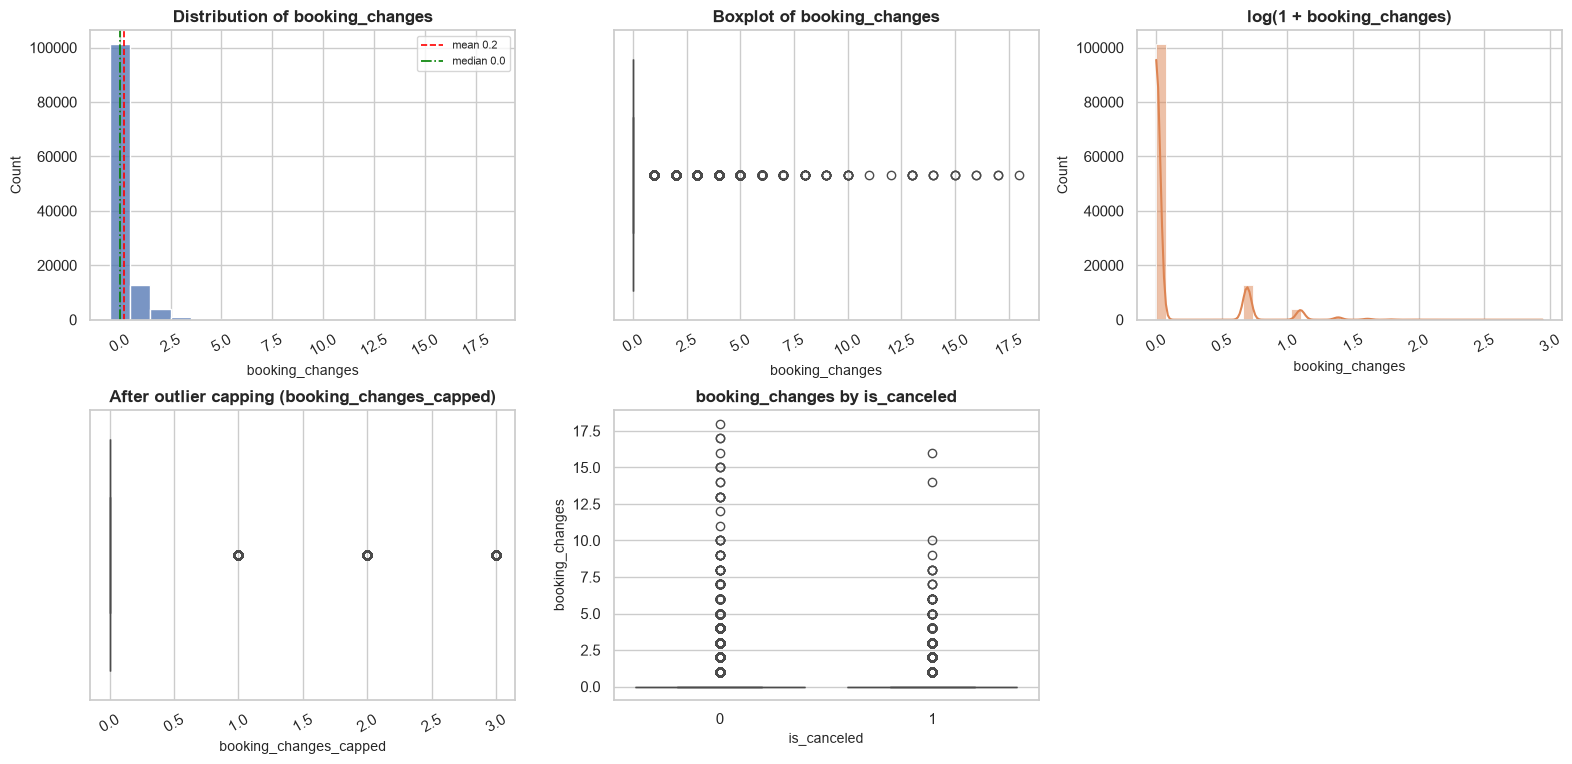

INSIGHTS
  - Distribution is highly skewed to the right (skew = 5.50); mean = 0.22, median = 0.00.
  - 17,977 IQR outliers (15.08%) outside [0.00, 0.00].
  - 84.9% of the values are exactly 0.
  - Median of booking_changes by is_canceled: 0 = 0.00, 1 = 0.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [84]:
num_profile(hotel, 'booking_changes', target='is_canceled', raw=hotel_raw, capped="booking_changes_capped")

### 3.4.23 `deposit_type`
**Description:** Deposit type paid for the booking.

**Cleaning:** No missing values.

,count,percent
deposit_type,,
No Deposit,104460,87.628
Non Refund,14587,12.236
Refundable,162,0.136


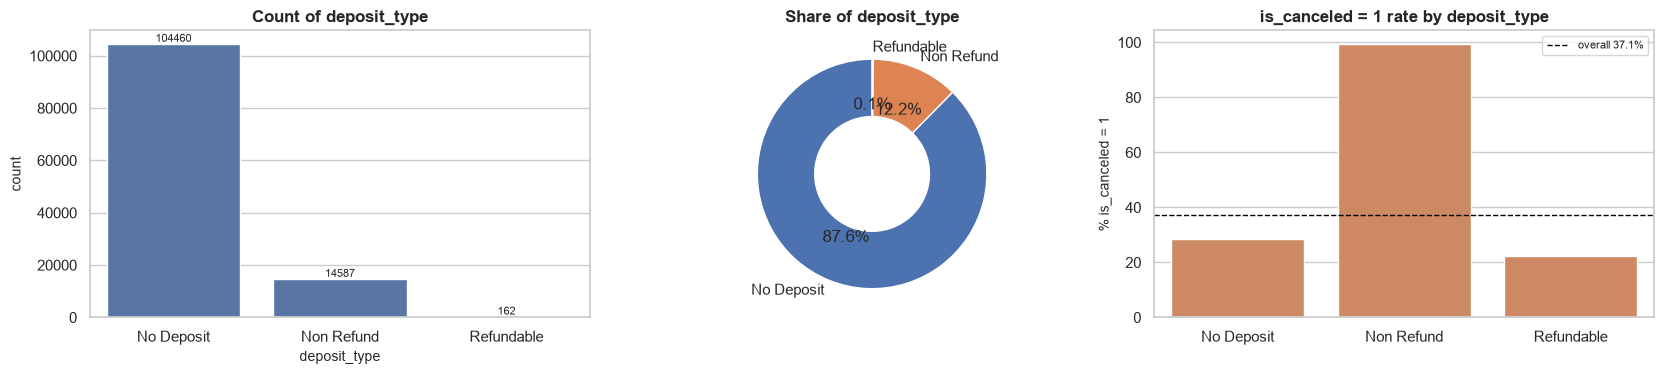

INSIGHTS
  - 3 unique categories; most frequent is "No Deposit" (87.6%).
  - 1 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "Non Refund" (99.4%); lowest: "Refundable" (22.2%).
  - Missing values: raw = 0 -> cleaned = 0.


In [85]:
cat_profile(hotel, 'deposit_type', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.24 `agent`
**Description:** ID of the travel agent (0 = no agent; top 15 shown).

**Cleaning:** Missing values (booked without an agent) filled with 0; `has_agent` flag created.

,count,percent
agent,,
9,31922,26.778
0,16280,13.657
240,13922,11.679
1,7187,6.029
14,3633,3.048
7,3532,2.963
6,3290,2.760
250,2870,2.408
241,1721,1.444


... 319 more categories not shown (total unique = 334).


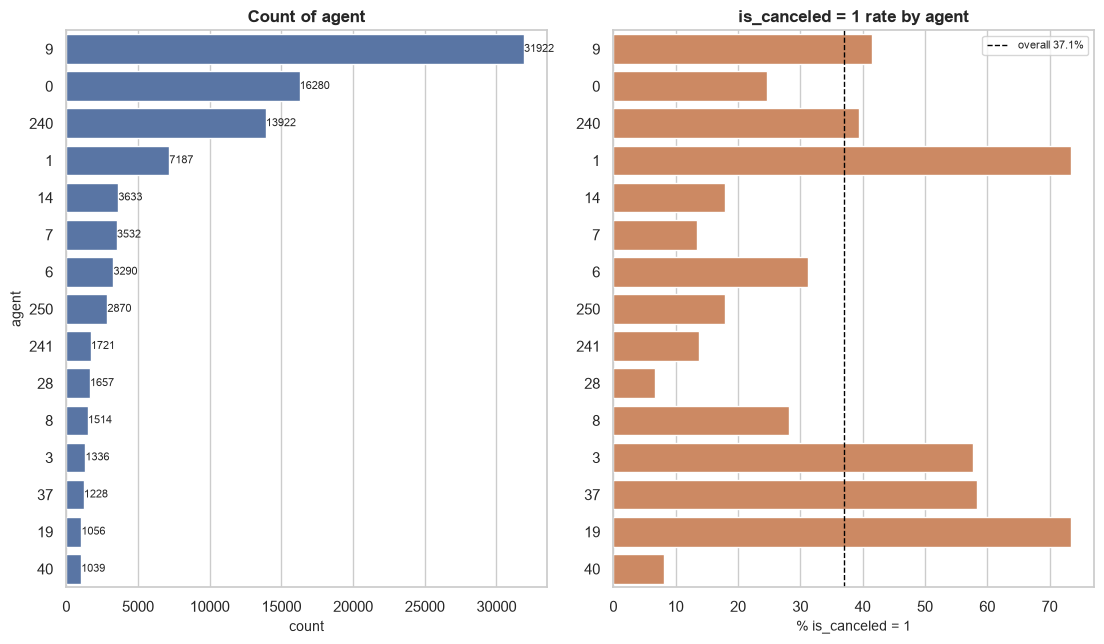

INSIGHTS
  - 334 unique categories; most frequent is "9" (26.8%).
  - 321 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "1" (73.5%); lowest: "28" (6.6%).
  - Missing values: raw = 16,340 -> cleaned = 0.


In [86]:
cat_profile(hotel, 'agent', target='is_canceled', positive=1, raw=hotel_raw, top=15)

,count,percent
has_agent,,
1,102929,86.343
0,16280,13.657


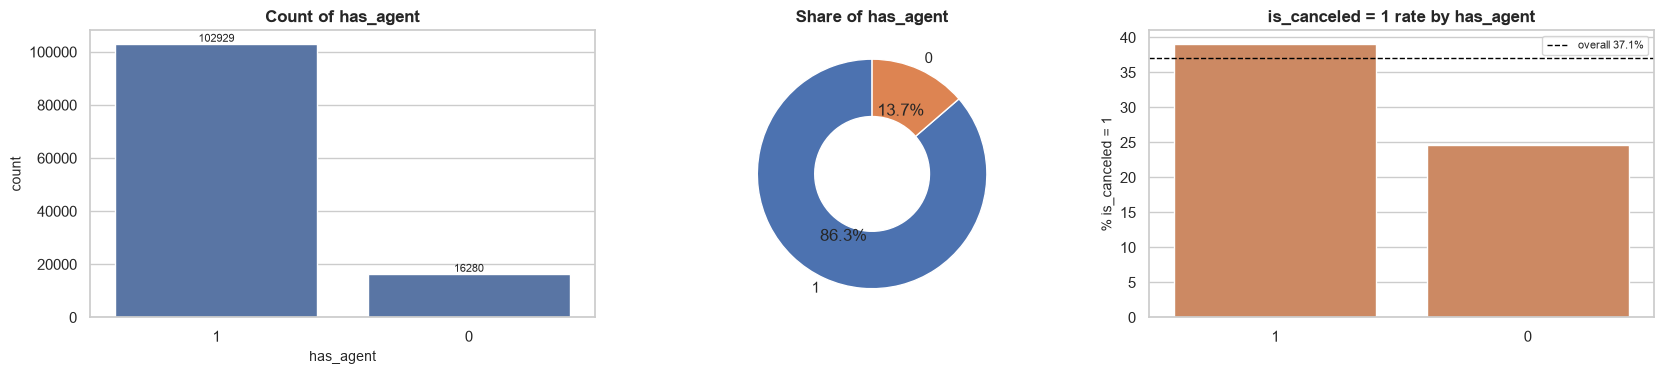

INSIGHTS
  - 2 unique categories; most frequent is "1" (86.3%).
  - Highest is_canceled=1 rate: "1" (39.0%); lowest: "0" (24.7%).


In [87]:
cat_profile(hotel, 'has_agent', target='is_canceled', positive=1)

### 3.4.25 `company`
**Description:** ID of the company that made the booking (0 = none; top 10 shown).

**Cleaning:** ~94% missing, so filled with 0 and `has_company` flag created.

,count,percent
company,,
0,112441,94.323
40,924,0.775
223,784,0.658
67,267,0.224
45,249,0.209
153,213,0.179
174,147,0.123
219,141,0.118
281,138,0.116


... 339 more categories not shown (total unique = 349).


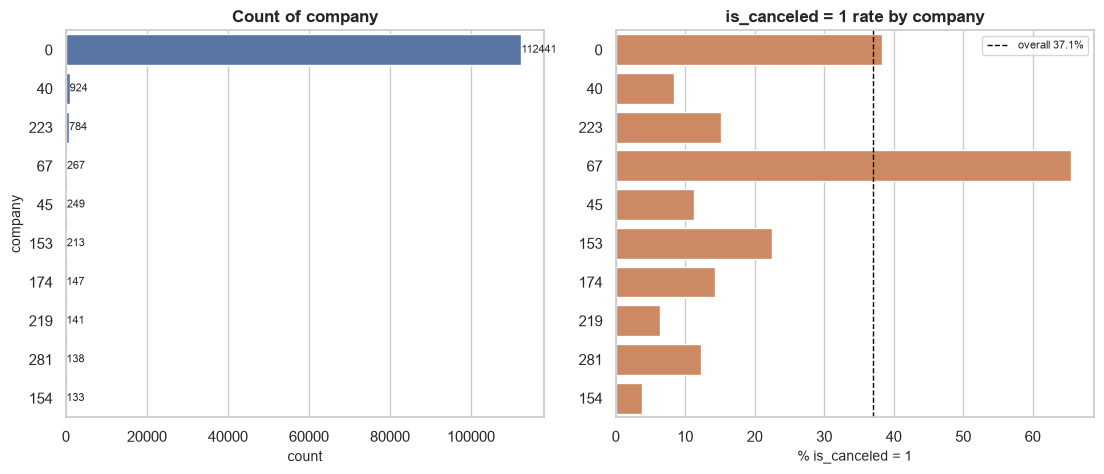

INSIGHTS
  - 349 unique categories; most frequent is "0" (94.3%).
  - 348 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "67" (65.5%); lowest: "154" (3.8%).
  - Missing values: raw = 112,593 -> cleaned = 0.


In [88]:
cat_profile(hotel, 'company', target='is_canceled', positive=1, raw=hotel_raw, top=10)

,count,percent
has_company,,
0,112441,94.323
1,6768,5.677


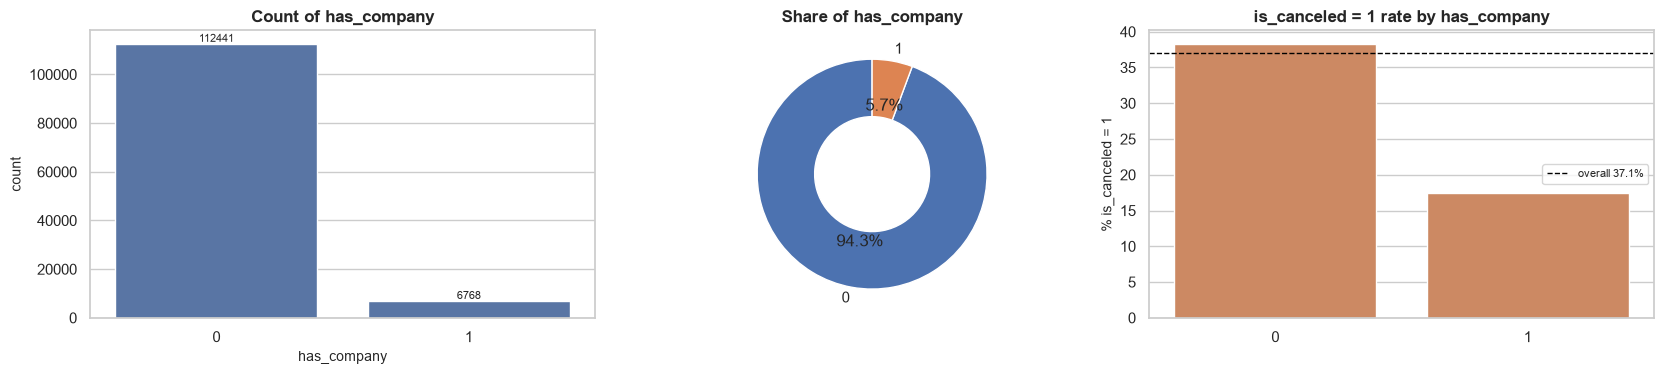

INSIGHTS
  - 2 unique categories; most frequent is "0" (94.3%).
  - Highest is_canceled=1 rate: "0" (38.3%); lowest: "1" (17.4%).


In [89]:
cat_profile(hotel, 'has_company', target='is_canceled', positive=1)

### 3.4.26 `days_in_waiting_list`
**Description:** Days the booking waited before confirmation.

**Cleaning:** No missing; capped in `days_in_waiting_list_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
days_in_waiting_list,119209,0,127,2.321,0.000,17.598,0,391,11.949,186.893


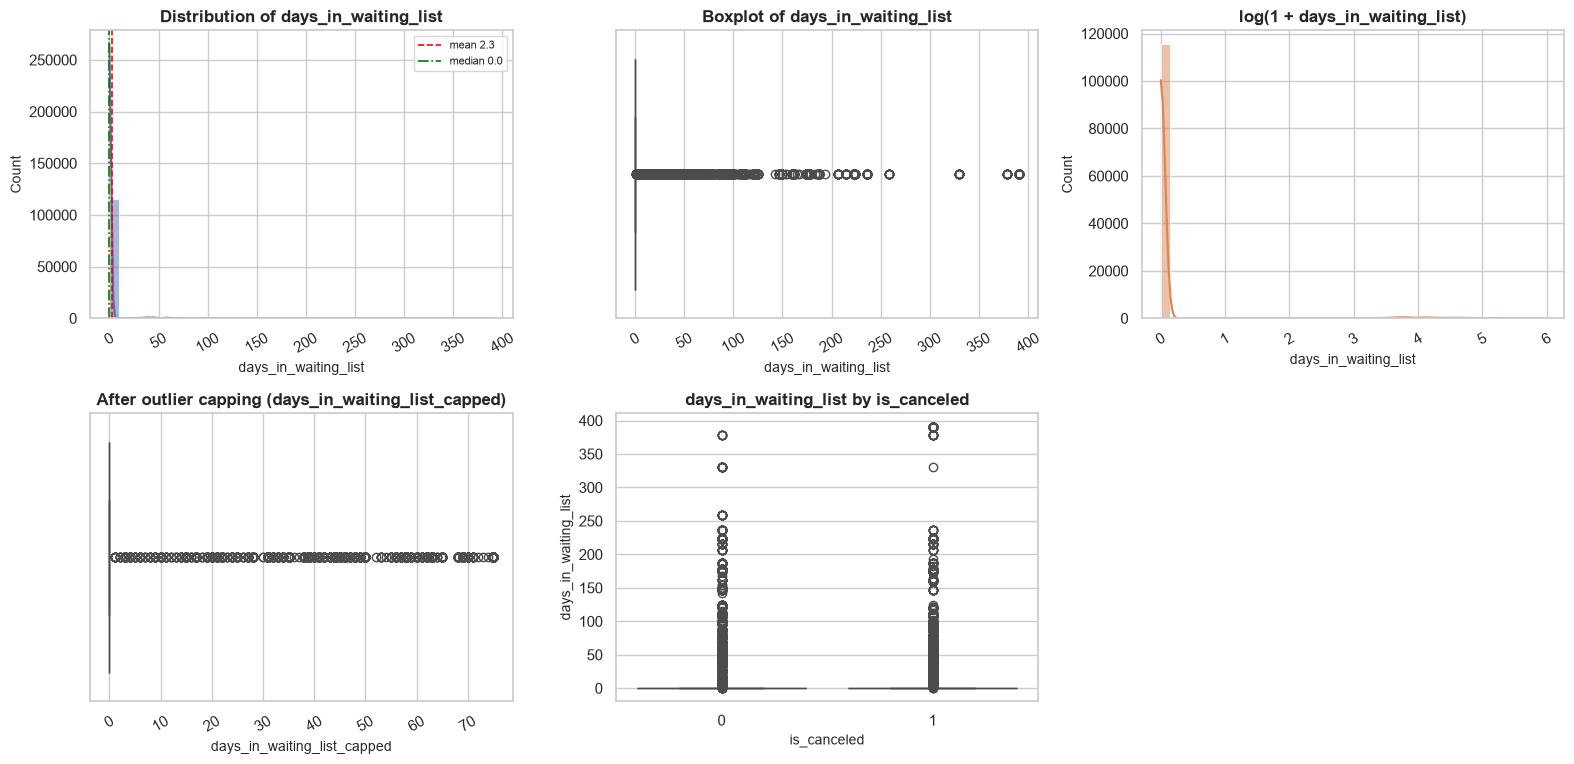

INSIGHTS
  - Distribution is highly skewed to the right (skew = 11.95); mean = 2.32, median = 0.00.
  - 3,693 IQR outliers (3.10%) outside [0.00, 0.00].
  - 96.9% of the values are exactly 0.
  - Median of days_in_waiting_list by is_canceled: 0 = 0.00, 1 = 0.00.
  - Missing values: raw = 0 -> cleaned = 0.


In [90]:
num_profile(hotel, 'days_in_waiting_list', target='is_canceled', raw=hotel_raw, capped="days_in_waiting_list_capped")

### 3.4.27 `customer_type`
**Description:** Type of customer.

**Cleaning:** No missing values.

,count,percent
customer_type,,
Transient,89476,75.058
Transient-Party,25087,21.045
Contract,4072,3.416
Group,574,0.482


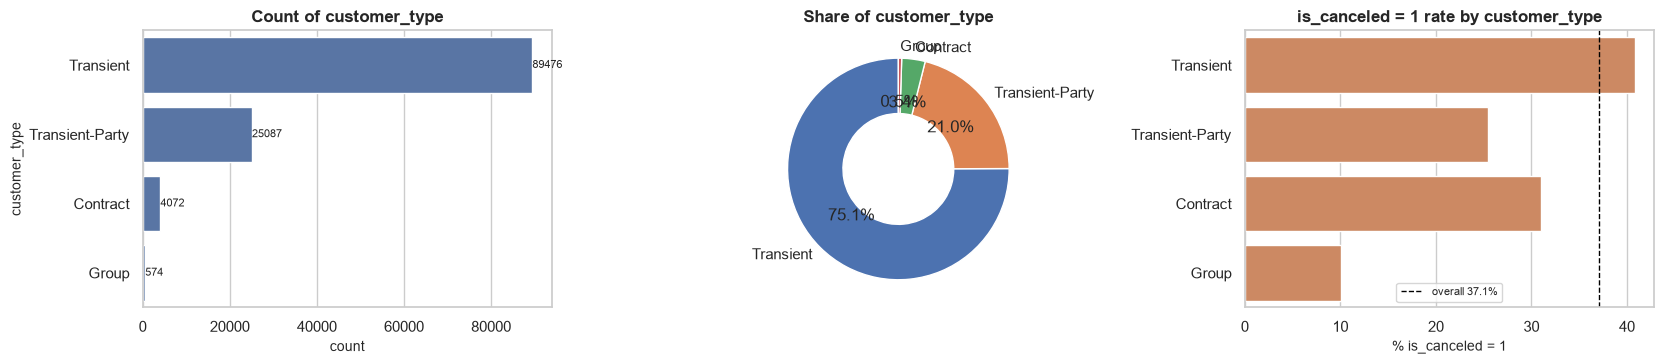

INSIGHTS
  - 4 unique categories; most frequent is "Transient" (75.1%).
  - 1 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "Transient" (40.8%); lowest: "Group" (10.1%).
  - Missing values: raw = 0 -> cleaned = 0.


In [91]:
cat_profile(hotel, 'customer_type', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.28 `adr`
**Description:** Average daily rate = revenue per night.

**Cleaning:** Negative price row dropped; extreme value (5400) capped in `adr_capped`.

,count,missing,unique,mean,median,std,min,max,skew,kurtosis
adr,119209,0,8865,101.970,94.950,50.433,0.000,"5,400.000",10.613,"1,022.897"


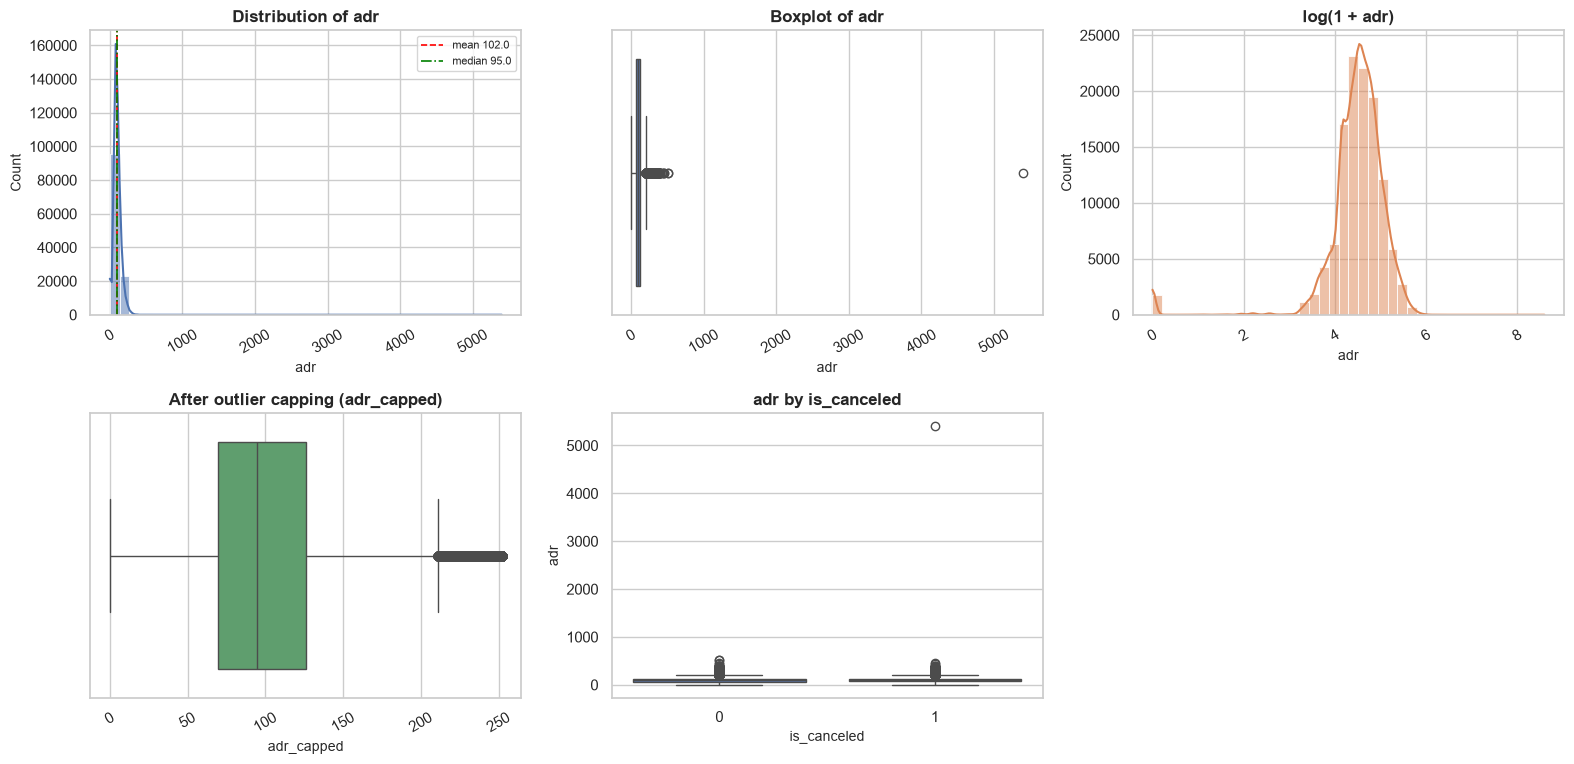

INSIGHTS
  - Distribution is highly skewed to the right (skew = 10.61); mean = 101.97, median = 94.95.
  - 3,864 IQR outliers (3.24%) outside [-15.25, 210.75].
  - Median of adr by is_canceled: 0 = 92.70, 1 = 96.30.
  - Missing values: raw = 0 -> cleaned = 0.


In [92]:
num_profile(hotel, 'adr', target='is_canceled', raw=hotel_raw, capped="adr_capped")

### 3.4.29 `required_car_parking_spaces`
**Description:** Parking spaces requested.

**Cleaning:** No missing values.

,count,percent
required_car_parking_spaces,,
0,111800,93.785
1,7376,6.187
2,28,0.023
3,3,0.003
8,2,0.002


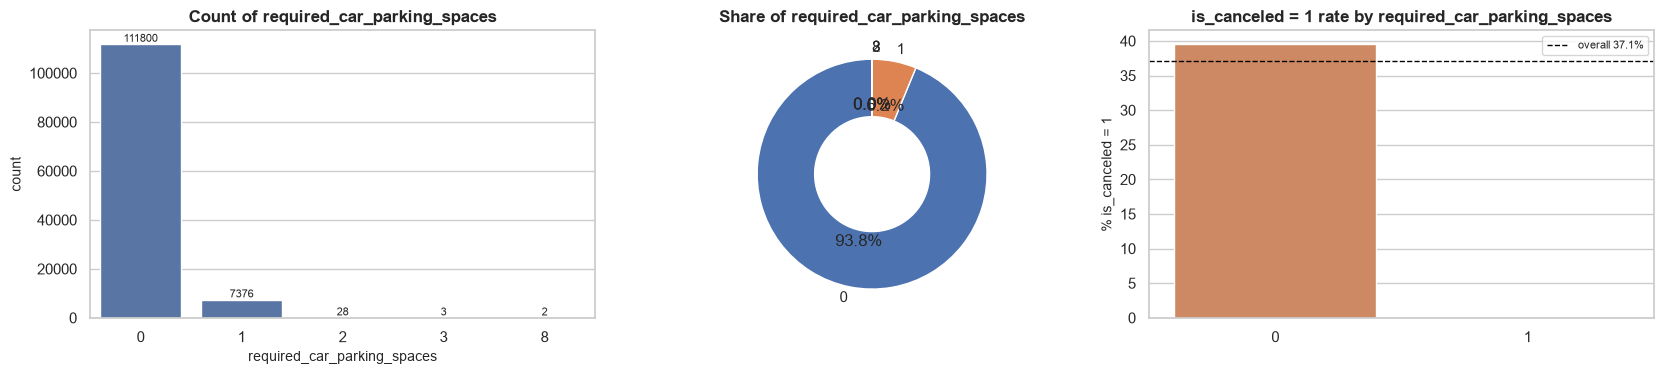

INSIGHTS
  - 5 unique categories; most frequent is "0" (93.8%).
  - 3 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "0" (39.5%); lowest: "1" (0.0%).
  - Missing values: raw = 0 -> cleaned = 0.


In [93]:
cat_profile(hotel, 'required_car_parking_spaces', target='is_canceled', positive=1, raw=hotel_raw, order=sorted(hotel["required_car_parking_spaces"].unique()))

### 3.4.30 `total_of_special_requests`
**Description:** Number of special requests made.

**Cleaning:** No missing values.

,count,percent
total_of_special_requests,,
0,70200,58.888
1,33183,27.836
2,12952,10.865
3,2494,2.092
4,340,0.285
5,40,0.034


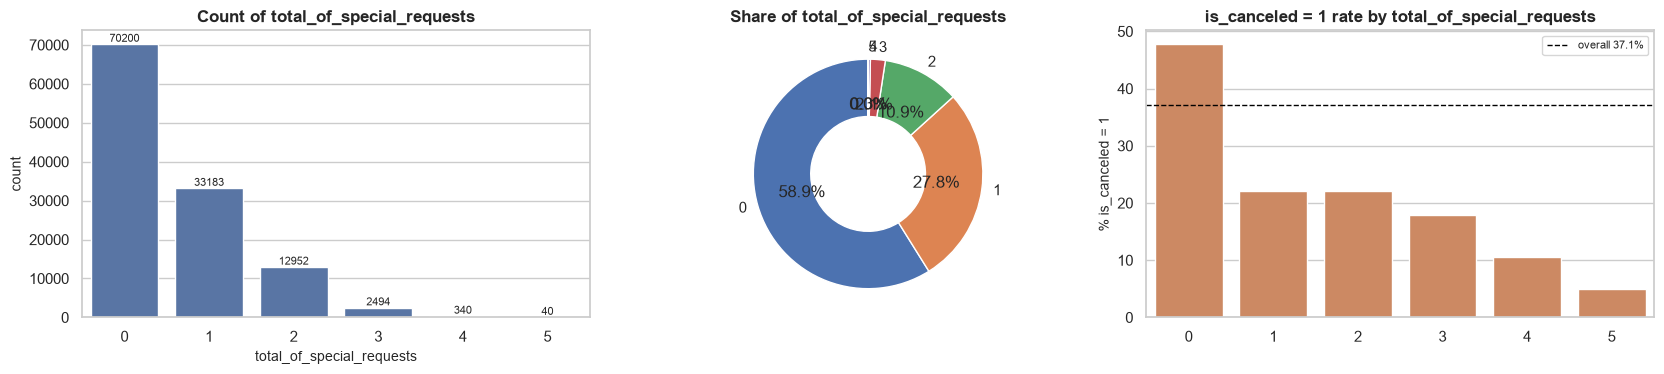

INSIGHTS
  - 6 unique categories; most frequent is "0" (58.9%).
  - 2 categories each hold less than 1% of the rows (rare categories).
  - Highest is_canceled=1 rate: "0" (47.8%); lowest: "5" (5.0%).
  - Missing values: raw = 0 -> cleaned = 0.


In [94]:
cat_profile(hotel, 'total_of_special_requests', target='is_canceled', positive=1, raw=hotel_raw, order=sorted(hotel["total_of_special_requests"].unique()))

### 3.4.31 `reservation_status`
**Description:** Final status of the reservation. **Leakage:** it reveals `is_canceled`, so it must not be used to predict cancellation.

**Cleaning:** No missing values.

,count,percent
reservation_status,,
Check-Out,75010,62.923
Canceled,42993,36.065
No-Show,1206,1.012


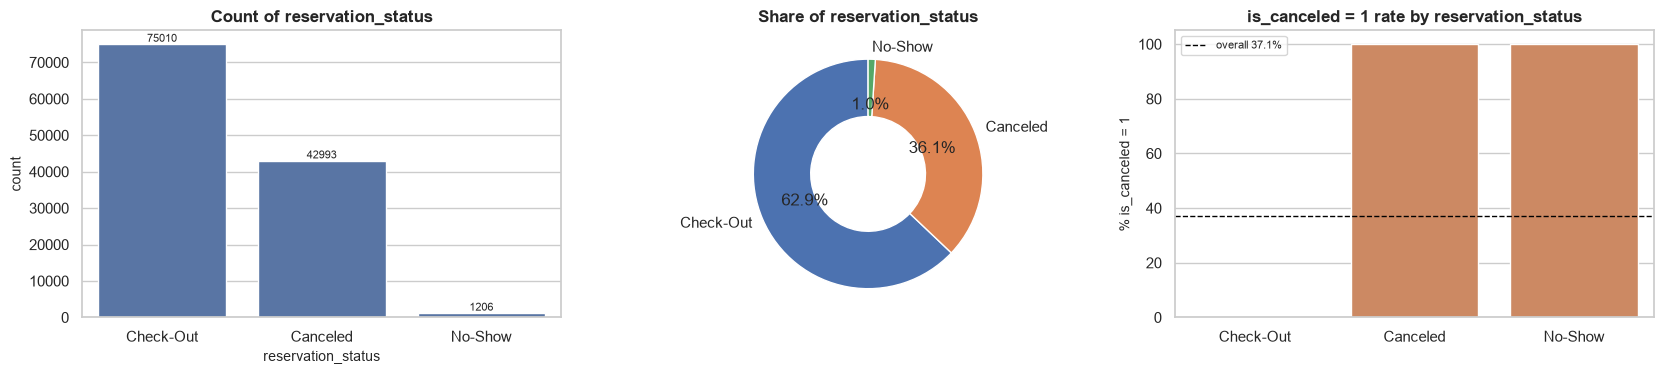

INSIGHTS
  - 3 unique categories; most frequent is "Check-Out" (62.9%).
  - Highest is_canceled=1 rate: "Canceled" (100.0%); lowest: "Check-Out" (0.0%).
  - Missing values: raw = 0 -> cleaned = 0.


In [95]:
cat_profile(hotel, 'reservation_status', target='is_canceled', positive=1, raw=hotel_raw)

### 3.4.32 `reservation_status_date`
**Description:** date on which the reservation reached its final status (check-out date, cancellation date or no-show date).

**Cleaning:** converted from text to `datetime64`.

Date range: 2014-10-17 -> 2017-09-14 | missing: 0


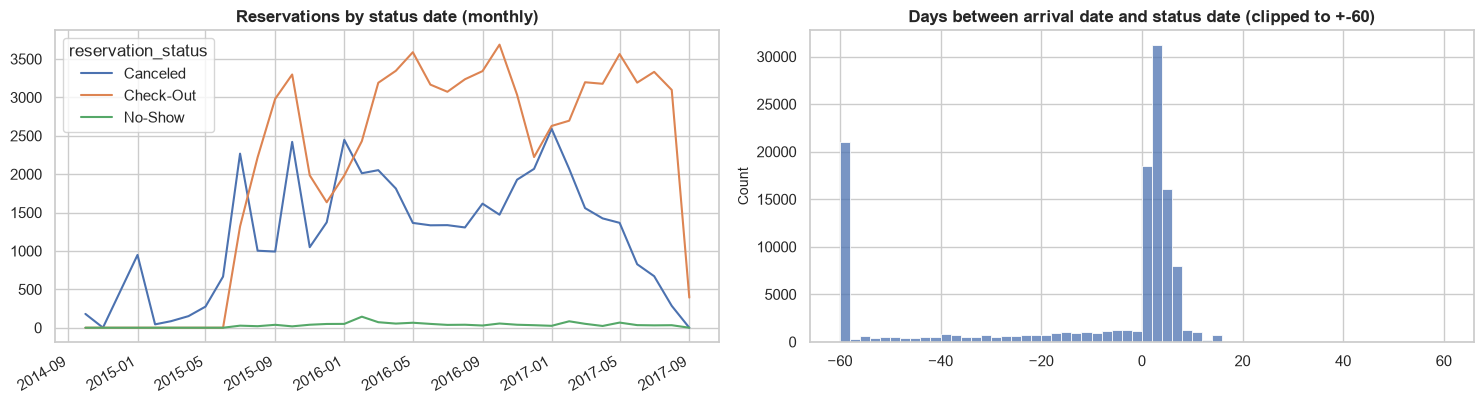

INSIGHTS
  - Status dates span 1063 days; most check-outs happen on/after arrival, while cancellations happen before it (negative lag).
  - Median lag: Check-Out = 3 days, Canceled = -56 days.


In [96]:
d = hotel['reservation_status_date']
print('Date range:', d.min().date(), '->', d.max().date(), '| missing:', int(d.isna().sum()))
monthly = hotel.groupby([d.dt.to_period('M').dt.to_timestamp(), 'reservation_status']).size().unstack(fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
monthly.plot(ax=ax[0]); ax[0].set_title('Reservations by status date (monthly)'); ax[0].set_xlabel('')
lag = (hotel['reservation_status_date'] - hotel['arrival_date']).dt.days
sns.histplot(lag.clip(-60, 60), bins=60, color=BLUE, ax=ax[1]); ax[1].set_title('Days between arrival date and status date (clipped to +-60)')
plt.tight_layout(); plt.show()
print('INSIGHTS')
print(f"  - Status dates span {(d.max() - d.min()).days} days; most check-outs happen on/after arrival, while cancellations happen before it (negative lag).")
print(f"  - Median lag: Check-Out = {lag[hotel.reservation_status == 'Check-Out'].median():.0f} days, Canceled = {lag[hotel.reservation_status == 'Canceled'].median():.0f} days.")

### 3.4.33 `name`
**Description:** guest name (personal data).

**Cleaning:** whitespace stripped; analysed for repeats, then dropped from the final dataset for privacy.

Unique names: 81404 of 119209 | missing: 0


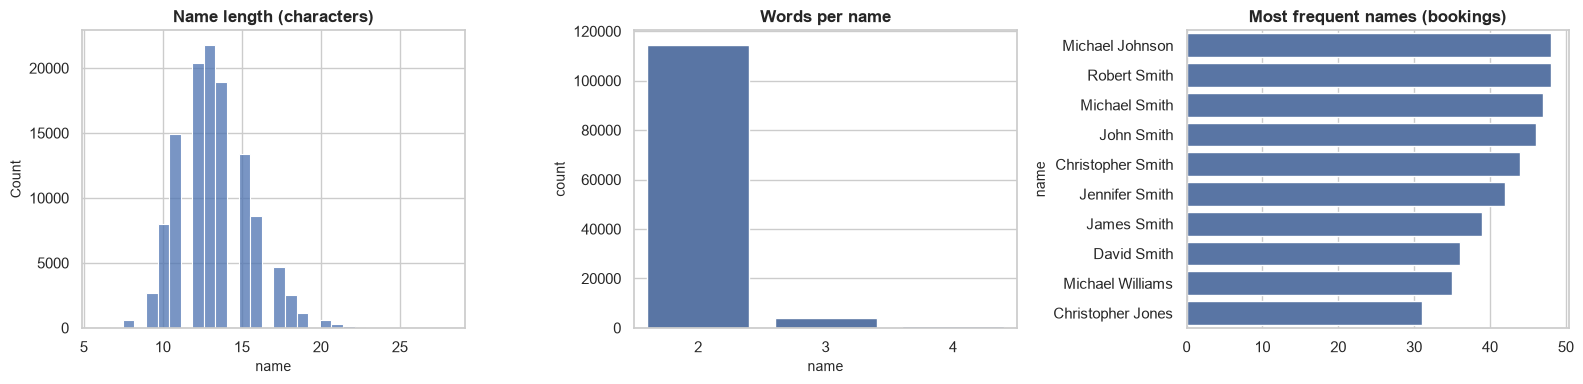

INSIGHTS
  - 18,619 names appear in more than one booking (most frequent: "Michael Johnson" with 48 bookings): common names, not necessarily the same guest.


In [97]:
nm = hotel['name']
print('Unique names:', nm.nunique(), 'of', len(nm), '| missing:', int(nm.isna().sum()))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(nm.str.len(), bins=30, color=BLUE, ax=ax[0]); ax[0].set_title('Name length (characters)')
sns.countplot(x=nm.str.split().str.len(), color=BLUE, ax=ax[1]); ax[1].set_title('Words per name')
top = nm.value_counts().head(10); sns.barplot(x=top.values, y=top.index, color=BLUE, orient='h', ax=ax[2]); ax[2].set_title('Most frequent names (bookings)')
plt.tight_layout(); plt.show()
print('INSIGHTS')
print(f'  - {int((nm.value_counts() > 1).sum()):,} names appear in more than one booking (most frequent: "{top.index[0]}" with {top.iloc[0]} bookings): common names, not necessarily the same guest.')

### 3.4.34 `email`
**Description:** guest e-mail address (personal data).

**Cleaning:** format validated; domain extracted into `email_domain`; raw column dropped from the final dataset.

Unique e-mails: 115720 of 119209 | invalid format: 0


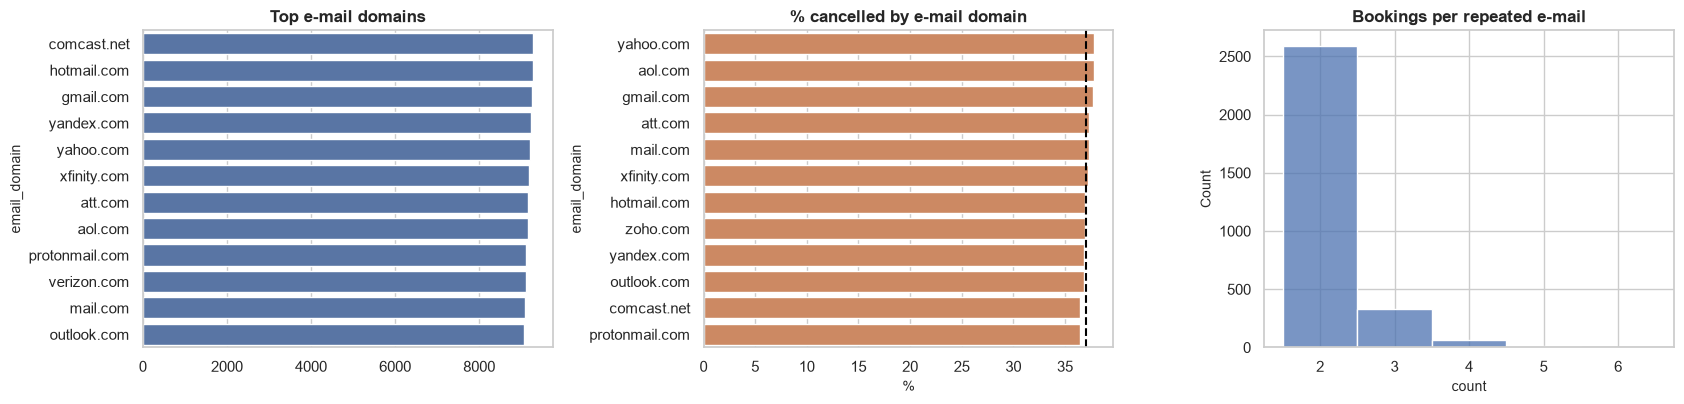

INSIGHTS
  - 13 distinct domains; top domain "comcast.net" holds 7.8% of bookings.
  - 2,996 e-mail addresses are used in more than one booking.


In [98]:
em = hotel['email']
print('Unique e-mails:', em.nunique(), 'of', len(em), '| invalid format:', int((~em.str.match(r'^[\w.+-]+@[\w-]+\.[\w.]+$')).sum()))
dom = hotel['email_domain'].value_counts()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.barplot(x=dom.head(12).values, y=dom.head(12).index, color=BLUE, orient='h', ax=ax[0]); ax[0].set_title('Top e-mail domains')
rate = hotel.groupby('email_domain')['is_canceled'].agg(['mean', 'size']); rate = rate[rate['size'] >= 100].sort_values('mean', ascending=False).head(12)
sns.barplot(x=rate['mean'] * 100, y=rate.index, color=ORANGE, orient='h', ax=ax[1]); ax[1].axvline(hotel['is_canceled'].mean() * 100, color='black', ls='--'); ax[1].set_title('% cancelled by e-mail domain'); ax[1].set_xlabel('%')
rep = em.value_counts(); sns.histplot(rep[rep > 1], discrete=True, color=BLUE, ax=ax[2]); ax[2].set_title('Bookings per repeated e-mail')
plt.tight_layout(); plt.show()
print('INSIGHTS')
print(f'  - {dom.shape[0]} distinct domains; top domain "{dom.index[0]}" holds {dom.iloc[0] / len(hotel) * 100:.1f}% of bookings.')
print(f'  - {int((rep > 1).sum()):,} e-mail addresses are used in more than one booking.')

### 3.4.35 `phone-number`
**Description:** guest phone number (personal data).

**Cleaning:** format validated; raw column dropped from the final dataset.

Unique numbers: 119209 of 119209 | invalid format: 0


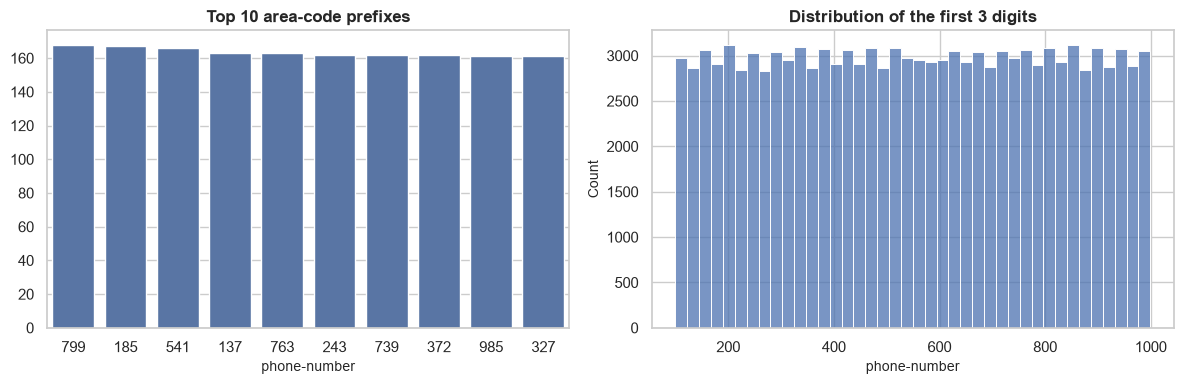

INSIGHTS
  - Every number follows the NNN-NNN-NNNN pattern and is unique to one booking; the column is an identifier with no analytical value.


In [99]:
ph = hotel['phone-number']
valid = ph.str.match(r'^\d{3}-\d{3}-\d{4}$')
print('Unique numbers:', ph.nunique(), 'of', len(ph), '| invalid format:', int((~valid).sum()))
area = ph.str[:3]; top = area.value_counts().head(10)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=top.index, y=top.values, color=BLUE, ax=ax[0]); ax[0].set_title('Top 10 area-code prefixes')
sns.histplot(area.astype(int), bins=40, color=BLUE, ax=ax[1]); ax[1].set_title('Distribution of the first 3 digits')
plt.tight_layout(); plt.show()
print('INSIGHTS\n  - Every number follows the NNN-NNN-NNNN pattern and is unique to one booking; the column is an identifier with no analytical value.')

### 3.4.36 `credit_card`
**Description:** masked card number (only the last 4 digits are visible).

**Cleaning:** format validated; `card_bookings` (bookings per card) created; raw column dropped from the final dataset.

Unique masked cards: 9000 of 119209 | invalid format: 0


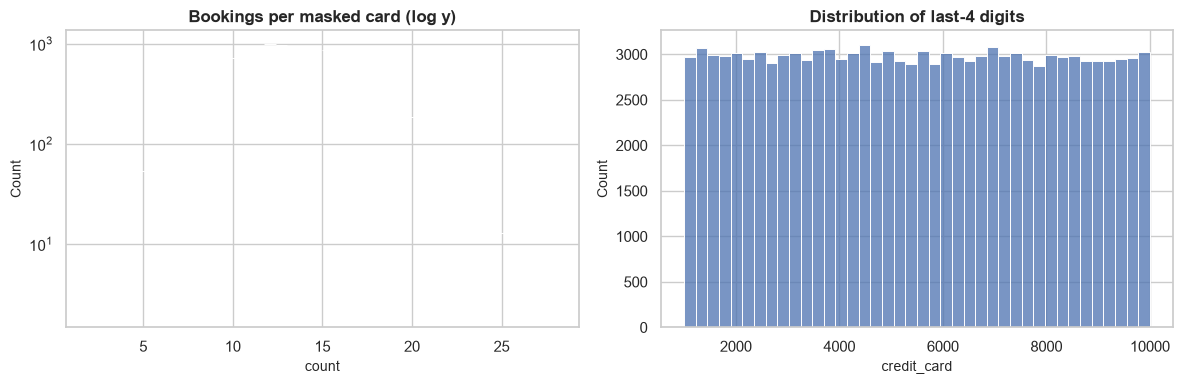

INSIGHTS
  - Only 9,000 distinct masked numbers for 119,209 bookings, so one card appears in about 13.2 bookings on average (max 28). Because only 4 digits are kept, different guests can share the same masked value.
  - Sensitive data: the column is removed from the final dataset.


In [100]:
cc = hotel['credit_card']
print('Unique masked cards:', cc.nunique(), 'of', len(cc), '| invalid format:', int((~cc.str.match(r'^\*{12}\d{4}$')).sum()))
per = cc.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(per, bins=40, log_scale=(False, True), color=BLUE, ax=ax[0]); ax[0].set_title('Bookings per masked card (log y)')
sns.histplot(cc.str[-4:].astype(int), bins=40, color=BLUE, ax=ax[1]); ax[1].set_title('Distribution of last-4 digits')
plt.tight_layout(); plt.show()
print('INSIGHTS')
print(f'  - Only {cc.nunique():,} distinct masked numbers for {len(cc):,} bookings, so one card appears in about {per.mean():.1f} bookings on average (max {per.max()}). Because only 4 digits are kept, different guests can share the same masked value.')
print('  - Sensitive data: the column is removed from the final dataset.')

## 3.5 Multivariate analysis

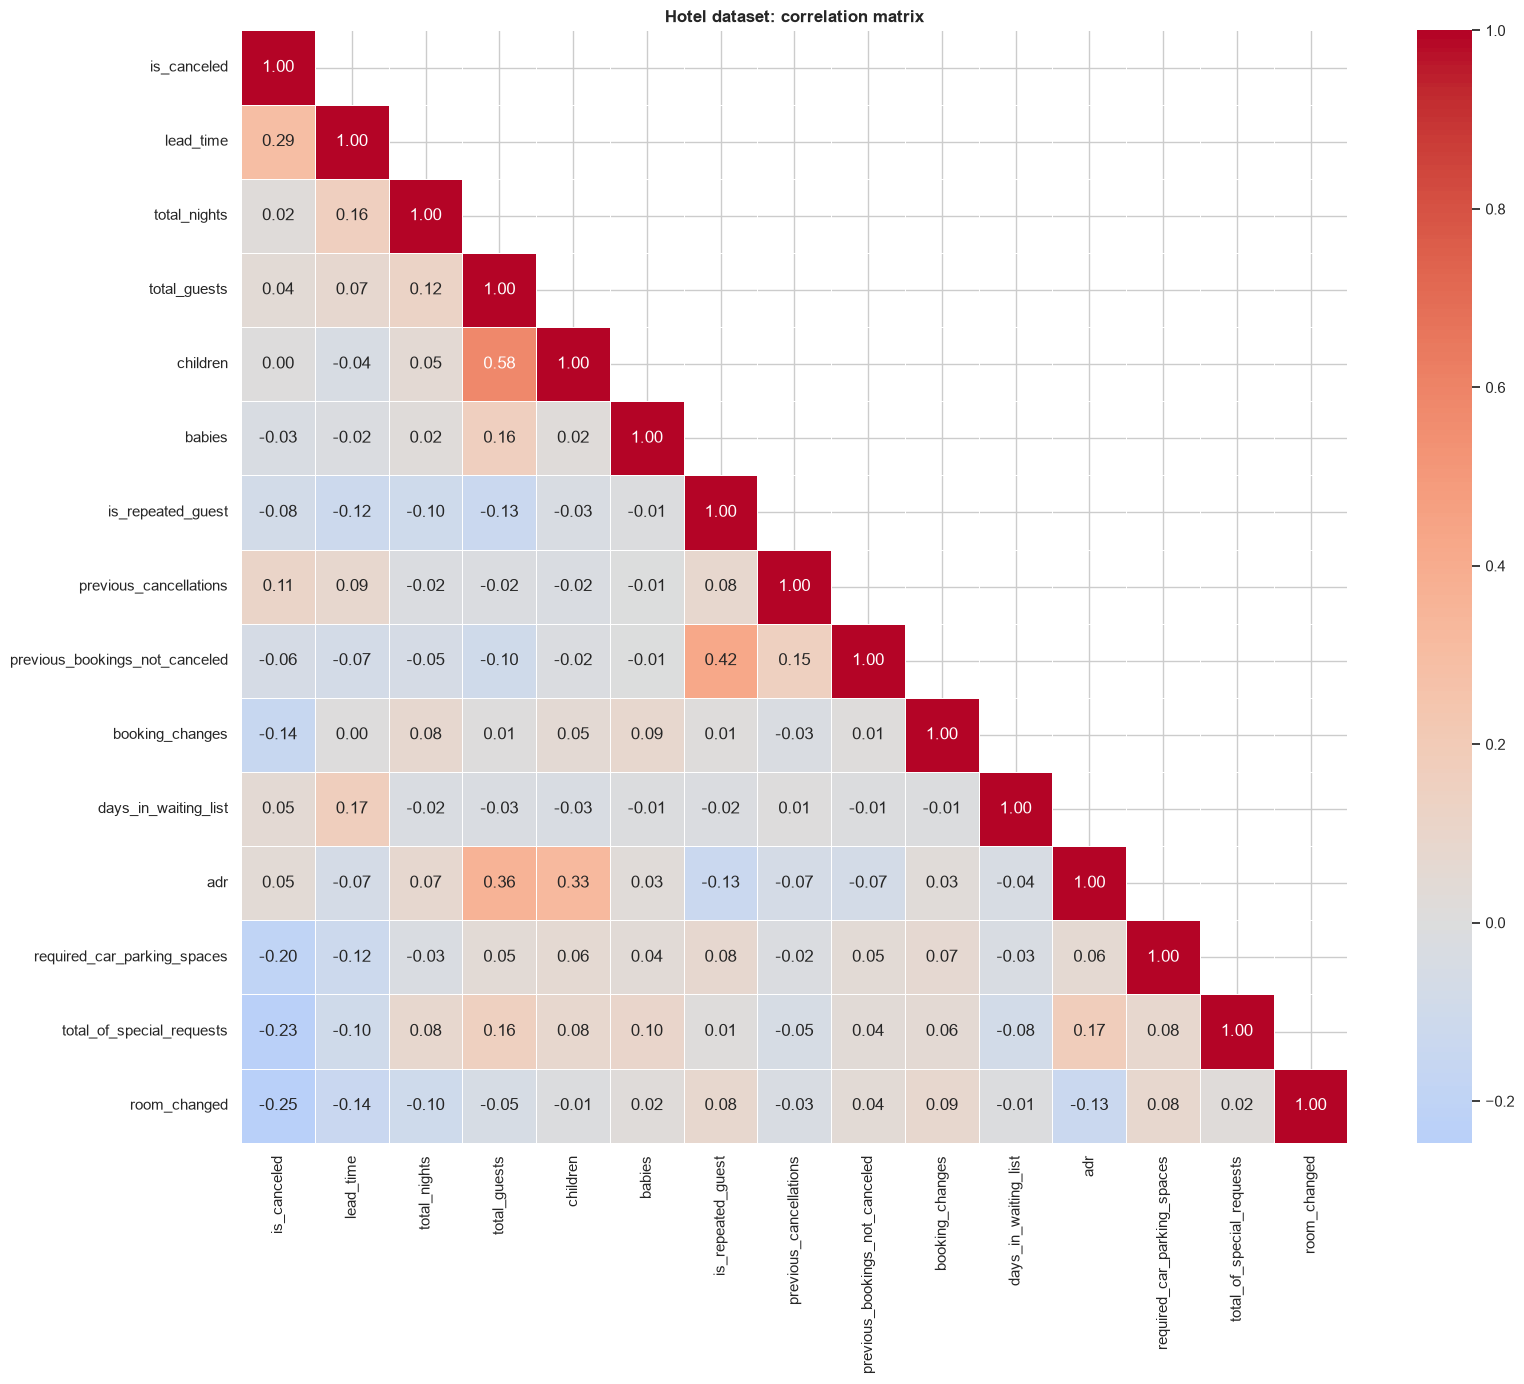

,corr with is_canceled
lead_time,0.293
previous_cancellations,0.110
days_in_waiting_list,0.054
adr,0.046
total_guests,0.045
total_nights,0.019
children,0.005
babies,-0.033
previous_bookings_not_canceled,-0.057
is_repeated_guest,-0.084


In [101]:
num_cols = ['is_canceled', 'lead_time', 'total_nights', 'total_guests', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations',
            'previous_bookings_not_canceled', 'booking_changes', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'room_changed']
corr_hotel = corr_heatmap(hotel, num_cols, 'Hotel dataset: correlation matrix')
display(corr_hotel['is_canceled'].drop('is_canceled').sort_values(ascending=False).to_frame('corr with is_canceled'))

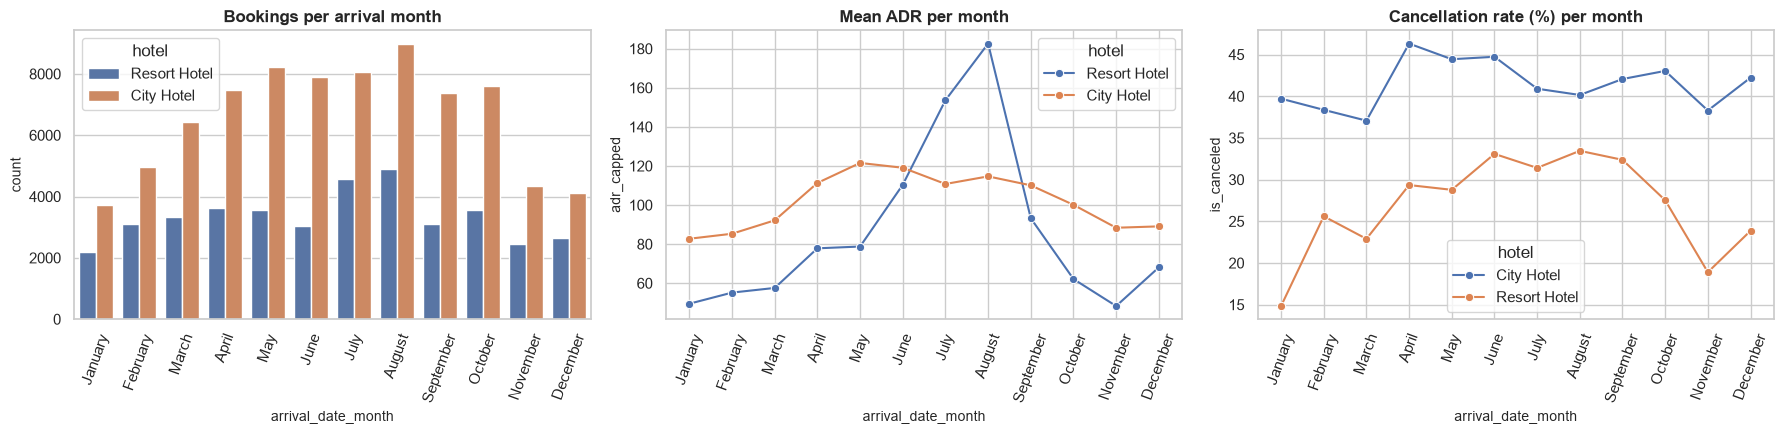

In [102]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.countplot(data=hotel, x='arrival_date_month', hue='hotel', ax=ax[0]); ax[0].set_title('Bookings per arrival month'); ax[0].tick_params(axis='x', rotation=70)
sns.lineplot(data=hotel, x='arrival_date_month', y='adr_capped', hue='hotel', estimator='mean', errorbar=None, marker='o', ax=ax[1]); ax[1].set_title('Mean ADR per month'); ax[1].tick_params(axis='x', rotation=70)
cr = hotel.groupby(['arrival_date_month', 'hotel'])['is_canceled'].mean().mul(100).reset_index()
sns.lineplot(data=cr, x='arrival_date_month', y='is_canceled', hue='hotel', marker='o', ax=ax[2]); ax[2].set_title('Cancellation rate (%) per month'); ax[2].tick_params(axis='x', rotation=70)
plt.tight_layout(); plt.show()

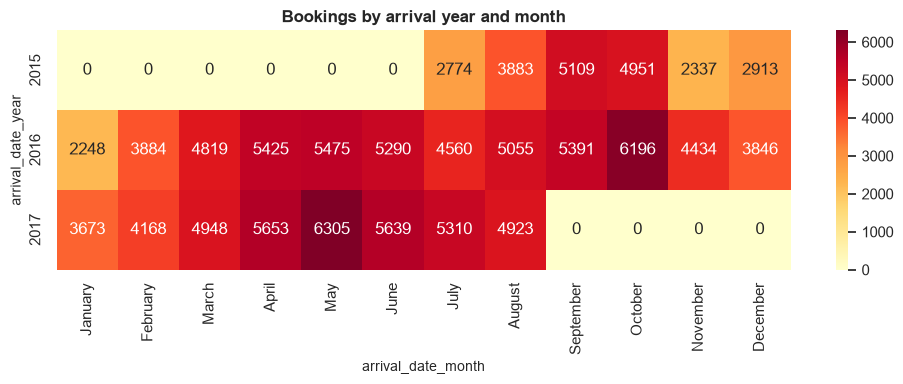

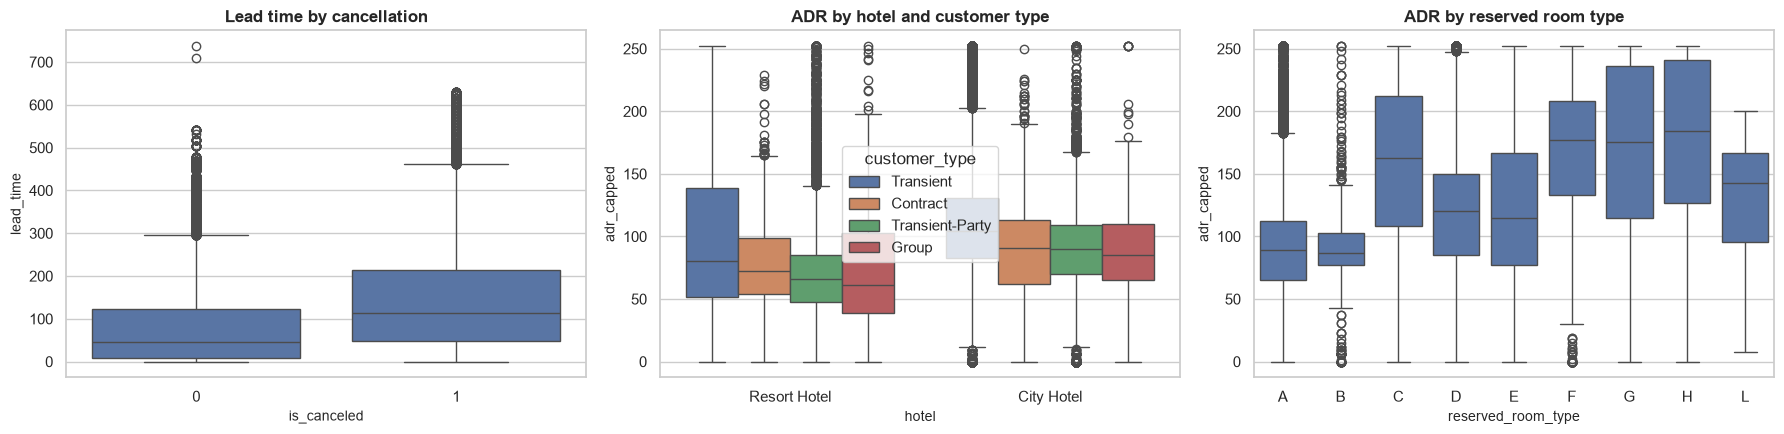

In [103]:
plt.figure(figsize=(10, 4))
sns.heatmap(pd.crosstab(hotel['arrival_date_year'], hotel['arrival_date_month']), annot=True, fmt='d', cmap='YlOrRd')
plt.title('Bookings by arrival year and month'); plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=hotel, x='is_canceled', y='lead_time', ax=ax[0]); ax[0].set_title('Lead time by cancellation')
sns.boxplot(data=hotel, x='hotel', y='adr_capped', hue='customer_type', ax=ax[1]); ax[1].set_title('ADR by hotel and customer type')
sns.boxplot(data=hotel, x='reserved_room_type', y='adr_capped', color=BLUE, order=sorted(hotel['reserved_room_type'].unique()), ax=ax[2]); ax[2].set_title('ADR by reserved room type')
plt.tight_layout(); plt.show()

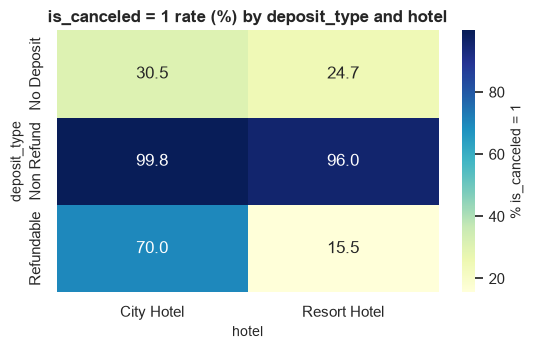

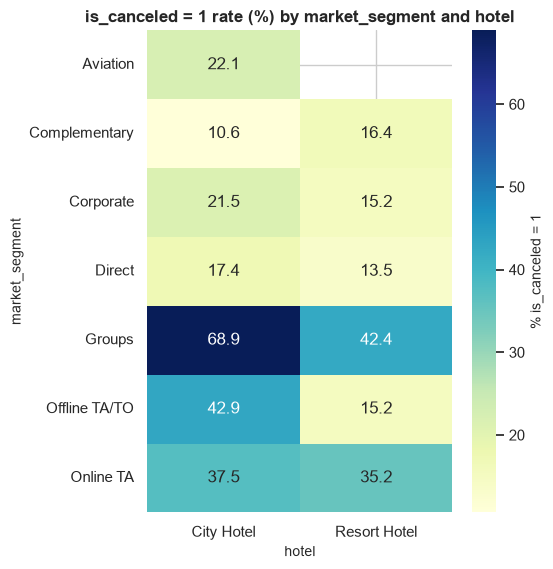

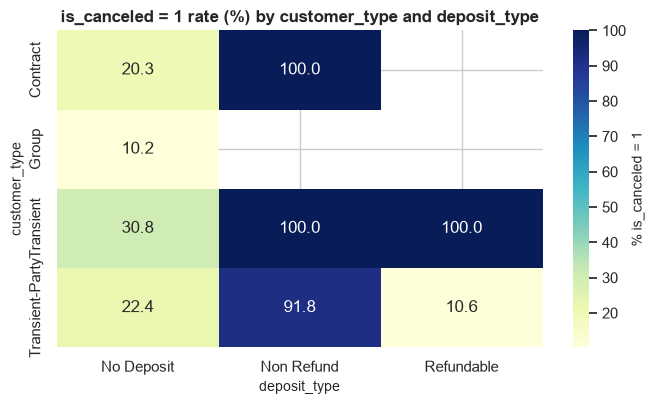

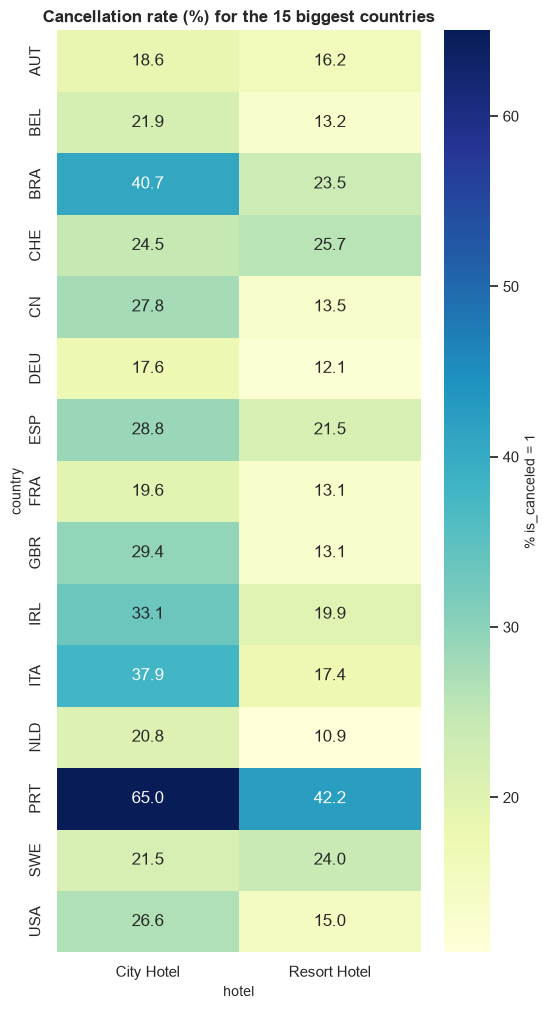

In [104]:
rate_heatmap(hotel, 'deposit_type', 'hotel', 'is_canceled', 1)
rate_heatmap(hotel, 'market_segment', 'hotel', 'is_canceled', 1)
rate_heatmap(hotel, 'customer_type', 'deposit_type', 'is_canceled', 1)
top_c = hotel['country'].value_counts().head(15).index
rate_heatmap(hotel[hotel['country'].isin(top_c)], 'country', 'hotel', 'is_canceled', 1, 'Cancellation rate (%) for the 15 biggest countries', min_count=50)

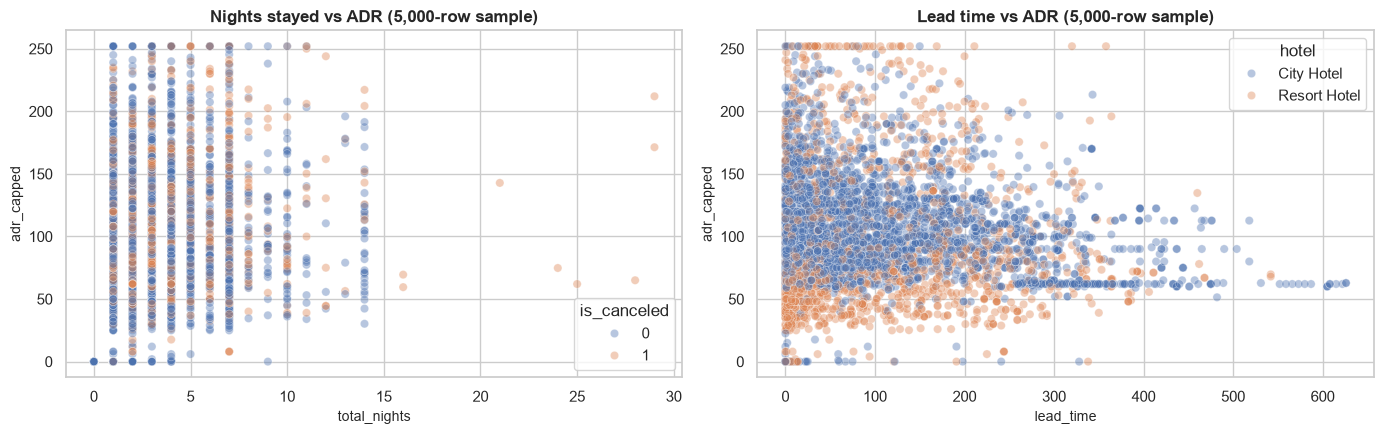

Leakage check - is_canceled vs reservation_status:


reservation_status,Canceled,Check-Out,No-Show
is_canceled,,,
0,0,75010,0
1,42993,0,1206


In [105]:
s = hotel.sample(5000, random_state=1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(data=s, x='total_nights', y='adr_capped', hue='is_canceled', alpha=.4, ax=ax[0]); ax[0].set_title('Nights stayed vs ADR (5,000-row sample)')
sns.scatterplot(data=s, x='lead_time', y='adr_capped', hue='hotel', alpha=.4, ax=ax[1]); ax[1].set_title('Lead time vs ADR (5,000-row sample)')
plt.tight_layout(); plt.show()
print('Leakage check - is_canceled vs reservation_status:'); display(pd.crosstab(hotel['is_canceled'], hotel['reservation_status']))

## 3.6 Key findings & export: Hotel dataset

In [106]:
cr_h = hotel.groupby('hotel')['is_canceled'].mean() * 100
dp = hotel.groupby('deposit_type')['is_canceled'].mean() * 100
ms = hotel.groupby('market_segment')['is_canceled'].agg(['mean', 'size']); ms = ms[ms['size'] >= 100]['mean'] * 100
print(f'1. Overall cancellation rate: {hotel.is_canceled.mean()*100:.1f}%  (City Hotel {cr_h["City Hotel"]:.1f}% vs Resort Hotel {cr_h["Resort Hotel"]:.1f}%).')
print('2. Cancellation rate by deposit type: ' + ', '.join(f'{k} {v:.1f}%' for k, v in dp.items()) + '.')
print(f'3. Median lead time: cancelled = {hotel.loc[hotel.is_canceled==1, "lead_time"].median():.0f} days vs not cancelled = {hotel.loc[hotel.is_canceled==0, "lead_time"].median():.0f} days.')
print(f'4. Market segment with the highest cancellation rate: {ms.idxmax()} ({ms.max():.1f}%); lowest: {ms.idxmin()} ({ms.min():.1f}%).')
mm = hotel.groupby('arrival_date_month')['adr'].mean()
print(f'5. Mean ADR is highest in {mm.idxmax()} ({mm.max():.1f}) and lowest in {mm.idxmin()} ({mm.min():.1f}).')
print(f'6. Cleaning summary: {len(hotel_raw) - len(hotel)} rows removed; {int(hotel_raw.isna().sum().sum()):,} missing cells handled; "company" was {hotel_raw["company"].isna().mean()*100:.0f}% missing.')
print(f'7. {int(hotel.zero_night_stay.sum())} bookings have 0 nights (flagged) and {int(hotel.room_changed.sum()):,} bookings ({hotel.room_changed.mean()*100:.1f}%) got a different room type than reserved.')
print('8. reservation_status duplicates the target (data leakage) and must be excluded from predictive models.')

hotel_final = hotel.drop(columns=['name', 'email', 'phone-number', 'credit_card'])
hotel_final.to_csv('data/hotel_booking_cleaned.csv', index=False)
print('\nPII columns removed. Cleaned data saved to data/hotel_booking_cleaned.csv ->', hotel_final.shape)

1. Overall cancellation rate: 37.1%  (City Hotel 41.8% vs Resort Hotel 27.8%).
2. Cancellation rate by deposit type: No Deposit 28.4%, Non Refund 99.4%, Refundable 22.2%.
3. Median lead time: cancelled = 113 days vs not cancelled = 45 days.
4. Market segment with the highest cancellation rate: Groups (61.1%); lowest: Complementary (12.2%).
5. Mean ADR is highest in August (140.3) and lowest in January (70.5).
6. Cleaning summary: 181 rows removed; 129,425 missing cells handled; "company" was 94% missing.
7. 645 bookings have 0 nights (flagged) and 14,795 bookings (12.4%) got a different room type than reserved.
8. reservation_status duplicates the target (data leakage) and must be excluded from predictive models.

PII columns removed. Cleaned data saved to data/hotel_booking_cleaned.csv -> (119209, 51)


**Conclusion (Hotel):** missing values, placeholders (`Undefined`), impossible bookings, outliers, date types and personal data were handled; every one of the 36 original columns was analysed individually. Overall 37.1% of bookings are cancelled (City Hotel 41.8% vs Resort Hotel 27.8%). Cancelled bookings have a much longer median lead time (113 vs 45 days), `Non Refund` deposits are cancelled 99.4% of the time (an unusual pattern worth questioning rather than trusting), and `reservation_status` leaks the target. ADR peaks in August and is lowest in January.

---
# Overall summary
| Dataset | Rows (raw -> clean) | Columns analysed | Main cleaning actions |
|---|---|---|---|
| Loan | 1,614 -> 1,614 | 13 + engineered features | imputed missing values, flagged repeated IDs, capped outliers |
| Adult | 48,842 -> 48,790 | 15 + engineered features | `?` -> NaN / `Unknown`, removed duplicates, capped outliers |
| Hotel | 119,390 -> 119,209 | 36 + engineered features | filled missing, fixed `Undefined`, removed impossible rows, dropped PII |

Cleaned files created: `loan_cleaned.csv`, `adult_cleaned.csv`, `hotel_booking_cleaned.csv`.